# Sistema inteligente de análisis y predicción de mercados financieros

### Predicción de días de movimiento grande con precios y noticias

**Proyecto final — Fundamentos del Aprendizaje Automático**

| | |
|---|---|
| **Autor** | Christian Tamayo |
| **Profesor** | Felipe Grijalva |
| **Repositorio** | [github.com/Chr1stianTamayo/proyecto-final-ml-mercados](https://github.com/Chr1stianTamayo/proyecto-final-ml-mercados) |
| **Abrir en Colab** | [Proyecto_Final_ML_Mercados.ipynb en Google Colab](https://colab.research.google.com/github/Chr1stianTamayo/proyecto-final-ml-mercados/blob/main/Proyecto_Final_ML_Mercados.ipynb) |
| **Entorno** | Google Colab, con GPU para la extracción de *embeddings* |

### Mapa del código: las piezas que sostienen el experimento

| Función o clase | Sección | Qué hace |
|---|---|---|
| `descargar_precios`, `cargar_noticias` | 2.1 | Obtienen precios y titulares de sus fuentes públicas y los guardan en `datos/` |
| `caracteristicas_al_cierre` | 3.1 | Calcula las variables de precio y volumen con información hasta el cierre de cada sesión |
| `extraer_finbert` | 3.3 | Convierte cada titular en un vector de 768 dimensiones (token `[CLS]`) y un valor de sentimiento |
| `particion_por_fechas` | 4.1 | Genera los 10 pliegues cronológicos por fechas únicas con brecha de 5 sesiones |
| `CausalWinsorizer` | 4.2 | Recorta cada variable a cuantiles aprendidos solo en `fit` |
| `crear_preprocesador` | 4.3 | Arma el `ColumnTransformer` de seis ramas; el filtro actúa solo sobre precio y volumen |
| `crear_baseline`, `crear_modelo` | 6.1 | Devuelven el *pipeline* completo: preprocesador y clasificador |
| `espacio`, `optimizar` | 6.2 | Definen el espacio de búsqueda y ejecutan Optuna sobre los pliegues |
| `punto_curva` | 6.4 | Ajusta un modelo con las *m* sesiones más recientes para la curva de aprendizaje |
| `metricas` | 7.4 | Calcula todas las métricas de clasificación que pide la rúbrica |
| `simular` | 7.5 | Simula la cartera que sale de cada acción en sus días con alerta |
| `pureza_vecindad` | 8.1 | Mide cuánto se agrupan las etiquetas en el plano de t-SNE |

## 0. Configuración y reproducibilidad

Todas las constantes del experimento se declaran una sola vez aquí. Ningún número que afecte un resultado aparece escrito a mano más abajo.

- **Semilla.** Se fija una única semilla para NumPy, scikit-learn, Optuna y PyTorch. Al ejecutar la libreta dos veces desde cero en el mismo equipo, los datos descargados, las referencias, el *baseline* y la regresión logística (M0) se reprodujeron idénticos. El *boosting* (M1) varió en el tercer o cuarto decimal de su pérdida, porque sus particiones son sensibles a diferencias mínimas de redondeo; en otro equipo o con GPU pueden aparecer diferencias de ese orden también en las demás cifras. Por eso los textos de diagnóstico y las conclusiones se generan con los valores de cada ejecución.
- **Ventana temporal.** 2015-01-01 a 2023-12-15. El límite superior lo impone el conjunto de noticias FNSPID, cuya última fecha es el 16 de diciembre de 2023.
- **Umbral de la etiqueta.** $u = 1\,\%$: un día cuenta como «movimiento grande» si el retorno absoluto supera ese valor. Se fijó de antemano y no se optimiza.
- **Costo de transacción.** 5 puntos básicos por operación en la evaluación económica.
- **Validación.** $K = 10$ pliegues cronológicos con una brecha de 5 sesiones.

In [1]:
# =============================================================================================
# USO DE IA EN ESTA LIBRETA: REGISTRO DE PROMPTS
# Herramienta: un asistente de IA. Generó el código de todas las celdas. La declaración completa, con lo
# que hizo el autor, está al final de la sección 10.
#
# Cómo leer el comentario «[Uso de IA]» que encabeza cada celda de código:
#   - «prompts» lista, en orden, todos los prompts de este registro que crearon o modificaron la celda.
#   - «Instrucción» cita el fragmento del documento de implementación que la celda cumple. Ese documento
#     (`prompt-maestro-implementacion-proyecto.md`, que la IA leyó por el prompt P1) es la especificación
#     del proyecto. Las citas son literales: solo se quitaron las marcas de formato y de notación
#     matemática, y «[…]» señala texto omitido.
#   - «Difiere» dice dónde lo construido se apartó de esa instrucción y por qué.
#
# Se transcriben los prompts que generaron o modificaron código. Los intercambios que no produjeron
# código (la lectura previa de la rúbrica y de las directrices del proyecto, que es el «Paso 1» que
# menciona P1, y las preguntas de auditoría) no se transcriben. Entre «» va el texto literal del autor;
# lo que sigue a la flecha resume lo implementado.
#
# P1: «Una vez confirmado el Paso 1, leerás `prompt-maestro-implementacion-proyecto.md` y me presentarás
#      el índice celda por celda estructurado para Google Colab (.ipynb) según las 10 secciones de la
#      rúbrica oficial de Notion, asegurando que cada bloque de código tenga su celda de Markdown previa
#      con justificación matemática.»
# P2: «Sí, constrúyela» -> implementar en código el índice de secciones aprobado en P1. Durante la
#      construcción se comprobó que FNSPID no cubre 2015–2021 para las acciones previstas; entre las
#      opciones planteadas, el autor eligió «Cambiar las 5 acciones» (decisión de datos).
# P3: «Sí, cámbiala» -> reformular la tarea: de la dirección del retorno a predecir días con movimiento
#      absoluto superior al 1 %. La primera formulación no superaba la referencia sin habilidad: su
#      exactitud quedó cerca del 50 % con clases balanceadas, lo que no demuestra aprendizaje.
# P4: «Sí, corrígelas», «Tengo 3 cuestionamientos: […]» y «Sí, añádelo» -> correcciones tras tres rondas
#      de preguntas de auditoría del autor: el filtro deja fuera todo lo derivado de FinBERT, el EDA no
#      ajusta ningún transformador, las dos pruebas de hipótesis se leen juntas, la tabla de la prueba
#      ciega explica sus referencias, bandas de ±1σ, respuestas explícitas del EDA y sección 3.6.
# P5: «Sí, aplícalos» -> tras otra auditoría pedida por el autor: AUC macro y micro, contraste de cada
#      modelo contra las referencias e intervalos por remuestreo de bloques.
# P6: «añade todas las mejoras que hayas identificado en todos estos análisis» -> baseline simple con
#      parámetros por defecto, diagrama de calibración, razón de Sortino, sumas de control de los datos,
#      mapa del código y limitaciones adicionales.
# =============================================================================================
# [Uso de IA] Celda generada con un asistente de IA · sección 0 · prompt: P2.
# Sin instrucción específica en el documento: celda de entorno, instala lo que Colab no trae.
import subprocess
import sys

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # Colab ya trae pandas, scikit-learn, statsmodels, torch y transformers; solo se añade lo que falta.
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U",
                    "yfinance", "optuna", "wordcloud", "nltk"], check=True)

In [2]:
# [Uso de IA] Celda generada con un asistente de IA · sección 0 · prompts: P2, P3, P4.
# Instrucción (fases 1 y 3): «Panel de 10 años (2015–2024) de 5 activos tecnológicos líderes (AAPL, MSFT,
#   NVDA, GOOGL, AMZN) y el benchmark de mercado (SPY) extraídos con `yfinance`»
#   «Aislamiento del Hold-out Test: Bloque histórico 2015–2022 (80%) para desarrollo y validación cruzada;
#   bloque 2023–2024 (20%) aislado como conjunto ciego de prueba final.»
# Difiere: se usan ADBE, CRM, MU, ORCL y TXN, con ventana 2015–2023 y prueba ciega 2022–2023, porque FNSPID
#   no cubre 2015–2021 para las acciones previstas y termina en diciembre de 2023 (decisión de datos); el
#   umbral de la etiqueta es 1 % en valor absoluto y no 5 puntos básicos.
import csv
import io
import os
import random
import re
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import scipy
import sklearn
import yfinance as yf
from cycler import cycler
from IPython.display import Markdown, display

os.environ["TOKENIZERS_PARALLELISM"] = "false"   # evita avisos al paralelizar después de usar FinBERT

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# --- Universo y ventana temporal -------------------------------------------------------
TICKERS = ["ADBE", "CRM", "MU", "ORCL", "TXN"]   # cinco tecnológicas con noticias todos los años
REFERENCIA = "SPY"                                # mercado: variables de contexto y comparación
FECHA_DESCARGA = "2014-06-01"                     # margen para calentar medias móviles y EMA
FECHA_INICIO = "2015-01-01"                       # primera sesión objetivo
FECHA_CORTE = "2022-01-01"                        # desde aquí todo es conjunto de prueba ciego
FECHA_FIN = "2023-12-15"                          # última sesión objetivo (límite de FNSPID)

# --- Definición del problema y del protocolo -------------------------------------------
UMBRAL = 0.01         # umbral de la etiqueta: movimiento absoluto superior al 1 %
COSTO_PB = 5          # costo de transacción base, en puntos básicos
BRECHA = 5            # sesiones purgadas entre entrenamiento y validación
K_PLIEGUES = 10       # pliegues cronológicos pareados
N_PRUEBAS = 30        # evaluaciones de Optuna por modelo
ALFA = 0.05           # nivel de significancia

CARPETA = Path("datos")
CARPETA.mkdir(exist_ok=True)

# --- Estilo de gráficos: paleta categórica fija, apta para daltonismo -------------------
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
COLOR_TICKER = dict(zip(TICKERS, PALETA))
C_ENT, C_VAL, C_REF = "#2a78d6", "#eb6834", "#898781"   # entrenamiento, validación, referencia
SECUENCIAL = ["#9ec5f4", "#3987e5", "#104281"]            # un solo tono, claro a oscuro
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "lines.linewidth": 2, "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "legend.frameon": False, "figure.dpi": 110,
    "axes.prop_cycle": cycler(color=PALETA),
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")


def p_txt(p, signo="="):
    """Texto de un p-valor: los muy pequeños se escriben como «p < 0.0001», nunca como 0.0000."""
    return "p < 0.0001" if p < 1e-4 else f"p {signo} {p:.4f}"

print(f"Python {sys.version.split()[0]} | NumPy {np.__version__} | pandas {pd.__version__} | "
      f"scikit-learn {sklearn.__version__} | SciPy {scipy.__version__}")

Python 3.11.16 | NumPy 1.26.4 | pandas 3.0.6 | scikit-learn 1.9.1 | SciPy 1.17.1


## 1. Introducción

### 1.1 Contexto del problema

Quien gestiona una cartera de acciones se hace dos preguntas distintas sobre el día siguiente: **hacia dónde** se moverá el precio y **cuánto** se moverá. La primera es casi imposible de responder: la hipótesis de mercados eficientes sostiene que el precio ya incorpora la información pública, y el retorno de un día apenas guarda relación con los anteriores. La segunda sí tiene estructura: los días agitados tienden a venir seguidos de días agitados. Este hecho, el **agrupamiento de la volatilidad** [1], [2], es uno de los más estables de las series financieras.

Anticipar un día de movimiento grande es útil aunque no se conozca su dirección. Permite reducir el tamaño de una posición, ajustar un límite de pérdida o contratar cobertura antes de que el riesgo se materialice. Un sistema que avise con una sesión de anticipación «mañana es probable un movimiento fuerte en esta acción» es una herramienta de **gestión de riesgo**.

El problema importa también por una razón metodológica: las series financieras son el caso donde más fácil resulta engañarse. Un modelo que usa por error un dato del futuro muestra métricas espectaculares que desaparecen al operar. Por eso este proyecto prioriza un diseño experimental sin fuga de información.

### 1.2 Planteamiento formal (Mitchell)

Según Mitchell [3], un programa aprende de la experiencia $E$ respecto a una tarea $T$ y una medida de rendimiento $P$ si su desempeño en $T$, medido con $P$, mejora con $E$.

**Tarea $T$.** Clasificar, para cada acción $i$ y cada sesión $t$, si el valor absoluto de su retorno logarítmico diario superará el umbral $u$:

$$y_{i,t} = \mathbb{I}\left(\lvert r_{i,t}\rvert > u\right), \qquad r_{i,t} = \ln\frac{P_{i,t}}{P_{i,t-1}}, \qquad u = 0.01$$

El modelo entrega una probabilidad $\hat p_{i,t} = P(y_{i,t} = 1 \mid \mathbf{x}_{i,t})$, donde $\mathbf{x}_{i,t}$ solo contiene información disponible al cierre de la sesión $t-1$.

- *Por qué 1 %.* Es un valor redondo que deja las clases casi balanceadas en el período de desarrollo (sección 2.3). Se eligió por esa razón y no se ajustó para mejorar ninguna métrica.
- *Por qué la magnitud y no la dirección.* El EDA (sección 2.5) muestra que el retorno casi no se autocorrelaciona, mientras que su valor absoluto sí lo hace de forma persistente. Una formulación previa de este proyecto, con la dirección del retorno como etiqueta, no superó la referencia sin habilidad; se documenta en las limitaciones (sección 9).

**Experiencia $E$.** Un panel diario de cinco acciones tecnológicas de gran capitalización (ADBE, CRM, MU, ORCL, TXN) entre 2015 y 2023, con dos modalidades:

- *Serie de tiempo:* precios de apertura, máximo, mínimo, cierre y volumen, obtenidos con `yfinance`, más el fondo SPY como referencia del mercado.
- *Texto:* titulares de noticias del conjunto público FNSPID [4], convertidos en vectores con el modelo preentrenado FinBERT [5].

El número exacto de observaciones $m$ y de atributos $n$ se reporta en la sección 3.5, después de construir la matriz.

**Rendimiento $P$.** Se distinguen tres niveles:

- *Función de pérdida optimizada:* entropía cruzada binaria (*log-loss*), $J = -\frac{1}{m}\sum_{j}\left[y_j \ln \hat p_j + (1-y_j)\ln(1-\hat p_j)\right]$. Es la métrica rectora porque evalúa la probabilidad completa, no solo el lado del umbral. Un modelo que no aprende nada y predice siempre $0.5$ obtiene $J = \ln 2 \approx 0.693$.
- *Métricas técnicas:* sensibilidad (de los días agitados, cuántos se anticiparon: no avisar deja la cartera expuesta), precisión (de las alertas, cuántas fueron ciertas: una falsa alarma cuesta una cobertura innecesaria), F1 macro, MCC, AUC y las demás métricas que pide la rúbrica.
- *Métricas de negocio:* razón de Sharpe y máxima caída de una cartera que reduce su exposición en los días con alerta, netas de costos.

Como las clases están casi balanceadas, la exactitud (*accuracy*) es interpretable y se compara siempre con la de predecir la clase mayoritaria, que ronda el 50 %. Aun así, las decisiones se toman con el *log-loss*.

### 1.3 Resumen de lo que se hace

El flujo sigue el diagrama visto en clase: **extracción de características → selección de características (solo datos tabulares) → modelo**, con t-SNE para visualizar el espacio que recibe el modelo.

1. Se descargan precios y noticias, y se aparta el período 2022–2023 como prueba ciega antes de explorar nada.
2. Se responde el EDA con los datos de desarrollo (2015–2021).
3. Se extraen rezagos causales de la serie de tiempo y *embeddings* de FinBERT de los titulares.
4. Todo el preprocesamiento se encapsula en un `Pipeline` que se ajusta únicamente con datos de entrenamiento.
5. Se optimizan dos técnicas —regresión logística con red elástica y *gradient boosting*— sobre 10 pliegues cronológicos.
6. Se comparan con una prueba de hipótesis pareada, se evalúan una sola vez en la prueba ciega y se mide su valor en una estrategia de gestión de riesgo.

## 2. Datos y análisis exploratorio (EDA)

### 2.1 Fuentes públicas y carga

**Precios.** `yfinance` [6] entrega precios ajustados por dividendos y divisiones. Se descarga desde junio de 2014 para que los indicadores con memoria (medias móviles, EMA) ya estén estabilizados en la primera sesión objetivo de 2015.

**Noticias.** FNSPID [4] publica sus noticias en un archivo CSV de 23 GB ordenado por símbolo bursátil. Como el archivo está ordenado, no hace falta descargarlo entero: una **búsqueda binaria** con peticiones HTTP parciales (`Range`) localiza el bloque de cada símbolo en unos 17 pasos, porque $\lceil \log_2(17.3\times10^{9} / 1.5\times10^{5}) \rceil = 17$. Después se descarga solo ese bloque (menos de 70 MB por acción).

**Por qué estas cinco acciones.** Antes de fijar el universo se midió la cobertura de FNSPID. Las acciones más mediáticas (AAPL, MSFT, AMZN) solo conservan sus artículos más recientes, de 2022 en adelante, así que no permiten entrenar con texto. ADBE, CRM, MU, ORCL y TXN tienen titulares en todos los años de la ventana. Esta elección se hizo con la cobertura de noticias, no con los retornos, por lo que no introduce sesgo de selección sobre la etiqueta.

Ambas descargas se guardan en la carpeta `datos/`. Si los archivos ya existen se reutilizan, lo que hace reproducible la ejecución aunque Yahoo reajuste sus precios históricos. Cada celda imprime además una **suma de control** de lo que cargó: si en otra ejecución ese número cambia, los datos de origen cambiaron y los resultados pueden diferir ligeramente de los que aquí se muestran.

In [3]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.1 · prompts: P2, P6.
# Instrucción (fase 1): «[…] 5 activos tecnológicos líderes […] y el benchmark de mercado (SPY) extraídos
#   con `yfinance`»
def descargar_precios(tickers, inicio, fin):
    """Panel largo (ticker, fecha, open, high, low, close, volume) con precios ajustados."""
    ruta = CARPETA / "precios.parquet"
    if ruta.exists():
        return pd.read_parquet(ruta)
    fin_exclusivo = (pd.Timestamp(fin) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")
    crudo = yf.download(tickers, start=inicio, end=fin_exclusivo, auto_adjust=True,
                        progress=False, group_by="ticker")
    partes = []
    for t in tickers:
        d = crudo[t].dropna(how="all").reset_index()
        d.columns = [str(c).lower() for c in d.columns]
        d = d.rename(columns={"date": "fecha"})
        d.insert(0, "ticker", t)
        partes.append(d[["ticker", "fecha", "open", "high", "low", "close", "volume"]])
    panel = pd.concat(partes, ignore_index=True)
    panel["fecha"] = pd.to_datetime(panel["fecha"]).dt.tz_localize(None)
    for c in ["open", "high", "low", "close", "volume"]:
        panel[c] = panel[c].astype("float64")
    panel.to_parquet(ruta, index=False)
    return panel


precios = descargar_precios(TICKERS + [REFERENCIA], FECHA_DESCARGA, FECHA_FIN)
precios = precios.sort_values(["ticker", "fecha"]).reset_index(drop=True)

# Todas las series deben compartir el mismo calendario de sesiones.
sesiones_por_ticker = precios.groupby("ticker")["fecha"].nunique()
assert sesiones_por_ticker.nunique() == 1, "Los tickers no comparten calendario."
print(f"Precios: {len(precios):,} filas | {sesiones_por_ticker.iloc[0]:,} sesiones por símbolo | "
      f"{precios['fecha'].min().date()} a {precios['fecha'].max().date()}")
print(f"Suma de control de precios (suma de todos los cierres): {precios['close'].sum():,.2f}")
precios.groupby("ticker")[["close", "volume"]].agg(["min", "max"]).round(2)

Precios: 14,424 filas | 2,404 sesiones por símbolo | 2014-06-02 a 2023-12-15
Suma de control de precios (suma de todos los cierres): 2,148,005.44


close                   volume                 
            min      max             min              max
ticker                                                   
ADBE    60.8800 688.3700    589,200.0000  27,840,200.0000
CRM     50.0000 304.1500  1,084,700.0000  63,253,400.0000
MU       9.3200  95.1600  4,349,600.0000 149,010,300.0000
ORCL    28.9100 121.8600  2,168,200.0000  86,679,100.0000
SPY    152.6400 455.2100 20,270,000.0000 507,244,300.0000
TXN     30.1400 173.8600  1,044,400.0000  33,229,600.0000

In [4]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.1 · prompts: P2, P6.
# Instrucción (fase 1): «[…] combinados causalmente con noticias del dataset público FNSPID procesadas con
#   `ProsusAI/finbert`.»
# El documento no pide la descarga por rangos (búsqueda binaria con peticiones HTTP parciales): es la forma
#   de leer solo las acciones necesarias de un archivo de 23 GB.
URL_FNSPID = ("https://huggingface.co/datasets/Zihan1004/FNSPID/resolve/main/"
              "Stock_news/nasdaq_exteral_data.csv")
FIN_ZONA_ORDENADA = 17_300_000_000      # bytes: hasta aquí el archivo está ordenado por símbolo
COLUMNAS_FNSPID = ["indice", "Date", "Article_title", "Stock_symbol", "Url", "Publisher", "Author",
                   "Article", "Lsa_summary", "Luhn_summary", "Textrank_summary", "Lexrank_summary"]
# Un registro empieza con «<n>.0,AAAA-MM-DD HH:MM:SS UTC,» al inicio de una línea.
PATRON_REGISTRO = re.compile(rb"^\d+\.0,\d{4}-\d\d-\d\d \d\d:\d\d:\d\d UTC,", re.M)


def leer_rango(inicio, fin):
    """Descarga solo los bytes [inicio, fin] del archivo remoto."""
    r = requests.get(URL_FNSPID, headers={"Range": f"bytes={inicio}-{fin}"}, timeout=600)
    r.raise_for_status()
    return r.content


def simbolo_en(posicion, ventana=250_000):
    """Símbolo del primer registro completo que empieza después de `posicion`."""
    bloque = leer_rango(posicion, posicion + ventana)
    for m in PATRON_REGISTRO.finditer(bloque):
        fila = next(csv.reader(io.StringIO(bloque[m.start():].decode("utf-8", "replace"))))
        if len(fila) > 3:
            return fila[3]
    return None


def frontera(simbolo, estricta):
    """Búsqueda binaria del primer registro con símbolo >= `simbolo` (o > si es estricta)."""
    izq, der = 0, FIN_ZONA_ORDENADA
    while der - izq > 150_000:
        medio = (izq + der) // 2
        s = simbolo_en(medio)
        if s is None or (s > simbolo if estricta else s >= simbolo):
            der = medio
        else:
            izq = medio
    return izq, der


def descargar_titulares(simbolo):
    """Titulares de un símbolo: localiza su bloque y descarga solo esos bytes."""
    inicio = frontera(simbolo, estricta=False)[0]
    fin = frontera(simbolo, estricta=True)[1] + 600_000
    crudo = leer_rango(inicio, fin)
    cortes = [m.start() for m in PATRON_REGISTRO.finditer(crudo)]
    tabla = pd.read_csv(io.BytesIO(crudo[cortes[0]:cortes[-1]]), header=None, names=COLUMNAS_FNSPID,
                        usecols=["Date", "Article_title", "Stock_symbol"])
    tabla = tabla[tabla["Stock_symbol"] == simbolo]
    assert len(tabla) > 0, f"No se encontraron noticias de {simbolo}."
    return tabla


def cargar_noticias(tickers):
    ruta = CARPETA / "noticias_fnspid.parquet"
    if ruta.exists():
        return pd.read_parquet(ruta)
    partes = []
    for t in tickers:
        tabla = descargar_titulares(t)
        print(f"  {t}: {len(tabla):,} registros")
        partes.append(tabla)
    n = pd.concat(partes, ignore_index=True)
    n = n.rename(columns={"Stock_symbol": "ticker", "Article_title": "titulo", "Date": "marca"})
    marca = pd.to_datetime(n["marca"], utc=True)
    n["solo_fecha"] = marca.dt.strftime("%H:%M:%S") == "00:00:00"
    n["fecha_pub"] = marca.dt.tz_localize(None).dt.normalize()   # día calendario de publicación
    n["titulo"] = n["titulo"].astype(str).str.strip()
    n = n[n["titulo"].str.len() > 0]
    n = n.drop_duplicates(["ticker", "fecha_pub", "titulo"])
    n = n[["ticker", "fecha_pub", "solo_fecha", "titulo"]].sort_values(["ticker", "fecha_pub"])
    n = n.reset_index(drop=True)
    n.to_parquet(ruta, index=False)
    return n


noticias = cargar_noticias(TICKERS)
noticias = noticias[(noticias["fecha_pub"] >= FECHA_DESCARGA) & (noticias["fecha_pub"] <= FECHA_FIN)]
noticias = noticias.reset_index(drop=True)
print(f"Noticias en la ventana: {len(noticias):,} titulares | "
      f"{noticias['fecha_pub'].min().date()} a {noticias['fecha_pub'].max().date()}")
print(f"Titulares cuya marca de tiempo solo trae la fecha (00:00:00 UTC): {noticias['solo_fecha'].mean():.2%}")
print(f"Suma de control de noticias: {int(noticias['titulo'].str.len().sum()):,} caracteres en {len(noticias):,} titulares")
noticias.sample(5, random_state=SEMILLA)[["ticker", "fecha_pub", "titulo"]]

Noticias en la ventana: 23,050 titulares | 2014-06-02 a 2023-12-15
Titulares cuya marca de tiempo solo trae la fecha (00:00:00 UTC): 100.00%
Suma de control de noticias: 1,332,039 caracteres en 23,050 titulares


,ticker,fecha_pub,titulo
3739,ADBE,2023-09-14,Citigroup Maintains Adobe (ADBE) Neutral Recom...
22643,TXN,2023-04-10,"XLK, CRM, ADBE, TXN: Large Inflows Detected at..."
1383,ADBE,2019-01-31,"With Sales Growth Slowing, Amazon Shows Its Age"
1114,ADBE,2018-08-06,"Zacks.com highlights: Mellanox Technologies, F..."
911,ADBE,2018-03-07,"Noteworthy Wednesday Option Activity: EA, PH, ..."


### 2.2 El conjunto de prueba se aparta antes de explorar

El período **2022–2023** queda reservado como prueba ciega. Ninguna gráfica, estadístico, transformación ni hiperparámetro de las secciones 2 a 6 lo utiliza. Si el EDA mirara esos años, las decisiones que se toman a partir de él (qué transformar, qué variables construir) ya estarían informadas por el futuro, y eso es una forma de fuga aunque no haya ningún `.fit()` de por medio.

Todo el EDA trabaja sobre la tabla `eda`, que contiene únicamente 2015–2021.

In [5]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.2 · prompts: P2, P3.
# Instrucción (fases 1 y 3): «Tarea (T): Clasificar probabilísticamente si el exceso de retorno logarítmico
#   diario al cierre del activo i en t supera el umbral de costos de transacción (τ = 5 bps)»
#   «Aislamiento del Hold-out Test: […] aislado como conjunto ciego de prueba final.»
# Difiere: la etiqueta es y = 1 si |r_t| > 1 %, es decir, magnitud y no dirección; el corte entre desarrollo
#   y prueba es el 1 de enero de 2022 (decisión de datos).
precios["ret"] = np.log(precios["close"]).groupby(precios["ticker"]).diff()   # r_t = ln(P_t / P_{t-1})
precios["y"] = (precios["ret"].abs() > UMBRAL).astype(int)                    # etiqueta: |r_t| > u

acciones = precios[precios["ticker"].isin(TICKERS)].reset_index(drop=True)
mercado = precios[precios["ticker"] == REFERENCIA].set_index("fecha")

en_desarrollo = (acciones["fecha"] >= FECHA_INICIO) & (acciones["fecha"] < FECHA_CORTE)
eda = acciones[en_desarrollo].copy()                                           # solo 2015–2021
noticias_eda = noticias[(noticias["fecha_pub"] >= FECHA_INICIO) & (noticias["fecha_pub"] < FECHA_CORTE)]

print(f"Desarrollo (EDA): {eda['fecha'].min().date()} a {eda['fecha'].max().date()} | "
      f"{eda['fecha'].nunique():,} sesiones x {eda['ticker'].nunique()} acciones = {len(eda):,} filas")
print(f"Valores nulos en desarrollo: {int(eda[['open', 'high', 'low', 'close', 'volume', 'ret']].isna().sum().sum())}")
eda.dtypes.to_frame("tipo").T

Desarrollo (EDA): 2015-01-02 a 2021-12-31 | 1,763 sesiones x 5 acciones = 8,815 filas
Valores nulos en desarrollo: 0


,ticker,fecha,open,high,low,close,volume,ret,y
tipo,str,datetime64[ms],float64,float64,float64,float64,float64,float64,int64


### 2.3 ¿Los datos están balanceados?

Sea $p = P(y = 1)$ la proporción de sesiones con un movimiento absoluto superior a $u$. De ella dependen tres cosas:

- **La referencia sin habilidad.** Un modelo que siempre predice $\hat p = p$ obtiene una pérdida igual a la entropía de la tasa base, $H(p) = -p\ln p - (1-p)\ln(1-p)$. Con clases perfectamente balanceadas, $H(0.5) = \ln 2 \approx 0.6931$. Cualquier modelo útil debe quedar por debajo.
- **La lectura de la exactitud.** Predecir siempre la clase mayoritaria acierta $\max(p, 1-p)$. Con clases balanceadas eso es cerca del 50 %, el equivalente a lanzar una moneda, y es el nivel que un modelo debe superar con claridad.
- **La necesidad de ponderar clases.** `class_weight='balanced'` multiplica el error de cada clase por el inverso de su frecuencia. Corrige un desbalance fuerte, pero a cambio desplaza las probabilidades predichas y empeora su calibración. Por eso solo se activa si la clase minoritaria queda por debajo del 40 %.

SMOTE queda descartado en cualquier caso: genera observaciones interpolando entre vecinos, y en una serie de tiempo eso mezcla días de regímenes distintos y destruye el orden temporal.

La gráfica separa la proporción por acción y por año; la línea punteada marca 0.5. La segunda es la importante: si cambia mucho de un año a otro, la volatilidad pasa por regímenes, y eso es precisamente lo que una validación cronológica debe respetar. La diferencia entre acciones también importa: una acción más volátil supera el umbral más a menudo, así que un modelo debe hacerlo mejor que limitarse a recordar la tasa de cada acción (segunda referencia de la sección 6.1).

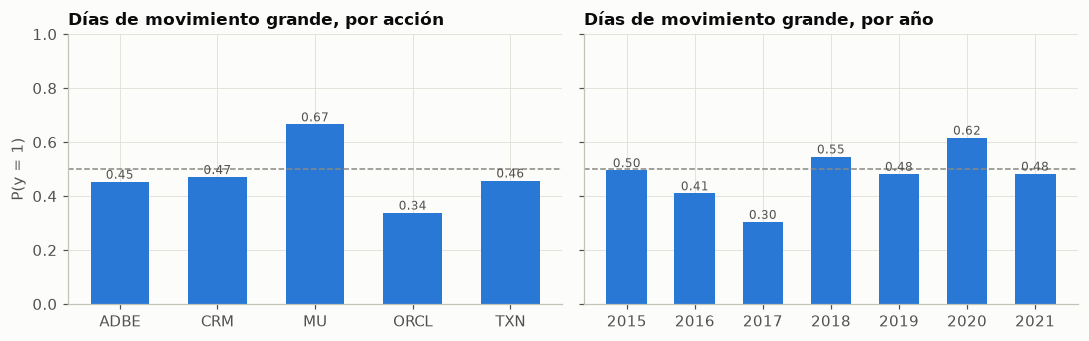

P(y = 1) en desarrollo           : 0.4773
Clase minoritaria                 : 0.4773
Entropía de la tasa base H(p)     : 0.6921   (ln 2 = 0.6931)
Exactitud de la clase mayoritaria : 0.5227
Rango de P(y = 1) entre años      : 0.304 a 0.617
Rango de P(y = 1) entre acciones  : 0.339 a 0.666
Decisión -> class_weight = None


**Respuesta: sí, los datos están balanceados.** El 47.7% de las sesiones es un día de movimiento grande y la clase minoritaria representa el 47.7%. No se ponderan clases ni se remuestrea. La proporción no es estable: va de 0.30 a 0.62 según el año y de 0.34 a 0.67 según la acción.

In [6]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.3 · prompts: P2, P3, P4.
# Instrucción (fase 2): «¿Data balanceada?: Diagnosticar la proporción de días alcistas (>5 bps) vs
#   bajistas/estables. Aplicar `class_weight='balanced'` en la pérdida; vetar explícitamente SMOTE por
#   destruir la causalidad temporal.»
# Difiere: con la tarea reformulada las clases son «día de movimiento grande» y «día tranquilo», no alcista
#   y bajista; el peso de clases solo se activa si la clase minoritaria baja del 40 %.
p_global = eda["y"].mean()
entropia_base = -(p_global * np.log(p_global) + (1 - p_global) * np.log(1 - p_global))
p_ticker = eda.groupby("ticker")["y"].mean()
p_anio = eda.groupby(eda["fecha"].dt.year)["y"].mean()

minoritaria = min(p_global, 1 - p_global)
PESO_CLASES = "balanced" if minoritaria < 0.40 else None

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
ejes[0].bar(p_ticker.index, p_ticker.values, color=C_ENT, width=0.6)
ejes[0].set_title("Días de movimiento grande, por acción")
ejes[1].bar(p_anio.index.astype(str), p_anio.values, color=C_ENT, width=0.6)
ejes[1].set_title("Días de movimiento grande, por año")
for eje in ejes:
    eje.axhline(0.5, color=C_REF, linewidth=1, linestyle="--")
    eje.set_ylim(0, 1)
    for barra in eje.patches:
        eje.annotate(f"{barra.get_height():.2f}", (barra.get_x() + barra.get_width() / 2, barra.get_height()),
                     ha="center", va="bottom", fontsize=8, color="#52514e")
ejes[0].set_ylabel("P(y = 1)")
plt.tight_layout()
plt.show()

print(f"P(y = 1) en desarrollo           : {p_global:.4f}")
print(f"Clase minoritaria                 : {minoritaria:.4f}")
print(f"Entropía de la tasa base H(p)     : {entropia_base:.4f}   (ln 2 = {np.log(2):.4f})")
print(f"Exactitud de la clase mayoritaria : {max(p_global, 1 - p_global):.4f}")
print(f"Rango de P(y = 1) entre años      : {p_anio.min():.3f} a {p_anio.max():.3f}")
print(f"Rango de P(y = 1) entre acciones  : {p_ticker.min():.3f} a {p_ticker.max():.3f}")
print(f"Decisión -> class_weight = {PESO_CLASES!r}")
display(Markdown(
    f"**Respuesta: {'sí, los datos están balanceados' if minoritaria >= 0.40 else 'no, los datos están desbalanceados'}.** "
    f"El {p_global:.1%} de las sesiones es un día de movimiento grande y la clase minoritaria representa el {minoritaria:.1%}. " +
    ("No se ponderan clases ni se remuestrea. " if PESO_CLASES is None else
     "Se pondera la función de costo con `class_weight='balanced'`; no se remuestrea. ") +
    f"La proporción no es estable: va de {p_anio.min():.2f} a {p_anio.max():.2f} según el año y de {p_ticker.min():.2f} a "
    f"{p_ticker.max():.2f} según la acción."))

### 2.4 ¿Los datos están normalizados?

Las variables crudas viven en escalas incomparables: el precio se mide en decenas o cientos de dólares, el volumen en millones de acciones y el retorno en centésimas. Un modelo lineal regularizado penaliza todos los coeficientes con la misma $\lambda$, así que una variable con escala grande queda castigada de forma arbitraria. La corrección es estandarizar cada atributo:

$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

Los parámetros $\mu$ y $\sigma$ se estiman **solo con el bloque de entrenamiento** de cada pliegue (sección 4). Aquí únicamente se diagnostica el problema.

In [7]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.4 · prompts: P2, P4.
# Instrucción (fase 2): «Responder obligatoriamente las preguntas del Notion: […] ¿Normalizada y
#   estacionaria?»
eda["rango"] = np.log(eda["high"] / eda["low"])     # amplitud intradía, base de la volatilidad
escalas = eda[["close", "volume", "ret", "rango"]].describe().T[["mean", "std", "min", "max"]]
escalas["orden_de_magnitud"] = np.floor(np.log10(escalas["std"])).astype(int)
escalas.index = ["Cierre (USD)", "Volumen (acciones)", "Retorno log", "Rango log (máx/mín)"]
display(escalas)
display(Markdown(
    f"**Respuesta: no, los datos no están normalizados.** Las desviaciones estándar van de {escalas['std'].min():.4f} a "
    f"{escalas['std'].max():,.0f}, una diferencia de {int(escalas['orden_de_magnitud'].max() - escalas['orden_de_magnitud'].min())} "
    "órdenes de magnitud. Hay que estandarizar, y se hace dentro del *pipeline* con parámetros estimados en entrenamiento."))

,mean,std,min,max,orden_de_magnitud
Cierre (USD),113.6967,115.8045,9.3208,688.3700,2
Volumen (acciones),"11,163,968.1452","12,123,680.0865","589,200.0000","149,010,300.0000",7
Retorno log,0.0008,0.0214,-0.2209,0.2315,-2
Rango log (máx/mín),0.0235,0.0151,0.0033,0.1746,-2


**Respuesta: no, los datos no están normalizados.** Las desviaciones estándar van de 0.0151 a 12,123,680, una diferencia de 9 órdenes de magnitud. Hay que estandarizar, y se hace dentro del *pipeline* con parámetros estimados en entrenamiento.

### 2.5 ¿Hay estacionalidad en la serie de tiempo?

La rúbrica pregunta por **estacionalidad**: patrones que se repiten con un período fijo. En retornos diarios hay dos candidatos clásicos, el día de la semana y el mes del año. Se contrastan así:

- **Prueba $\chi^2$ de independencia** entre el período (día o mes) y la etiqueta $y$. $H_0$: la proporción de días positivos es la misma en todos los períodos.
- **Kruskal-Wallis** sobre los retornos. $H_0$: los retornos de todos los períodos provienen de la misma distribución. Se usa porque no supone normalidad.
- **Autocorrelación** $\rho_k = \mathrm{corr}(x_t, x_{t-k})$. Una estacionalidad semanal aparecería como un pico en $k = 5$.

Se añade una pregunta distinta pero relacionada, la **estacionariedad**: que media y varianza no cambien con el tiempo. Se usan dos pruebas con hipótesis nulas opuestas, para que se confirmen mutuamente (implementadas en `statsmodels` [7]):

| Prueba | $H_0$ | Serie estacionaria si… |
|---|---|---|
| ADF [8] | Existe raíz unitaria (no estacionaria) | $p < 0.05$ (se rechaza) |
| KPSS [9] | La serie es estacionaria | $p > 0.05$ (no se rechaza) |

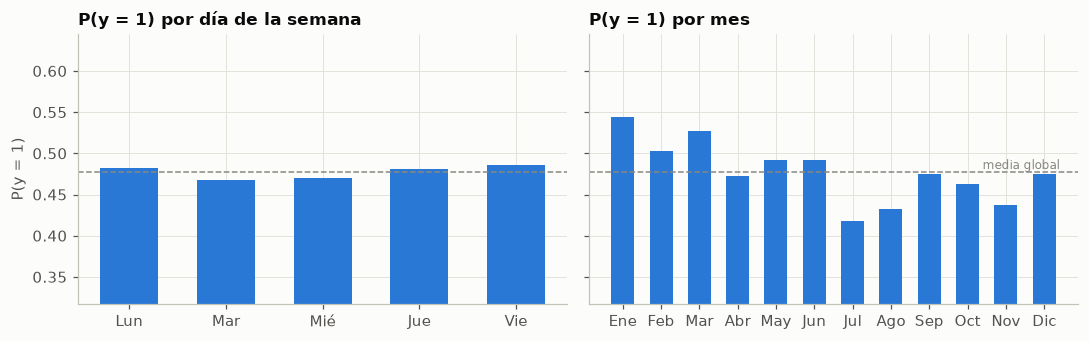

,chi2,"p (chi2, etiqueta)","p (Kruskal-Wallis, retorno)"
Período,,,
Día de la semana,1.7300,0.7853,0.5527
Mes del año,45.8181,0.0000,0.5279


Años (de 7) en que cada mes supera la proporción media de su propio año:


,Ene,Feb,Mar,Abr,May,Jun,Jul,Ago,Sep,Oct,Nov,Dic
años,5,4,5,3,4,4,1,3,3,2,3,4


**Respuesta sobre la estacionalidad.** Por día de la semana no hay evidencia de un efecto (χ², p = 0.7853). Por mes, χ² da p < 0.0001: las proporciones difieren entre meses. Sin embargo, el mes más consistente (Jul) queda del mismo lado de la media de su año en 6 de 7 años. Con 7 años y observaciones que no son independientes entre sí, esa evidencia no basta para afirmar un patrón estacional, y el mes no se usa como variable.

In [8]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.5 · prompts: P2, P3, P4.
# Instrucción (fase 2): «Responder obligatoriamente las preguntas del Notion»
# La pregunta de estacionalidad no está en el documento: viene de la rúbrica (ítem EDA) y entró con el
#   índice aprobado en P1.
from scipy.stats import chi2_contingency, kruskal

eda["dia"] = eda["fecha"].dt.dayofweek
eda["mes"] = eda["fecha"].dt.month
NOMBRES_DIA = ["Lun", "Mar", "Mié", "Jue", "Vie"]
NOMBRES_MES = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]

contrastes = []
for columna, nombre in [("dia", "Día de la semana"), ("mes", "Mes del año")]:
    chi2, p_chi, _, _ = chi2_contingency(pd.crosstab(eda[columna], eda["y"]))
    _, p_kw = kruskal(*[g["ret"].values for _, g in eda.groupby(columna)])
    contrastes.append({"Período": nombre, "chi2": chi2, "p (chi2, etiqueta)": p_chi, "p (Kruskal-Wallis, retorno)": p_kw})
contrastes = pd.DataFrame(contrastes).set_index("Período")

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
por_dia = eda.groupby("dia")["y"].mean()
por_mes = eda.groupby("mes")["y"].mean()
ejes[0].bar(NOMBRES_DIA, por_dia.values, color=C_ENT, width=0.6)
ejes[0].set_title("P(y = 1) por día de la semana")
ejes[1].bar(NOMBRES_MES, por_mes.values, color=C_ENT, width=0.6)
ejes[1].set_title("P(y = 1) por mes")
for eje in ejes:
    eje.axhline(p_global, color=C_REF, linewidth=1, linestyle="--")
    eje.set_ylim(max(0, min(por_dia.min(), por_mes.min()) - 0.1), min(1, max(por_dia.max(), por_mes.max()) + 0.1))
ejes[0].set_ylabel("P(y = 1)")
ejes[1].annotate("media global", (11.4, p_global), fontsize=8, color=C_REF, va="bottom", ha="right")
plt.tight_layout()
plt.show()

# ¿El efecto de un mes se repite cada año, o proviene de episodios aislados?
por_anio_mes = eda.groupby([eda["fecha"].dt.year, "mes"])["y"].mean().unstack("mes")
sobre_la_media = por_anio_mes.gt(eda.groupby(eda["fecha"].dt.year)["y"].mean(), axis=0).sum()
sobre_la_media.index = NOMBRES_MES
display(contrastes)
print(f"Años (de {por_anio_mes.shape[0]}) en que cada mes supera la proporción media de su propio año:")
display(sobre_la_media.to_frame("años").T)

n_anios = por_anio_mes.shape[0]
p_dia = contrastes.loc["Día de la semana", "p (chi2, etiqueta)"]
p_mes = contrastes.loc["Mes del año", "p (chi2, etiqueta)"]
mismo_lado = np.maximum(sobre_la_media, n_anios - sobre_la_media)      # años en que el mes queda del mismo lado de la media
display(Markdown(
    "**Respuesta sobre la estacionalidad.** Por día de la semana " +
    ("no hay evidencia de un efecto" if p_dia >= 0.05 else "la proporción de días agitados difiere") +
    f" (χ², {p_txt(p_dia)}). Por mes, χ² da {p_txt(p_mes)}" +
    (f": las proporciones difieren entre meses. Sin embargo, el mes más consistente ({mismo_lado.idxmax()}) queda del mismo lado "
     f"de la media de su año en {int(mismo_lado.max())} de {n_anios} años. Con {n_anios} años y observaciones que no son "
     "independientes entre sí, esa evidencia no basta para afirmar un patrón estacional, y el mes no se usa como variable."
     if p_mes < 0.05 else ": tampoco hay evidencia de un efecto mensual.")))

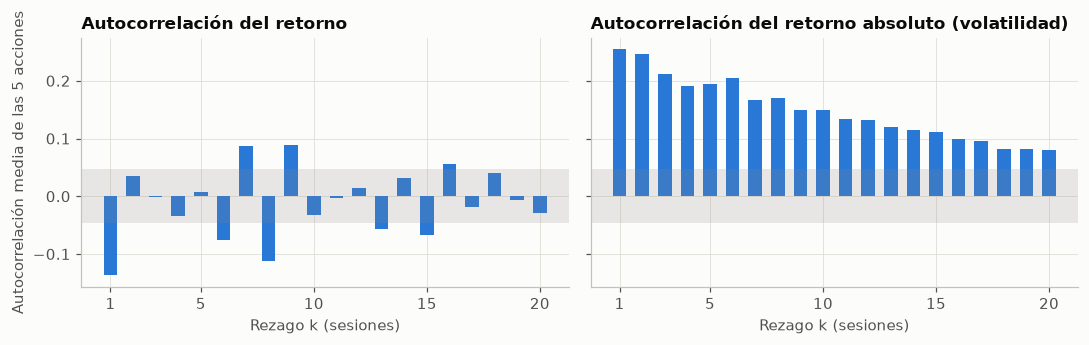

Autocorrelación media del retorno en k=1: -0.137 | en k=5: +0.008 | banda 95 %: ±0.047
Autocorrelación media del |retorno| en k=1: +0.254 | en k=5: +0.195


,ADF p (log-precio),KPSS p (log-precio),ADF p (retorno),KPSS p (retorno)
Acción,,,,
ADBE,0.8647,0.0100,0.0000,0.1000
CRM,0.7667,0.0100,0.0000,0.1000
MU,0.9214,0.0100,0.0000,0.1000
ORCL,0.9730,0.0100,0.0000,0.1000
TXN,0.8891,0.0100,0.0000,0.1000


**Respuesta sobre la estacionariedad.** Los log-precios no son estacionarios en ninguna de las 5 acciones: ADF no rechaza la raíz unitaria (p entre 0.77 y 0.97) y KPSS rechaza la estacionariedad (p ≤ 0.01). Los retornos sí lo son: ADF rechaza la raíz unitaria (p < 0.0001) y KPSS no rechaza la estacionariedad (p ≥ 0.10). La autocorrelación del retorno es -0.14 en el rezago 1 y +0.01 en el 5; la del retorno absoluto, +0.25 y +0.19: la magnitud persiste, la dirección no.

In [9]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.5 · prompts: P2, P4.
# Instrucción (fase 2): «¿Normalizada y estacionaria?: Ejecutar contrastes formales de raíz unitaria: ADF (p
#   < 0.01) y KPSS (p > 0.05) sobre precios crudos vs retornos logarítmicos, demostrando que los precios son
#   I(1) y los retornos son I(0).»
from statsmodels.tools.sm_exceptions import InterpolationWarning
from statsmodels.tsa.stattools import acf, adfuller, kpss

REZAGOS = 20
acf_ret = np.mean([acf(g["ret"].values, nlags=REZAGOS, fft=True)[1:] for _, g in eda.groupby("ticker")], axis=0)
acf_abs = np.mean([acf(g["ret"].abs().values, nlags=REZAGOS, fft=True)[1:] for _, g in eda.groupby("ticker")], axis=0)
banda = 1.96 / np.sqrt(eda["fecha"].nunique())      # banda de confianza del 95 % bajo ruido blanco

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.2), sharey=True)
for eje, valores, titulo in [(ejes[0], acf_ret, "Autocorrelación del retorno"),
                             (ejes[1], acf_abs, "Autocorrelación del retorno absoluto (volatilidad)")]:
    eje.bar(np.arange(1, REZAGOS + 1), valores, color=C_ENT, width=0.6)
    eje.axhspan(-banda, banda, color=C_REF, alpha=0.18, linewidth=0)
    eje.set_title(titulo)
    eje.set_xlabel("Rezago k (sesiones)")
    eje.set_xticks([1, 5, 10, 15, 20])
ejes[0].set_ylabel("Autocorrelación media de las 5 acciones")
plt.tight_layout()
plt.show()

filas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", InterpolationWarning)   # KPSS acota su p-valor a [0.01, 0.10]
    warnings.simplefilter("ignore", FutureWarning)          # aviso de cambio de formato de salida en statsmodels
    for t, g in eda.groupby("ticker"):
        log_precio, retorno = np.log(g["close"].values), g["ret"].values
        filas.append({"Acción": t,
                      "ADF p (log-precio)": adfuller(log_precio, autolag="AIC")[1],
                      "KPSS p (log-precio)": kpss(log_precio, regression="c", nlags="auto")[1],
                      "ADF p (retorno)": adfuller(retorno, autolag="AIC")[1],
                      "KPSS p (retorno)": kpss(retorno, regression="c", nlags="auto")[1]})
estacionariedad = pd.DataFrame(filas).set_index("Acción")
print(f"Autocorrelación media del retorno en k=1: {acf_ret[0]:+.3f} | en k=5: {acf_ret[4]:+.3f} | banda 95 %: ±{banda:.3f}")
print(f"Autocorrelación media del |retorno| en k=1: {acf_abs[0]:+.3f} | en k=5: {acf_abs[4]:+.3f}")
display(estacionariedad)

e = estacionariedad
precio_no_estacionario = bool((e["ADF p (log-precio)"] > 0.05).all() and (e["KPSS p (log-precio)"] < 0.05).all())
retorno_estacionario = bool((e["ADF p (retorno)"] < 0.05).all() and (e["KPSS p (retorno)"] > 0.05).all())
display(Markdown(
    "**Respuesta sobre la estacionariedad.** " +
    (f"Los log-precios no son estacionarios en ninguna de las {len(e)} acciones: ADF no rechaza la raíz unitaria (p entre "
     f"{e['ADF p (log-precio)'].min():.2f} y {e['ADF p (log-precio)'].max():.2f}) y KPSS rechaza la estacionariedad "
     f"(p ≤ {e['KPSS p (log-precio)'].max():.2f}). " if precio_no_estacionario else
     "Las pruebas sobre los log-precios no son unánimes entre acciones. ") +
    (f"Los retornos sí lo son: ADF rechaza la raíz unitaria ({p_txt(e['ADF p (retorno)'].max(), '≤')}) y KPSS no rechaza la "
     f"estacionariedad (p ≥ {e['KPSS p (retorno)'].min():.2f}). " if retorno_estacionario else
     "Las pruebas sobre los retornos no son unánimes entre acciones. ") +
    f"La autocorrelación del retorno es {acf_ret[0]:+.2f} en el rezago 1 y {acf_ret[4]:+.2f} en el 5; la del retorno absoluto, "
    f"{acf_abs[0]:+.2f} y {acf_abs[4]:+.2f}: la magnitud persiste, la dirección no."))

**Cómo leer estos resultados.**

- **Estacionalidad.** Si $\chi^2$ rechaza $H_0$ ($p < 0.05$), la proporción de días agitados difiere entre períodos. Eso no basta para hablar de estacionalidad: $\chi^2$ supone observaciones independientes, y como la volatilidad viene en rachas, un solo episodio (marzo de 2020, por ejemplo) puede inflar un mes entero. La última tabla lo comprueba: un patrón estacional real haría que el mismo mes quedara por encima (o por debajo) de la media en casi todos los años. En ambos casos el día de la semana se conserva como variable categórica, porque se conoce de antemano y el filtro de la sección 5 no la toca.
- **Estacionariedad.** El log-precio debe mostrar ADF $p > 0.05$ y KPSS $p < 0.05$ (no estacionario, integrado de orden 1), mientras que el retorno debe mostrar lo contrario. Esa es la razón de construir las variables con retornos y razones, nunca con niveles de precio: un árbol de decisión no puede extrapolar a precios que no vio.
- **La justificación de la tarea.** La autocorrelación del retorno es pequeña y cambia de signo de un rezago a otro. La del retorno absoluto es positiva en todos los rezagos y decae despacio: la magnitud del movimiento de mañana se parece a la de hoy, aunque su dirección no. Por eso la tarea es predecir la magnitud.
- **La brecha.** Esa misma persistencia hace que el último día de entrenamiento y el primero de validación sean casi la misma observación del régimen de mercado. De ahí la **brecha de 5 sesiones** entre ambos bloques (sección 4).

### 2.6 ¿Hacen falta transformaciones no lineales (asimetría)?

El coeficiente de asimetría $\gamma_1 = \mathbb{E}\left[\left(\frac{x-\mu}{\sigma}\right)^3\right]$ vale 0 en una distribución simétrica. Valores por encima de 1 indican una cola derecha larga, que domina la varianza y distorsiona tanto la estandarización como los coeficientes de un modelo lineal. Dos remedios:

- $\ln(x)$ para variables positivas con crecimiento multiplicativo, como el volumen.
- **Yeo-Johnson** [10], una familia de potencias $\psi(x, \lambda)$ que estima $\lambda$ por máxima verosimilitud para acercar la distribución a una normal y admite valores no positivos.

La gráfica compara antes y después usando $\ln(x)$, que no tiene parámetros que estimar: en el EDA no se ajusta nada. En el modelo se usa Yeo-Johnson, cuya $\lambda$ sí se estima con los datos, y por eso vive dentro del *pipeline* y se ajusta solo con entrenamiento.

**Por qué $\ln(x)$ y no $\ln(1+x)$.** $\ln(1+x)$ es la opción segura cuando una variable puede valer cero, pero para valores pequeños $\ln(1+x) \approx x$: una volatilidad diaria del orden de $0.01$ quedaría prácticamente igual y su asimetría no se corregiría. La tabla de la celda muestra las dos opciones. Como $\ln(x)$ no está definido en cero, la celda comprueba con un `assert` que ambas variables son estrictamente positivas antes de transformar. En el *pipeline* ese riesgo no existe: Yeo-Johnson está definida para cualquier valor real, incluido el cero.

Mínimos observados -> volatilidad Garman-Klass: 0.0019 | volumen relativo: 0.1724


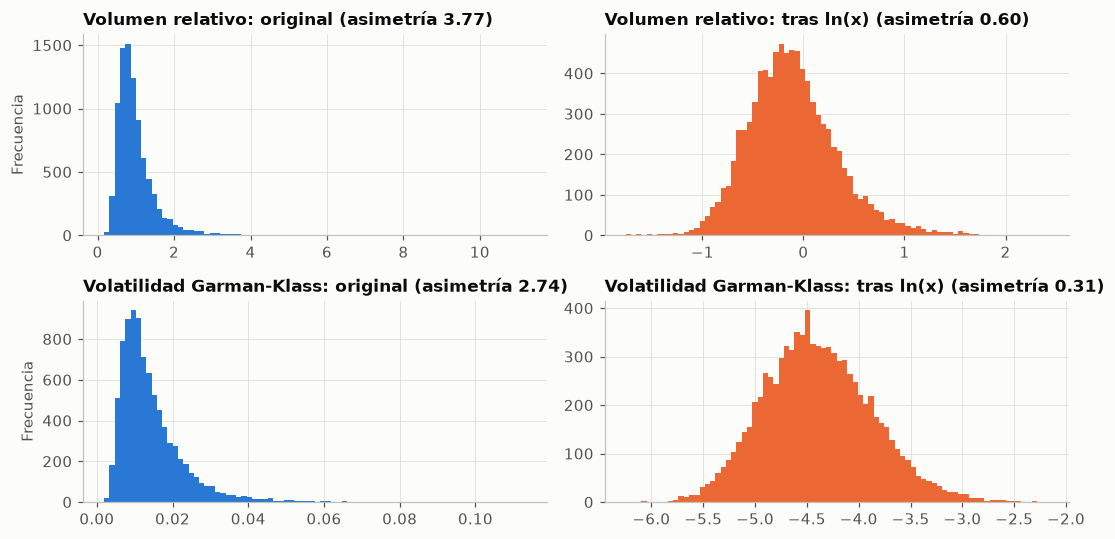

,Asimetría,Curtosis en exceso,Asimetría con ln(x),Asimetría con ln(1 + x)
Retorno log,-0.1667,10.0489,NaN,NaN
Volumen relativo,3.7748,31.2720,0.5986,1.4765
Volatilidad Garman-Klass,2.7393,14.0319,0.3078,2.6325


**Respuesta: sí hacen falta transformaciones no lineales.** El volumen relativo y la volatilidad tienen asimetría 3.77 y 2.74; con ln(x) bajan a 0.60 y 0.31. El retorno es casi simétrico (-0.17) pero de colas pesadas (curtosis en exceso 10.0), lo que se trata con winsorización y no con una potencia.

In [10]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.6 · prompts: P2, P4.
# Instrucción (fase 2): «¿Asimetría (Skewness) y Outliers?: Identificar colas pesadas en volatilidad y
#   volumen. […] transformaciones de potencia Yeo-Johnson (`PowerTransformer`).»
# Difiere: en el EDA no se ajusta ningún transformador: la asimetría se compara antes y después de ln(x), y
#   Yeo-Johnson vive solo dentro del pipeline.
from scipy.stats import kurtosis, skew

eda["vol_gk"] = np.sqrt(0.5 * np.log(eda["high"] / eda["low"]) ** 2
                        - (2 * np.log(2) - 1) * np.log(eda["close"] / eda["open"]) ** 2)
eda["volumen_rel"] = eda["volume"] / eda.groupby("ticker")["volume"].transform("mean")

# ln(x) solo está definido para valores estrictamente positivos: se verifica antes de transformar.
assert (eda["vol_gk"] > 0).all() and (eda["volumen_rel"] > 0).all(), "Hay valores no positivos: ln(x) no está definido."

variables = {"Retorno log": "ret", "Volumen relativo": "volumen_rel", "Volatilidad Garman-Klass": "vol_gk"}
forma = pd.DataFrame({nombre: {"Asimetría": skew(eda[c]), "Curtosis en exceso": kurtosis(eda[c])}
                      for nombre, c in variables.items()}).T

transformadas = {
    "Volumen relativo": np.log(eda["volumen_rel"].values),
    "Volatilidad Garman-Klass": np.log(eda["vol_gk"].values),
}
forma["Asimetría con ln(x)"] = [np.nan, skew(transformadas["Volumen relativo"]),
                                skew(transformadas["Volatilidad Garman-Klass"])]
forma["Asimetría con ln(1 + x)"] = [np.nan, skew(np.log1p(eda["volumen_rel"].values)), skew(np.log1p(eda["vol_gk"].values))]
print(f"Mínimos observados -> volatilidad Garman-Klass: {eda['vol_gk'].min():.4f} | volumen relativo: {eda['volumen_rel'].min():.4f}")

fig, ejes = plt.subplots(2, 2, figsize=(10, 5))
for fila, (nombre, despues, etiqueta) in enumerate([
        ("Volumen relativo", transformadas["Volumen relativo"], "ln(x)"),
        ("Volatilidad Garman-Klass", transformadas["Volatilidad Garman-Klass"], "ln(x)")]):
    antes = eda[variables[nombre]].values
    ejes[fila, 0].hist(antes, bins=80, color=C_ENT)
    ejes[fila, 0].set_title(f"{nombre}: original (asimetría {skew(antes):.2f})")
    ejes[fila, 1].hist(despues, bins=80, color=C_VAL)
    ejes[fila, 1].set_title(f"{nombre}: tras {etiqueta} (asimetría {skew(despues):.2f})")
    ejes[fila, 0].set_ylabel("Frecuencia")
plt.tight_layout()
plt.show()
display(forma)
display(Markdown(
    "**Respuesta: sí hacen falta transformaciones no lineales.** El volumen relativo y la volatilidad tienen asimetría "
    f"{forma.loc['Volumen relativo', 'Asimetría']:.2f} y {forma.loc['Volatilidad Garman-Klass', 'Asimetría']:.2f}; con ln(x) bajan a "
    f"{forma.loc['Volumen relativo', 'Asimetría con ln(x)']:.2f} y {forma.loc['Volatilidad Garman-Klass', 'Asimetría con ln(x)']:.2f}. "
    f"El retorno es casi simétrico ({forma.loc['Retorno log', 'Asimetría']:+.2f}) pero de colas pesadas (curtosis en exceso "
    f"{forma.loc['Retorno log', 'Curtosis en exceso']:.1f}), lo que se trata con winsorización y no con una potencia."))

### 2.7 Valores atípicos

Los retornos extremos de una acción no son errores de medición: corresponden a anuncios de resultados o a episodios de pánico del mercado, como marzo de 2020. Eliminarlos sesgaría la muestra justo en los días que más importan. La alternativa es la **winsorización**: recortar cada variable a sus percentiles 1 y 99,

$$x^{w} = \min\left(\max\left(x,\ q_{0.01}\right),\ q_{0.99}\right)$$

Así el dato se conserva pero deja de dominar la varianza. Los cuantiles $q_{0.01}$ y $q_{0.99}$ son parámetros aprendidos, igual que una media, por lo que deben estimarse solo con entrenamiento. De eso se encarga el transformador `CausalWinsorizer` de la sección 4.

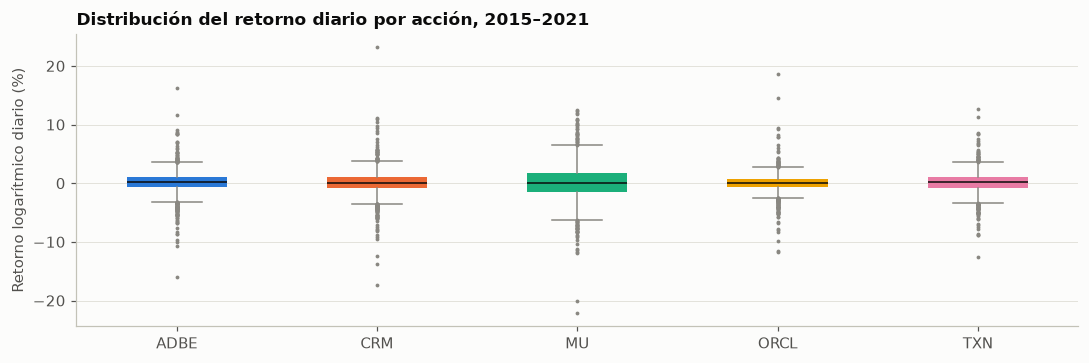

Retornos a más de 5 desviaciones estándar: 27 de 8,815 (0.306%); bajo normalidad se esperaría 0.00006%.


,ticker,fecha,retorno (%)
0,ORCL,2020-03-13,18.5900
1,CRM,2020-08-26,23.1500
2,ORCL,2021-12-10,14.5100
3,ADBE,2020-03-13,16.3100
4,CRM,2020-03-16,-17.3000
5,ADBE,2020-03-16,-15.9500


**Respuesta sobre los atípicos.** 27 retornos (0.31%) están a más de 5 desviaciones estándar, muchos más de los que admitiría una distribución normal. Corresponden a fechas reales de mercado, no a errores de medición: no se elimina ninguna fila y los extremos de las variables se recortan dentro del *pipeline*.

In [11]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.7 · prompts: P2, P4.
# Instrucción (fase 2): «¿Asimetría (Skewness) y Outliers?: Identificar colas pesadas en volatilidad y
#   volumen.»
fig, eje = plt.subplots(figsize=(10, 3.4))
cajas = eje.boxplot([100 * eda.loc[eda["ticker"] == t, "ret"].values for t in TICKERS], patch_artist=True, widths=0.5,
                    flierprops=dict(marker="o", markersize=2.5, markerfacecolor=C_REF, markeredgecolor="none"),
                    medianprops=dict(color="#0b0b0b"), whiskerprops=dict(color=C_REF), capprops=dict(color=C_REF))
for caja, t in zip(cajas["boxes"], TICKERS):
    caja.set(facecolor=COLOR_TICKER[t], edgecolor="none")
eje.set_xticks(range(1, len(TICKERS) + 1))
eje.set_xticklabels(TICKERS)
eje.set_ylabel("Retorno logarítmico diario (%)")
eje.set_title("Distribución del retorno diario por acción, 2015–2021")
eje.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

z = (eda["ret"] - eda.groupby("ticker")["ret"].transform("mean")) / eda.groupby("ticker")["ret"].transform("std")
print(f"Retornos a más de 5 desviaciones estándar: {int((z.abs() > 5).sum())} de {len(eda):,} "
      f"({(z.abs() > 5).mean():.3%}); bajo normalidad se esperaría {5.7e-7:.5%}.")
extremos = eda.loc[z.abs().sort_values(ascending=False).index[:6], ["ticker", "fecha", "ret"]].copy()
extremos["ret"] = (100 * extremos["ret"]).round(2)
display(extremos.rename(columns={"ret": "retorno (%)"}).reset_index(drop=True))
display(Markdown(
    f"**Respuesta sobre los atípicos.** {int((z.abs() > 5).sum())} retornos ({(z.abs() > 5).mean():.2%}) están a más de 5 "
    "desviaciones estándar, muchos más de los que admitiría una distribución normal. Corresponden a fechas reales de mercado, "
    "no a errores de medición: no se elimina ninguna fila y los extremos de las variables se recortan dentro del *pipeline*."))

### 2.8 Dominio de texto: nube de palabras y términos frecuentes

Antes de contar palabras se limpia el texto, como pide la rúbrica:

1. **Minúsculas y tokenización** con la expresión regular `[a-z]+`, que descarta cifras y signos.
2. **Eliminación de *stop words*** del inglés (artículos, preposiciones), que no aportan significado.
3. **Lematización** con WordNet: cada palabra se reduce a su forma de diccionario (*stocks* → *stock*).

Este preprocesamiento sirve **solo para el EDA**. FinBERT recibe los titulares originales, porque su tokenizador y sus pesos fueron entrenados con texto natural y dependen del orden y de las palabras funcionales.

También se mide la **cobertura**: en qué fracción de los días del año hubo al menos una noticia. Los días sin noticias son frecuentes y el modelo debe saber distinguirlos.

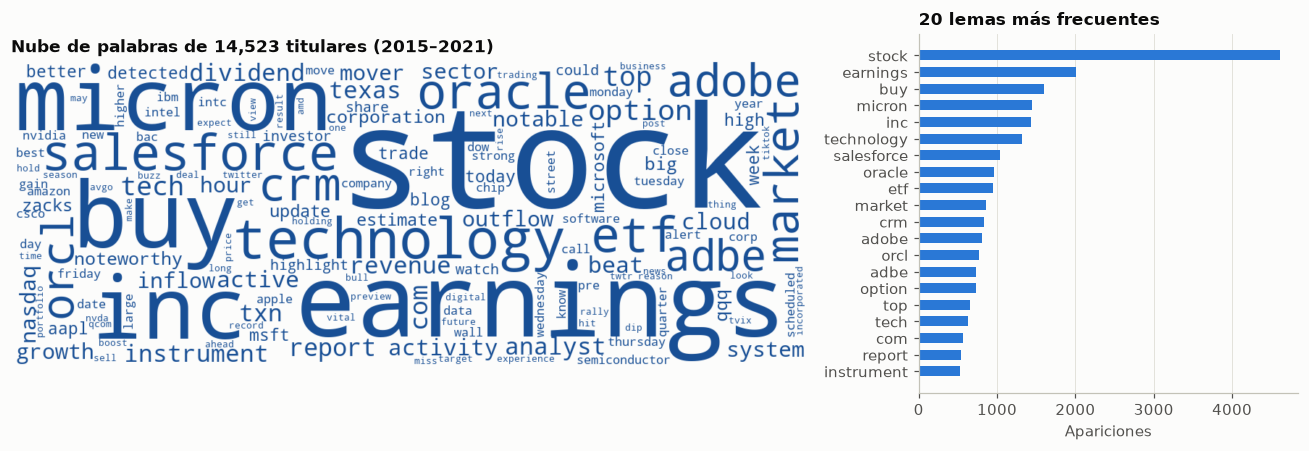

Titulares por acción y año:


año,2015,2016,2017,2018,2019,2020,2021
ticker,,,,,,,
ADBE,151,240,391,499,315,331,417
CRM,186,416,434,547,416,540,749
MU,267,328,994,1310,469,365,535
ORCL,306,420,546,431,281,481,443
TXN,157,181,370,353,206,173,275


Fracción de los días calendario del año con al menos un titular:


año,2015,2016,2017,2018,2019,2020,2021
ticker,,,,,,,
ADBE,0.2600,0.3800,0.4700,0.5800,0.5000,0.5000,0.6100
CRM,0.3000,0.4900,0.5600,0.6200,0.5400,0.5800,0.7700
MU,0.3700,0.4300,0.6900,0.7500,0.5800,0.4800,0.5600
ORCL,0.4500,0.5300,0.6000,0.5300,0.4400,0.4900,0.5800
TXN,0.3000,0.3200,0.5000,0.4800,0.3300,0.3100,0.4200


**Respuesta sobre el texto.** Tras lematizar y quitar *stop words*, los lemas más frecuentes son stock, earnings, buy, micron, inc, technology: vocabulario bursátil genérico y nombres de las empresas. La cobertura es parcial y cambia con el tiempo: la fracción de días con al menos un titular va de 0.26 a 0.77 según la acción y el año.

In [12]:
# [Uso de IA] Celda generada con un asistente de IA · sección 2.8 · prompts: P2, P4.
# Instrucción (fase 2): «Dominio texto: Generar nube de palabras (WordCloud) y gráfico de frecuencias de
#   titulares financieros tras eliminación de stopwords y lematización.»
from collections import Counter

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from wordcloud import WordCloud

for recurso in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(recurso, quiet=True)

VACIAS = set(stopwords.words("english"))
lematizador = WordNetLemmatizer()


def limpiar(texto):
    """Minúsculas -> tokens alfabéticos -> sin stop words -> lematizados."""
    return [lematizador.lemmatize(p) for p in re.findall(r"[a-z]+", texto.lower()) if p not in VACIAS and len(p) > 2]


frecuencias = Counter(palabra for titulo in noticias_eda["titulo"] for palabra in limpiar(titulo))
top = pd.Series(dict(frecuencias.most_common(20))).sort_values()

nube = WordCloud(width=1100, height=420, background_color="#fcfcfb", max_words=150, random_state=SEMILLA,
                 color_func=lambda *a, **k: "#184f95").generate_from_frequencies(frecuencias)
fig, ejes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [2.1, 1]})
ejes[0].imshow(nube, interpolation="bilinear")
ejes[0].axis("off")
ejes[0].set_title(f"Nube de palabras de {len(noticias_eda):,} titulares (2015–2021)")
ejes[1].barh(top.index, top.values, color=C_ENT, height=0.6)
ejes[1].set_title("20 lemas más frecuentes")
ejes[1].set_xlabel("Apariciones")
ejes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

anio_pub = noticias_eda["fecha_pub"].dt.year
dias_con_noticia = noticias_eda.groupby(["ticker", anio_pub])["fecha_pub"].nunique().unstack()
dias_del_anio = pd.Series({a: pd.Timestamp(a, 12, 31).dayofyear for a in dias_con_noticia.columns})
print("Titulares por acción y año:")
display(pd.crosstab(noticias_eda["ticker"], anio_pub.rename("año")))
print("Fracción de los días calendario del año con al menos un titular:")
cobertura = (dias_con_noticia / dias_del_anio).rename_axis(columns="año")
display(cobertura.round(2))
display(Markdown(
    f"**Respuesta sobre el texto.** Tras lematizar y quitar *stop words*, los lemas más frecuentes son "
    f"{', '.join(top.index[::-1][:6])}: vocabulario bursátil genérico y nombres de las empresas. La cobertura es parcial y "
    f"cambia con el tiempo: la fracción de días con al menos un titular va de {cobertura.min().min():.2f} a "
    f"{cobertura.max().max():.2f} según la acción y el año."))

### 2.9 Del EDA a las decisiones de diseño

Cada hallazgo se traduce en una decisión concreta del *pipeline*:

| Pregunta del EDA | Evidencia (celda) | Decisión |
|---|---|---|
| ¿Balanceada? | Proporción de positivos y regla del 40 % (2.3) | `class_weight` según la variable `PESO_CLASES`; nunca SMOTE. La referencia de pérdida es $H(p)$. |
| ¿Normalizada? | Escalas separadas por varios órdenes de magnitud (2.4) | `StandardScaler` dentro del *pipeline*. |
| ¿Estacionalidad? | $\chi^2$, Kruskal-Wallis y autocorrelación (2.5) | Día de la semana como variable categórica; brecha de 5 sesiones por la persistencia de la volatilidad. |
| ¿Estacionaria? | ADF y KPSS (2.5) | Se modelan retornos y razones, nunca niveles de precio. |
| ¿Asimetría? | Coeficiente de asimetría antes y después (2.6) | Yeo-Johnson en las variables de volatilidad y volumen. |
| ¿Atípicos? | Retornos a más de 5σ en fechas reales (2.7) | Winsorización al 1 % y 99 %, ajustada en entrenamiento. No se elimina ninguna fila. |
| Texto | Cobertura parcial de noticias (2.8) | Indicador `sin_noticias` e imputación dentro del *pipeline*. |

## 3. Extracción de características

La rúbrica distingue la extracción según el tipo de dato. Aquí se usan dos de sus opciones:

- **Serie de tiempo → rezagos (*lags*).** Variables calculadas con el pasado de cada acción.
- **Texto → modelo preentrenado → vector *embedding* (transferencia de aprendizaje).** Cada titular pasa por FinBERT.

### 3.1 Rezagos causales de la serie de tiempo

**Regla de causalidad.** Para predecir la sesión $t$, cada variable usa precios hasta el cierre de $t-1$. Se implementa en dos pasos: primero se calcula lo que se sabe *al cierre de cada sesión* $s$, y en la sección 3.5 toda la tabla se desplaza una sesión (`shift(1)`) de una sola vez. Aplicar el desplazamiento en un único lugar evita olvidarlo en alguna columna.

Variables, con $C, O, H, L, V$ para cierre, apertura, máximo, mínimo y volumen:

| Grupo | Variable | Definición |
|---|---|---|
| Momentum | `ret_1`, `ret_5`, `ret_21` | $\sum_{j=0}^{k-1} r_{s-j}$ con $k = 1, 5, 21$ |
| | `rsi_14` | $100 - \dfrac{100}{1 + \overline{G}_{14} / \overline{P}_{14}}$, medias exponenciales de ganancias y pérdidas |
| | `macd_norm` | $\dfrac{(\mathrm{EMA}_{12} - \mathrm{EMA}_{26}) - \mathrm{EMA}_9(\cdot)}{C}$ |
| | `bb_pctb` | $\dfrac{C - (\mathrm{MA}_{20} - 2\sigma_{20})}{4\sigma_{20}}$ |
| | `log_cambio_vol` | $\ln(V_s / V_{s-1})$ |
| Mercado | `ret_mkt_1`, `ret_mkt_5`, `exceso_1` | Retorno de SPY y retorno de la acción menos el de SPY |
| Volatilidad | `abs_ret_1`, `rango_1` | $\lvert r_s\rvert$ y $\ln(H_s/L_s)$: magnitud del movimiento de la última sesión |
| | `vol_5`, `vol_21`, `vol_mkt_21` | Desviación estándar móvil de $r$ |
| | `gk_vol_21` | $\sqrt{\frac{1}{21}\sum \left[\tfrac12 \ln^2\frac{H}{L} - (2\ln 2 - 1)\ln^2\frac{C}{O}\right]}$ (Garman-Klass [11]) |
| | `bb_ancho` | $4\sigma_{20} / \mathrm{MA}_{20}$ |
| Volumen | `volumen_rel` | $V_s / \overline{V}_{20}$ |

Todas son retornos, razones u osciladores: ninguna depende del nivel de precio, en línea con el resultado de estacionariedad de la sección 2.5. `exceso_1` es combinación lineal exacta de `ret_1` y `ret_mkt_1`; se deja a propósito porque es un caso concreto de multicolinealidad que la penalización $L_2$ debe manejar (sección 6).

In [13]:
# [Uso de IA] Celda generada con un asistente de IA · sección 3.1 · prompts: P2, P3.
# Instrucción (diagrama de arquitectura): «Serie de tiempo: Lags causales (t-1 -> t) (Varianza de
#   Garman-Klass, RSI, MACD, %B)»
def caracteristicas_al_cierre(df, retorno_mercado):
    """Variables que usan información hasta el cierre de cada sesión s (inclusive).

    df: precios de UNA acción ordenados por fecha. retorno_mercado: Serie de retornos de SPY por fecha.
    Solo se usan ventanas hacia atrás (rolling / ewm); nunca centradas.
    """
    df = df.set_index("fecha")
    c, o, h, l, v = df["close"], df["open"], df["high"], df["low"], df["volume"].replace(0, np.nan)
    r = np.log(c).diff()
    rm = retorno_mercado.reindex(df.index)
    f = pd.DataFrame(index=df.index)

    # Momentum
    f["ret_1"], f["ret_5"], f["ret_21"] = r, r.rolling(5).sum(), r.rolling(21).sum()
    cambio = c.diff()
    ganancia = cambio.clip(lower=0).ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    perdida = (-cambio.clip(upper=0)).ewm(alpha=1 / 14, adjust=False, min_periods=14).mean()
    f["rsi_14"] = 100 - 100 / (1 + ganancia / perdida)
    macd = c.ewm(span=12, adjust=False).mean() - c.ewm(span=26, adjust=False).mean()
    f["macd_norm"] = (macd - macd.ewm(span=9, adjust=False).mean()) / c
    ma20, sd20 = c.rolling(20).mean(), c.rolling(20).std()
    f["bb_pctb"] = (c - (ma20 - 2 * sd20)) / (4 * sd20)
    f["log_cambio_vol"] = np.log(v).diff()

    # Contexto de mercado
    f["ret_mkt_1"], f["ret_mkt_5"], f["exceso_1"] = rm, rm.rolling(5).sum(), r - rm

    # Volatilidad y volumen (positivas y asimétricas)
    f["abs_ret_1"], f["rango_1"] = r.abs(), np.log(h / l)
    f["vol_5"], f["vol_21"] = r.rolling(5).std(), r.rolling(21).std()
    gk = 0.5 * np.log(h / l) ** 2 - (2 * np.log(2) - 1) * np.log(c / o) ** 2
    f["gk_vol_21"] = np.sqrt(gk.rolling(21).mean())
    f["bb_ancho"] = 4 * sd20 / ma20
    f["volumen_rel"] = v / v.rolling(20).mean()
    f["vol_mkt_21"] = rm.rolling(21).std()
    return f


def construir_tabular(panel_acciones, retorno_mercado):
    partes = [caracteristicas_al_cierre(g, retorno_mercado).assign(ticker=t).reset_index()
              for t, g in panel_acciones.groupby("ticker")]
    return pd.concat(partes, ignore_index=True)


COLS_MOM = ["ret_1", "ret_5", "ret_21", "rsi_14", "macd_norm", "bb_pctb", "log_cambio_vol",
            "ret_mkt_1", "ret_mkt_5", "exceso_1"]
COLS_ASIM = ["abs_ret_1", "rango_1", "vol_5", "vol_21", "gk_vol_21", "bb_ancho", "volumen_rel", "vol_mkt_21"]

tabular = construir_tabular(acciones, mercado["ret"])
print(f"Tabla al cierre: {tabular.shape[0]:,} filas x {len(COLS_MOM) + len(COLS_ASIM)} variables de precio")
tabular[tabular["fecha"] >= FECHA_INICIO].head(3)

Tabla al cierre: 12,020 filas x 18 variables de precio


,fecha,ret_1,ret_5,ret_21,rsi_14,macd_norm,bb_pctb,log_cambio_vol,ret_mkt_1,ret_mkt_5,exceso_1,abs_ret_1,rango_1,vol_5,vol_21,gk_vol_21,bb_ancho,volumen_rel,vol_mkt_21,ticker
149,2015-01-02,-0.0050,-0.0326,-0.0155,47.3639,-0.0038,0.3697,0.5471,-0.0005,-0.0113,-0.0044,0.0050,0.0181,0.0049,0.0234,0.0134,0.0897,0.6240,0.0097,ADBE
150,2015-01-05,-0.0050,-0.0367,-0.0165,45.7258,-0.0047,0.3252,0.0228,-0.0182,-0.0328,0.0132,0.0050,0.0119,0.0040,0.0234,0.0134,0.0909,0.6301,0.0104,ADBE
151,2015-01-06,-0.0204,-0.0498,-0.0348,39.7608,-0.0066,0.1415,0.1863,-0.0095,-0.0436,-0.0109,0.0204,0.0313,0.0070,0.0238,0.0139,0.0962,0.7607,0.0106,ADBE


### 3.2 Prueba de causalidad

Una variable es causal si su valor en la sesión $s$ **no cambia** cuando se borran todos los datos posteriores a $s$. La celda siguiente lo comprueba: recalcula todas las variables con la historia truncada en una fecha de corte y exige que coincidan con las originales hasta ese corte. Una media móvil centrada, o cualquier estadístico calculado sobre la serie completa, haría fallar el `assert`.

In [14]:
# [Uso de IA] Celda generada con un asistente de IA · sección 3.2 · prompt: P2.
# Instrucción (diagrama de arquitectura): «Serie de tiempo: Lags causales (t-1 -> t)»
# El documento no pide esta prueba: se añadió en el índice para comprobar con un assert que los rezagos son
#   causales (truncar el futuro no cambia el pasado).
corte_prueba = pd.Timestamp("2018-06-29")
truncado = construir_tabular(acciones[acciones["fecha"] <= corte_prueba],
                             mercado.loc[mercado.index <= corte_prueba, "ret"])
original = tabular[tabular["fecha"] <= corte_prueba]

a = original.sort_values(["ticker", "fecha"])[COLS_MOM + COLS_ASIM].to_numpy()
b = truncado.sort_values(["ticker", "fecha"])[COLS_MOM + COLS_ASIM].to_numpy()
assert a.shape == b.shape
assert np.allclose(a, b, equal_nan=True, rtol=0, atol=1e-12), "Alguna variable usa información del futuro."
print(f"Prueba superada: {a.shape[0]:,} filas x {a.shape[1]} variables idénticas con y sin los datos posteriores "
      f"al {corte_prueba.date()}.")

Prueba superada: 5,145 filas x 18 variables idénticas con y sin los datos posteriores al 2018-06-29.


### 3.3 Transferencia de aprendizaje: *embeddings* de FinBERT

FinBERT [5] es un modelo BERT [12] ajustado con texto financiero. Para cada titular produce:

- Un vector $\mathbf{e} \in \mathbb{R}^{768}$: el estado oculto final del token especial `[CLS]`, que resume la oración completa. Es el *embedding* que alimenta al modelo.
- Tres probabilidades (positivo, negativo, neutral). Con ellas se define el sentimiento escalar $s = p_{\text{pos}} - p_{\text{neg}} \in [-1, 1]$.

**Por qué no hay fuga aquí.** Los pesos de FinBERT están congelados: no se llama a ningún `.fit()` ni se reentrena con estos datos. Cada titular se transforma de forma independiente de los demás, así que procesar juntos los de desarrollo y los de prueba no traslada información entre ellos. Además, FinBERT fue ajustado con Financial PhraseBank y un subconjunto de Reuters TRC2, corpus anteriores a 2015, por lo que tampoco vio los titulares de este estudio.

La inferencia usa la biblioteca `transformers` [13], con GPU si está disponible, y guarda el resultado en `datos/`.

In [15]:
# [Uso de IA] Celda generada con un asistente de IA · sección 3.3 · prompt: P2.
# Instrucción (diagrama de arquitectura): «Texto (Noticias): Opción Transfer Learning (FinBERT / embeddings
#   densos sin feature selection posterior)»
import torch
from transformers import AutoModelForSequenceClassification, AutoTokenizer

MODELO_TEXTO = "ProsusAI/finbert"
torch.manual_seed(SEMILLA)


def extraer_finbert(titulares, lote=64, longitud_max=64):
    """Devuelve (embeddings [CLS] de 768 dims, sentimiento p_pos - p_neg) para una lista de titulares."""
    dispositivo = "cuda" if torch.cuda.is_available() else "cpu"
    tokenizador = AutoTokenizer.from_pretrained(MODELO_TEXTO)
    modelo = AutoModelForSequenceClassification.from_pretrained(MODELO_TEXTO, output_hidden_states=True)
    modelo = modelo.to(dispositivo).eval()                         # eval(): sin dropout, pesos congelados
    etiquetas = {v.lower(): k for k, v in modelo.config.id2label.items()}
    vectores, sentimientos = [], []
    with torch.no_grad():                                          # sin gradientes: no se entrena nada
        for i in range(0, len(titulares), lote):
            entrada = tokenizador(titulares[i:i + lote], padding=True, truncation=True,
                                  max_length=longitud_max, return_tensors="pt").to(dispositivo)
            salida = modelo(**entrada)
            vectores.append(salida.hidden_states[-1][:, 0, :].float().cpu().numpy())
            prob = torch.softmax(salida.logits, dim=-1).cpu().numpy()
            sentimientos.append(prob[:, etiquetas["positive"]] - prob[:, etiquetas["negative"]])
            if (i // lote) % 50 == 0:
                print(f"  {min(i + lote, len(titulares)):,} / {len(titulares):,} titulares", flush=True)
    return np.vstack(vectores).astype("float32"), np.concatenate(sentimientos).astype("float32")


titulares_unicos = sorted(noticias["titulo"].unique())
ruta_emb = CARPETA / "finbert_titulares.npz"
if ruta_emb.exists() and list(np.load(ruta_emb, allow_pickle=True)["titulares"]) == titulares_unicos:
    guardado = np.load(ruta_emb, allow_pickle=True)
    E, S = guardado["embeddings"], guardado["sentimiento"]
else:
    E, S = extraer_finbert(titulares_unicos)
    np.savez_compressed(ruta_emb, titulares=np.array(titulares_unicos, dtype=object), embeddings=E, sentimiento=S)

posicion = {t: i for i, t in enumerate(titulares_unicos)}
noticias["id_titulo"] = noticias["titulo"].map(posicion).astype(int)
noticias["sent"] = S[noticias["id_titulo"].values]
print(f"Embeddings: {E.shape[0]:,} titulares únicos x {E.shape[1]} dimensiones")
print(f"Sentimiento medio: {S.mean():+.3f} | positivos (s > 0.5): {(S > 0.5).mean():.1%} | "
      f"negativos (s < -0.5): {(S < -0.5).mean():.1%}")
noticias.loc[noticias["sent"].sort_values().index[[0, 1, -2, -1]], ["ticker", "titulo", "sent"]]

Embeddings: 19,695 titulares únicos x 768 dimensiones
Sentimiento medio: +0.079 | positivos (s > 0.5): 17.9% | negativos (s < -0.5): 11.1%


,ticker,titulo,sent
1331,ADBE,Adobe Earnings: ADBE Stock Dropped Despite Q4 ...,-0.9683
4694,CRM,"How Salesforce.com, Inc. Fell 10.2% in September",-0.9678
13061,MU,"Better Pricing, New Product Release Could Boos...",0.9448
12310,MU,Broadcom (AVGO) Strengthens Ties With HPE in S...,0.9449


### 3.4 Disponibilidad temporal de las noticias

El riesgo principal con texto es el **sesgo de anticipación**: usar una noticia que todavía no existía cuando se tomó la decisión.

La celda 2.1 mostró que prácticamente todos los titulares de FNSPID traen únicamente la fecha (hora 00:00:00 UTC). No se sabe si una noticia del día $D$ salió antes o después del cierre de las 16:00 de Nueva York, así que un corte por hora no se puede aplicar con rigor. Se adopta la regla más conservadora compatible con el dato:

> Una noticia fechada el día calendario $D$ se considera conocida **al cierre de la primera sesión bursátil posterior a $D$**.

Sea $s(D) = \min\{\text{sesión } s : s > D\}$. La noticia se agrega a la información del cierre de $s(D)$ y, tras el desplazamiento de la sección 3.5, alimenta la predicción de la sesión siguiente. Consecuencias:

- Una noticia del lunes se conoce al cierre del martes y se usa para predecir el miércoles.
- Las noticias de viernes, sábado y domingo se conocen al cierre del lunes y se usan para predecir el martes.

La regla sacrifica frescura de la señal a cambio de garantizar que ninguna noticia se use antes de existir.

**Agregación diaria.** Para cada acción y sesión de disponibilidad se calculan el *embedding* medio $\bar{\mathbf{e}} = \frac{1}{n}\sum_j \mathbf{e}_j$, el sentimiento medio, su desviación estándar y el número de titulares $n$.

In [16]:
# [Uso de IA] Celda generada con un asistente de IA · sección 3.4 · prompt: P2.
# Instrucción (fase 1): «Regla de corte horario estricta: Noticias publicadas entre [t-2 16:00:01 EST, t-1
#   15:59:59 EST] para predecir la sesión t.»
# Difiere: FNSPID solo trae la fecha de cada noticia, sin hora, así que el corte horario no se puede
#   aplicar: una noticia fechada en D se usa desde el cierre de la primera sesión posterior a D.
sesiones = np.sort(acciones["fecha"].unique())                       # calendario bursátil común

# s(D): primera sesión estrictamente posterior al día de publicación D.
indice_sesion = np.searchsorted(sesiones, noticias["fecha_pub"].values, side="right")
con_sesion = indice_sesion < len(sesiones)
utiles = noticias[con_sesion].copy()
utiles["sesion_disp"] = sesiones[indice_sesion[con_sesion]]
assert (utiles["sesion_disp"] > utiles["fecha_pub"]).all()

COLS_EMB = [f"emb_{i:03d}" for i in range(E.shape[1])]
claves = [utiles["ticker"].values, utiles["sesion_disp"].values]
emb_diario = pd.DataFrame(E[utiles["id_titulo"].values], columns=COLS_EMB).groupby(claves).mean()
esc_diario = utiles.groupby(["ticker", "sesion_disp"]).agg(
    n_noticias=("sent", "size"), sent_medio=("sent", "mean"), sent_std=("sent", "std"),
    ultima_pub=("fecha_pub", "max"))
esc_diario["sent_std"] = esc_diario["sent_std"].fillna(0.0)          # un solo titular: dispersión 0
emb_diario.index.names = ["ticker", "sesion_disp"]
noticias_diarias = esc_diario.join(emb_diario).reset_index().rename(columns={"sesion_disp": "fecha"})

print(f"Pares (acción, sesión) con al menos una noticia disponible: {len(noticias_diarias):,}")
noticias_diarias[["ticker", "fecha", "n_noticias", "sent_medio", "sent_std", "ultima_pub"]].head(3)

Pares (acción, sesión) con al menos una noticia disponible: 8,360


,ticker,fecha,n_noticias,sent_medio,sent_std,ultima_pub
0,ADBE,2014-06-11,1,0.3941,0.0000,2014-06-10
1,ADBE,2014-06-17,2,-0.2127,0.2250,2014-06-16
2,ADBE,2014-06-18,5,0.1059,0.2838,2014-06-17


### 3.5 Matriz final y partición desarrollo / prueba

Se unen las dos modalidades y se aplica el **único desplazamiento temporal** del proyecto: la fila de la sesión objetivo $t$ recibe lo que se sabía al cierre de $t-1$,

$$\mathbf{x}_{i,t} = \mathbf{f}_{i,t-1}, \qquad y_{i,t} = \mathbb{I}(\lvert r_{i,t}\rvert > u)$$

Después:

- Se añaden dos variables categóricas conocidas de antemano: la acción y el día de la semana de $t$.
- Los días sin noticias conservan sus *embeddings* como valores faltantes y se marcan con `sin_noticias = 1`. La imputación se hace dentro del *pipeline*, no aquí.
- Se descartan las filas de calentamiento anteriores a 2015. No es una imputación ni depende de ningún parámetro: son sesiones donde una media de 21 días aún no existe.

Dos `assert` verifican el diseño: el panel está completo (cinco filas por fecha) y toda noticia usada se publicó antes del día de la decisión.

In [17]:
# [Uso de IA] Celda generada con un asistente de IA · sección 3.5 · prompts: P2, P4.
# Instrucción (diagrama de arquitectura y fase 3): «Serie de tiempo: Lags causales (t-1 -> t)»
#   «Aislamiento del Hold-out Test: […] aislado como conjunto ciego de prueba final.»
al_cierre = tabular.merge(noticias_diarias, how="left", on=["ticker", "fecha"])
al_cierre = al_cierre.sort_values(["ticker", "fecha"]).reset_index(drop=True)

# Desplazamiento causal: lo conocido al cierre de t-1 pasa a ser la entrada de la sesión t.
columnas_info = [c for c in al_cierre.columns if c not in ("ticker", "fecha")]
datos = pd.concat([al_cierre[["ticker", "fecha"]],
                   al_cierre.groupby("ticker")[columnas_info].shift(1)], axis=1)
datos["fecha_decision"] = al_cierre.groupby("ticker")["fecha"].shift(1)
datos = datos.merge(acciones[["ticker", "fecha", "ret", "y"]], on=["ticker", "fecha"], how="left")

datos["sin_noticias"] = datos["n_noticias"].isna().astype(int)
datos["n_noticias_log"] = np.log1p(datos["n_noticias"].fillna(0))
datos["dia_semana"] = datos["fecha"].dt.dayofweek.map(dict(enumerate(NOMBRES_DIA)))

datos = datos[(datos["fecha"] >= FECHA_INICIO) & (datos["fecha"] <= FECHA_FIN)]
datos = datos.dropna(subset=COLS_MOM + COLS_ASIM)
datos = datos.sort_values(["fecha", "ticker"]).reset_index(drop=True)

COLS_SENT = ["sent_medio", "sent_std", "n_noticias_log"]
COLS_TAB = COLS_MOM + COLS_ASIM                      # precio y volumen: las únicas que pasan por el filtro
COLS_CAT = ["ticker", "dia_semana"]
COLS_IND = ["sin_noticias"]
COLUMNAS_X = COLS_TAB + COLS_SENT + COLS_CAT + COLS_IND + COLS_EMB

# Verificaciones del diseño
assert (datos.groupby("fecha")["ticker"].nunique() == len(TICKERS)).all(), "Panel incompleto."
con_noticia = datos["ultima_pub"].notna()
assert (datos.loc[con_noticia, "ultima_pub"] < datos.loc[con_noticia, "fecha_decision"]).all(), \
    "Hay noticias usadas antes de estar disponibles."
assert (datos["fecha_decision"] < datos["fecha"]).all()

es_prueba = (datos["fecha"] >= FECHA_CORTE).values
desarrollo, prueba = datos[~es_prueba].reset_index(drop=True), datos[es_prueba].reset_index(drop=True)
X_des, y_des = desarrollo[COLUMNAS_X], desarrollo["y"].to_numpy()
X_pru, y_pru = prueba[COLUMNAS_X], prueba["y"].to_numpy()

resumen = pd.DataFrame({
    "Desde": [desarrollo["fecha"].min().date(), prueba["fecha"].min().date()],
    "Hasta": [desarrollo["fecha"].max().date(), prueba["fecha"].max().date()],
    "Sesiones": [desarrollo["fecha"].nunique(), prueba["fecha"].nunique()],
    "Filas (m)": [len(desarrollo), len(prueba)],
    "P(y = 1)": [y_des.mean(), np.nan],
    "Filas con noticia": [1 - desarrollo["sin_noticias"].mean(), 1 - prueba["sin_noticias"].mean()],
}, index=["Desarrollo", "Prueba ciega"])
print(f"Atributos de entrada n = {len(COLUMNAS_X)}: {len(COLS_TAB)} de precio y volumen + {len(COLS_SENT)} de sentimiento "
      f"+ {len(COLS_CAT)} categóricos + {len(COLS_IND)} indicador + {len(COLS_EMB)} dimensiones de embedding")
resumen

Atributos de entrada n = 792: 18 de precio y volumen + 3 de sentimiento + 2 categóricos + 1 indicador + 768 dimensiones de embedding


,Desde,Hasta,Sesiones,Filas (m),P(y = 1),Filas con noticia
Desarrollo,2015-01-02,2021-12-31,1763,8815,0.4773,0.6601
Prueba ciega,2022-01-03,2023-12-15,492,2460,NaN,0.8898


> La proporción de positivos del conjunto de prueba no se imprime: es información de la etiqueta futura y no debe conocerse antes de la evaluación final de la sección 7.

### 3.6 Exploración de la matriz de entrada (solo desarrollo)

Con la matriz ya construida se responden tres preguntas que el EDA de la sección 2 no podía plantear, porque dependen de las variables de entrada. Se usa únicamente el conjunto de desarrollo y no se ajusta ningún transformador.

**¿Son estacionarias las variables de entrada?** Se aplican ADF y KPSS a cada variable numérica, acción por acción, y se reporta el peor caso: el p-valor máximo de ADF y el mínimo de KPSS. Una variable con raíz unitaria (ADF sin rechazar) se comportaría como un precio en niveles y no debería entrar al modelo. KPSS es más exigente: detecta también cambios de nivel entre regímenes.

**¿Hay multicolinealidad?** Se calcula la correlación de Pearson entre cada par de variables, $\rho_{jk} = \dfrac{\mathrm{cov}(x_j, x_k)}{\sigma_j\,\sigma_k}$, y se listan los pares con $|\rho| > 0.8$. Importa por dos motivos: en un modelo lineal, dos variables casi iguales se reparten el coeficiente de forma inestable, y el filtro de la sección 5 no lo corrige, porque puntúa cada variable por separado.

**¿Las noticias anticipan los días agitados?** Se compara la proporción de días de movimiento grande según el número de titulares disponibles, con una prueba $\chi^2$ de independencia. Es una comparación exploratoria: no descuenta lo que ya explican las variables de precio. En la gráfica, la línea punteada marca la proporción global.

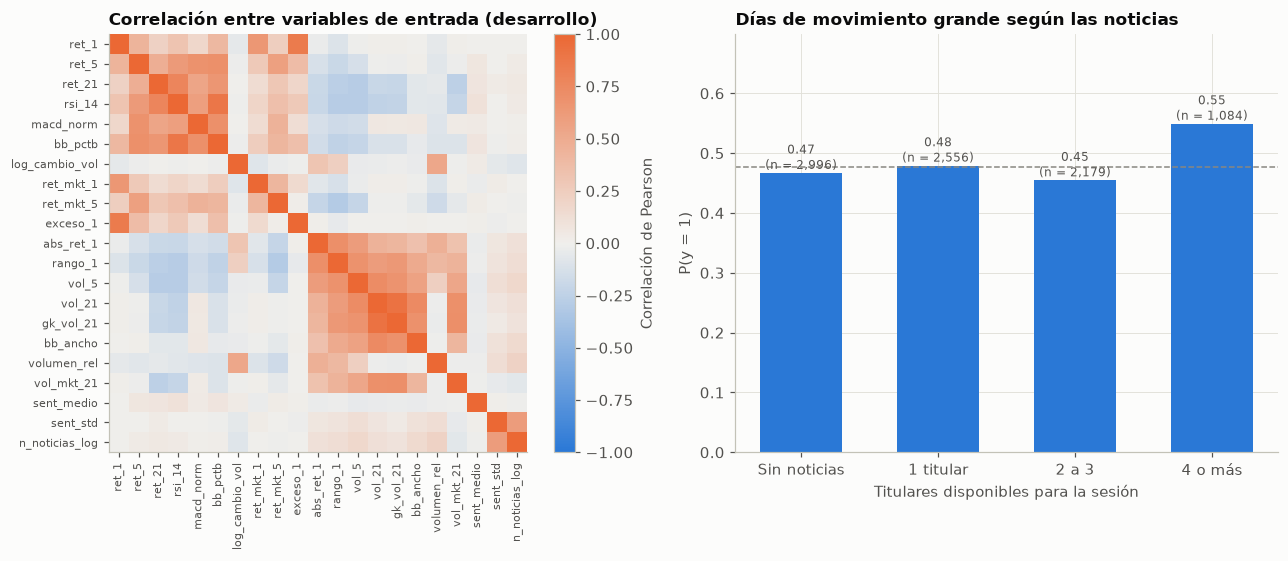

,ADF p (máximo),KPSS p (mínimo),Sin raíz unitaria,Nivel estable
Variable,,,,
ret_1,0.0000,0.1000,True,True
ret_5,0.0000,0.1000,True,True
ret_21,0.0000,0.0788,True,True
rsi_14,0.0000,0.0680,True,True
macd_norm,0.0000,0.1000,True,True
bb_pctb,0.0000,0.1000,True,True
log_cambio_vol,0.0000,0.1000,True,True
ret_mkt_1,0.0000,0.1000,True,True
ret_mkt_5,0.0000,0.1000,True,True


Pares de variables con |correlación| > 0.8: 3


,,correlación
vol_21,gk_vol_21,0.9180
rsi_14,bb_pctb,0.8850
ret_1,exceso_1,0.8560


- **¿Son estacionarias las variables de entrada?** ADF rechaza la raíz unitaria en 21 de 21 variables: ninguna se comporta como un precio en niveles. KPSS, más exigente, rechaza un nivel estable en 9 (abs_ret_1, rango_1, vol_5, vol_21, gk_vol_21, bb_ancho, sent_medio, sent_std, n_noticias_log): no tienen raíz unitaria, pero su media cambia entre regímenes de mercado o con la cobertura de noticias. Es una razón más para validar en orden cronológico.
- **¿Hay multicolinealidad?** Sí: 3 pares superan |ρ| = 0.8; el mayor es vol_21 con gk_vol_21 (ρ = +0.92). El filtro de la sección 5 puntúa cada variable por separado y no elimina esta redundancia; de eso se encarga la regularización de la sección 6.
- **¿Las noticias anticipan los días agitados?** La proporción de días de movimiento grande es 0.467 sin noticias y 0.549 con 4 o más titulares (χ², p < 0.0001). Hay asociación, pero la comparación no controla por nada: la cobertura de noticias y la volatilidad cambian las dos con el año y con la acción. Si el texto aporta algo una vez descontado el precio se mide con la ablación de la sección 7.6.

In [18]:
# [Uso de IA] Celda generada con un asistente de IA · sección 3.6 · prompt: P4.
# Sin instrucción en el documento: sección añadida con P4 (estacionariedad y multicolinealidad de las
#   variables de entrada, solo con datos de desarrollo).
from matplotlib.colors import LinearSegmentedColormap

numericas = COLS_TAB + COLS_SENT

# 1) Estacionariedad de cada variable de entrada: peor caso entre las cinco acciones.
filas = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", InterpolationWarning)
    warnings.simplefilter("ignore", FutureWarning)
    for columna in numericas:
        series = [g[columna].fillna(0.0).to_numpy(dtype=float) for _, g in desarrollo.groupby("ticker")]
        filas.append({"Variable": columna,
                      "ADF p (máximo)": max(adfuller(x, autolag="AIC")[1] for x in series),
                      "KPSS p (mínimo)": min(kpss(x, regression="c", nlags="auto")[1] for x in series)})
ESTAC_X = pd.DataFrame(filas).set_index("Variable")
ESTAC_X["Sin raíz unitaria"] = ESTAC_X["ADF p (máximo)"] < 0.05
ESTAC_X["Nivel estable"] = ESTAC_X["KPSS p (mínimo)"] > 0.05

# 2) Multicolinealidad: pares de variables con |correlación| > 0.8.
CORR = desarrollo[numericas].corr()
triangulo = CORR.where(np.triu(np.ones(CORR.shape, dtype=bool), k=1)).stack()
PARES = triangulo[triangulo.abs() > 0.8].sort_values(key=np.abs, ascending=False)

# 3) Noticias y días de movimiento grande.
titulares = np.rint(np.expm1(desarrollo["n_noticias_log"])).astype(int)
grupo = pd.cut(titulares, bins=[-1, 0, 1, 3, np.inf], labels=["Sin noticias", "1 titular", "2 a 3", "4 o más"])
POR_NOTICIAS = desarrollo.groupby(grupo, observed=True)["y"].agg(["mean", "size"])
POR_NOTICIAS.columns = ["P(y = 1)", "Observaciones"]
_, p_noticias, _, _ = chi2_contingency(pd.crosstab(grupo, desarrollo["y"]))

DIVERGENTE = LinearSegmentedColormap.from_list("divergente", ["#2a78d6", "#f0efec", "#eb6834"])   # azul - neutro - naranja
fig, ejes = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={"width_ratios": [1.25, 1]})
imagen = ejes[0].imshow(CORR, cmap=DIVERGENTE, vmin=-1, vmax=1)
ejes[0].set_xticks(range(len(numericas)))
ejes[0].set_yticks(range(len(numericas)))
ejes[0].set_xticklabels(numericas, rotation=90, fontsize=7)
ejes[0].set_yticklabels(numericas, fontsize=7)
ejes[0].grid(False)
ejes[0].set_title("Correlación entre variables de entrada (desarrollo)")
fig.colorbar(imagen, ax=ejes[0], fraction=0.046, pad=0.04, label="Correlación de Pearson")
ejes[1].bar(POR_NOTICIAS.index.astype(str), POR_NOTICIAS["P(y = 1)"], color=C_ENT, width=0.6)
ejes[1].axhline(y_des.mean(), color=C_REF, linewidth=1, linestyle="--")
for i, (valor, n) in enumerate(zip(POR_NOTICIAS["P(y = 1)"], POR_NOTICIAS["Observaciones"])):
    ejes[1].annotate(f"{valor:.2f}\n(n = {n:,})", (i, valor), ha="center", va="bottom", fontsize=8, color="#52514e")
ejes[1].set_ylim(0, POR_NOTICIAS["P(y = 1)"].max() + 0.15)
ejes[1].set_ylabel("P(y = 1)")
ejes[1].set_xlabel("Titulares disponibles para la sesión")
ejes[1].set_title("Días de movimiento grande según las noticias")
plt.tight_layout()
plt.show()

display(ESTAC_X.round(4))
print(f"Pares de variables con |correlación| > 0.8: {len(PARES)}")
display(PARES.rename("correlación").round(3).to_frame())

sin_raiz, total = int(ESTAC_X["Sin raíz unitaria"].sum()), len(ESTAC_X)
inestables = ESTAC_X.index[~ESTAC_X["Nivel estable"]].tolist()
respuestas = [
    f"- **¿Son estacionarias las variables de entrada?** ADF rechaza la raíz unitaria en {sin_raiz} de {total} variables" +
    (": ninguna se comporta como un precio en niveles. " if sin_raiz == total else
     f"; no la rechaza en {', '.join(ESTAC_X.index[~ESTAC_X['Sin raíz unitaria']])}. ") +
    (f"KPSS, más exigente, rechaza un nivel estable en {len(inestables)} ({', '.join(inestables)}): no tienen raíz unitaria, pero "
     "su media cambia entre regímenes de mercado o con la cobertura de noticias. Es una razón más para validar en orden "
     "cronológico." if inestables else "KPSS tampoco detecta cambios de nivel."),
    (f"- **¿Hay multicolinealidad?** Sí: {len(PARES)} pares superan |ρ| = 0.8; el mayor es {PARES.index[0][0]} con "
     f"{PARES.index[0][1]} (ρ = {PARES.iloc[0]:+.2f}). El filtro de la sección 5 puntúa cada variable por separado y no elimina "
     "esta redundancia; de eso se encarga la regularización de la sección 6." if len(PARES) else
     "- **¿Hay multicolinealidad?** Ningún par de variables supera |ρ| = 0.8."),
    f"- **¿Las noticias anticipan los días agitados?** La proporción de días de movimiento grande es "
    f"{POR_NOTICIAS['P(y = 1)'].iloc[0]:.3f} sin noticias y {POR_NOTICIAS['P(y = 1)'].iloc[-1]:.3f} con 4 o más titulares "
    f"(χ², {p_txt(p_noticias)}). " +
    ("Hay asociación, pero la comparación no controla por nada: la cobertura de noticias y la volatilidad cambian las dos con el "
     "año y con la acción. Si el texto aporta algo una vez descontado el precio se mide con la ablación de la sección 7.6."
     if p_noticias < 0.05 else
     "No hay una asociación apreciable. La ablación de la sección 7.6 lo contrasta con el modelo completo."),
]
display(Markdown("\n".join(respuestas)))

## 4. Particionado causal y *pipelines*

### 4.1 Partición por fechas con brecha

**Por qué no `RepeatedStratifiedKFold`.** La rúbrica lo sugiere por defecto y pide justificar si corresponde usarlo. Aquí no corresponde: esa clase baraja las observaciones, de modo que algunos pliegues entrenarían con 2021 para validar 2016. El modelo vería el futuro y la estimación del error quedaría sesgada a la baja. Tampoco se puede estratificar: igualar la proporción de clases entre pliegues exige elegir qué filas van a cada uno, y eso rompe el orden temporal. Además, la proporción de días agitados cambia de un año a otro (sección 2.3); esa variación es parte de lo que el modelo debe enfrentar, no un defecto que corregir.

**Por qué no `TimeSeriesSplit` directamente.** Respeta el orden, pero cuenta **filas**, no fechas. En un panel con cinco acciones por día, un corte puede caer en medio de una sesión y dejar dos acciones de ese día en entrenamiento y tres en validación. Además, `gap=5` purgaría cinco filas, que equivalen a un solo día.

**Solución.** Se aplica `TimeSeriesSplit` [14] sobre las **fechas únicas** y luego se proyecta cada bloque de fechas a todas sus filas. Para el pliegue $k$:

$$\mathcal{T}_k = \{t : t \le a_k\}, \qquad \mathcal{V}_k = \{t : a_k + g < t \le b_k\}, \qquad g = 5$$

**Qué hace la brecha.** La etiqueta es de un solo día, así que no se solapa entre observaciones. La brecha responde a otro problema: la volatilidad es persistente (sección 2.5), por lo que el último día de entrenamiento y el primero de validación son casi la misma observación del régimen de mercado. Purgar cinco sesiones reduce esa dependencia y hace más honesta la estimación del error. Es la idea de purga que propone López de Prado [15] para validación cruzada en finanzas.

**Repeticiones.** La rúbrica acepta 2 repeticiones de 5 pliegues, es decir, 10 valores pareados. En una partición cronológica no existen repeticiones distintas sin barajar, así que los 10 valores se obtienen con **10 pliegues cronológicos**.

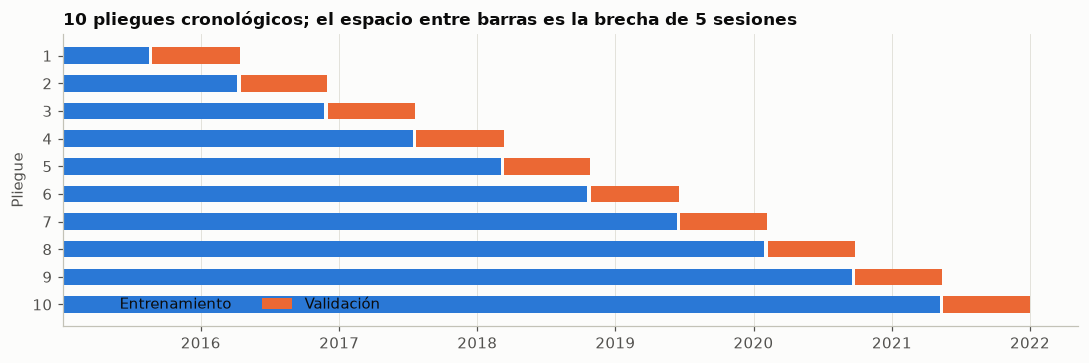

,Entrena hasta,Valida desde,Valida hasta,Filas entrenamiento,Filas validación
Pliegue,,,,,
1,2015-08-18,2015-08-26,2016-04-14,790,800
2,2016-04-07,2016-04-15,2016-11-30,1590,800
3,2016-11-22,2016-12-01,2017-07-21,2390,800
4,2017-07-14,2017-07-24,2018-03-12,3190,800
5,2018-03-05,2018-03-13,2018-10-26,3990,800
6,2018-10-19,2018-10-29,2019-06-19,4790,800
7,2019-06-12,2019-06-20,2020-02-06,5590,800
8,2020-01-30,2020-02-07,2020-09-24,6390,800
9,2020-09-17,2020-09-25,2021-05-14,7190,800


In [19]:
# [Uso de IA] Celda generada con un asistente de IA · sección 4.1 · prompt: P2.
# Instrucción (fase 3): «Particionado por Fechas Únicas (`date_splits`): Prohibido el `shuffle=True`. En un
#   panel apilado, las 5 acciones de una misma fecha deben pertenecer al mismo bloque. Implementar partición
#   sobre fechas únicas proyectada luego a las filas.»
#   «Purga temporal (Gap): Configurar `gap = 5` sesiones bursátiles entre entrenamiento y validación para
#   evitar solapamiento inducido por indicadores con ventanas móviles de 5 días.»
from sklearn.model_selection import TimeSeriesSplit


def particion_por_fechas(fechas, n_pliegues=K_PLIEGUES, brecha=BRECHA):
    """Pliegues cronológicos definidos sobre fechas únicas y proyectados a las filas del panel.

    Devuelve una lista de (indices_entrenamiento, indices_validacion) posicionales.
    """
    dias, codigo = np.unique(np.asarray(fechas), return_inverse=True)   # codigo[i] = nº de sesión de la fila i
    pliegues = []
    for ent, val in TimeSeriesSplit(n_splits=n_pliegues, gap=brecha).split(dias):
        i_ent = np.flatnonzero(np.isin(codigo, ent))
        i_val = np.flatnonzero(np.isin(codigo, val))
        assert codigo[i_ent].max() < codigo[i_val].min()                # el entrenamiento es anterior
        assert val[0] - ent[-1] - 1 == brecha                           # brecha medida en sesiones
        assert not set(codigo[i_ent]) & set(codigo[i_val])              # ninguna fecha partida
        pliegues.append((i_ent, i_val))
    return pliegues


FECHAS_DES = desarrollo["fecha"].to_numpy()
PLIEGUES = particion_por_fechas(FECHAS_DES)

fig, eje = plt.subplots(figsize=(10, 3.4))
for k, (i_ent, i_val) in enumerate(PLIEGUES, start=1):
    eje.barh(k, FECHAS_DES[i_ent].max() - FECHAS_DES[i_ent].min(), left=FECHAS_DES[i_ent].min(),
             color=C_ENT, height=0.6, label="Entrenamiento" if k == 1 else None)
    eje.barh(k, FECHAS_DES[i_val].max() - FECHAS_DES[i_val].min(), left=FECHAS_DES[i_val].min(),
             color=C_VAL, height=0.6, label="Validación" if k == 1 else None)
eje.set_yticks(range(1, K_PLIEGUES + 1))
eje.invert_yaxis()
eje.set_ylabel("Pliegue")
eje.set_title(f"{K_PLIEGUES} pliegues cronológicos; el espacio entre barras es la brecha de {BRECHA} sesiones")
eje.legend(loc="lower left", ncol=2)
eje.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

pd.DataFrame([{"Pliegue": k, "Entrena hasta": pd.Timestamp(FECHAS_DES[e].max()).date(),
               "Valida desde": pd.Timestamp(FECHAS_DES[v].min()).date(),
               "Valida hasta": pd.Timestamp(FECHAS_DES[v].max()).date(),
               "Filas entrenamiento": len(e), "Filas validación": len(v)}
              for k, (e, v) in enumerate(PLIEGUES, start=1)]).set_index("Pliegue")

### 4.2 Winsorizador causal

scikit-learn no trae un recorte por cuantiles que respete el contrato `fit` / `transform`, así que se implementa uno. La clase separa las dos fases:

- `fit(X)` estima $q_{0.01}$ y $q_{0.99}$ de cada columna **con los datos que recibe**, que dentro de un `Pipeline` son siempre los de entrenamiento.
- `transform(X)` recorta con esos límites ya guardados, sin recalcular nada.

Si los cuantiles se calcularan sobre toda la tabla con pandas, los extremos del período de validación fijarían los límites aplicados al entrenamiento. La prueba unitaria de la celda comprueba que los límites no se mueven al transformar datos nuevos con valores más extremos.

In [20]:
# [Uso de IA] Celda generada con un asistente de IA · sección 4.2 · prompt: P2.
# Instrucción (fase 2 y diagrama de arquitectura): «Implementar winsorización causal en percentiles [1%,
#   99%] ajustada únicamente dentro de cada pliegue temporal»
#   «Tabular: CausalWinsorizer + Log-transform»
# Clase adaptada del Anexo A de la propuesta metodológica del proyecto.
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.utils.validation import check_array, check_is_fitted


class CausalWinsorizer(TransformerMixin, BaseEstimator):
    """Recorta cada columna a los cuantiles [inferior, superior] estimados en fit()."""

    def __init__(self, inferior=0.01, superior=0.99):
        self.inferior = inferior
        self.superior = superior

    def fit(self, X, y=None):
        if not 0 <= self.inferior < self.superior <= 1:
            raise ValueError("Cuantiles inválidos.")
        a = check_array(X, dtype=float)
        self.n_features_in_ = a.shape[1]
        self.limites_ = np.quantile(a, [self.inferior, self.superior], axis=0)   # aprendidos SOLO aquí
        return self

    def transform(self, X):
        check_is_fitted(self, "limites_")
        a = check_array(X, dtype=float)
        return np.clip(a, self.limites_[0], self.limites_[1])                    # sin recalcular cuantiles

    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features, dtype=object)


# Prueba unitaria: los límites provienen del entrenamiento y no cambian con datos nuevos.
rng = np.random.default_rng(SEMILLA)
x_ent, x_nuevo = rng.normal(size=(1000, 1)), np.array([[-50.0], [0.0], [50.0]])
w = CausalWinsorizer().fit(x_ent)
limites_antes = w.limites_.copy()
recortado = w.transform(x_nuevo)
assert np.array_equal(w.limites_, limites_antes)
assert recortado.min() == limites_antes[0, 0] and recortado.max() == limites_antes[1, 0]
print(f"Límites aprendidos en entrenamiento: [{limites_antes[0, 0]:.3f}, {limites_antes[1, 0]:.3f}]")
print(f"Datos nuevos {x_nuevo.ravel()} -> {recortado.ravel().round(3)}")

Límites aprendidos en entrenamiento: [-2.334, 2.143]
Datos nuevos [-50.   0.  50.] -> [-2.334  0.     2.143]


### 4.3 Preprocesador completo

Cada grupo de columnas recibe el tratamiento que el EDA justificó. Todo vive dentro de un `ColumnTransformer` de scikit-learn [16], y cada paso con parámetros aprende esos parámetros únicamente cuando el *pipeline* recibe `.fit()` con datos de entrenamiento.

| Rama | Columnas | Pasos | Parámetros aprendidos en `fit` |
|---|---|---|---|
| `momentum` | Retornos, osciladores, mercado | Winsorizar → estandarizar | $q_{0.01}, q_{0.99}, \mu, \sigma$ |
| `asimetricas` | Volatilidad y volumen | Winsorizar → Yeo-Johnson (estandariza) | $q_{0.01}, q_{0.99}, \lambda, \mu, \sigma$ |
| `sentimiento` | Sentimiento medio, dispersión, conteo | Imputar 0 → estandarizar | $\mu, \sigma$ |
| `categoricas` | Acción, día de la semana | Codificación *one-hot* | Categorías vistas |
| `indicadores` | `sin_noticias` | Sin cambios | — |
| `embeddings` | 768 dimensiones de FinBERT | Imputar media → estandarizar → PCA blanqueado | $\mu, \sigma$, componentes principales y sus varianzas |

Dos aclaraciones sobre la rama de texto:

- **Imputación.** Un día sin noticias se imputa con la media de entrenamiento, que tras estandarizar equivale al vector cero: un punto neutro. El indicador `sin_noticias` permite al modelo distinguir "sin noticias" de "noticias neutras".
- **PCA no es selección de características.** PCA es una proyección lineal $\mathbf{z} = \mathbf{W}^\top(\mathbf{e} - \boldsymbol{\mu})$ que combina las 768 dimensiones; no descarta ninguna por separado. Se usa porque 768 atributos frente a pocos miles de filas invitan al sobreajuste. El número de componentes es un hiperparámetro (sección 6).
- **Blanqueado (`whiten=True`).** Cada componente se divide por su desviación estándar, $z_k = \mathbf{w}_k^\top(\mathbf{e} - \boldsymbol{\mu}) / \sqrt{\lambda_k}$, para que tenga varianza 1 como las variables tabulares. Sin este paso, los primeros componentes tendrían una varianza decenas de veces mayor: la penalización de la regresión logística los castigaría menos que al resto y dominarían cualquier distancia, incluida la de t-SNE.

Las dos primeras ramas, que contienen las variables de precio y volumen, se agrupan en un sub-*pipeline* `tabular`, al que la sección 5 añade el filtro de selección. Todo lo que proviene de FinBERT —los tres resúmenes de sentimiento y los *embeddings*— va por ramas propias y **no pasa por el filtro**, como indica el diagrama de clase para la transferencia de aprendizaje.

In [21]:
# [Uso de IA] Celda generada con un asistente de IA · sección 4.3 · prompts: P2, P3, P4.
# Instrucción (fase 3 y diagrama de arquitectura): «Encapsulamiento en Pipeline: Todo escalamiento
#   (`StandardScaler`), transformación e imputación debe ejecutarse mediante `Pipeline` y
#   `ColumnTransformer` de scikit-learn, garantizando que `.fit()` corra exclusivamente en el subconjunto de
#   entrenamiento de cada pliegue.»
#   «Feature Selection tipo Filter (ANOVA/MutualInfo) SOLO sobre ramas tabulares crudas»
from sklearn import set_config
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, PowerTransformer, StandardScaler


def crear_preprocesador(k_filtro=10, n_componentes=8, con_texto=True):
    """Preprocesador completo. con_texto=False omite todo lo derivado de noticias (ablación de la sección 7.6)."""
    momentum = Pipeline([("recorte", CausalWinsorizer()), ("escala", StandardScaler())])
    asimetricas = Pipeline([("recorte", CausalWinsorizer()),
                            ("potencia", PowerTransformer(method="yeo-johnson", standardize=True))])
    # El filtro actúa SOLO sobre las variables de precio y volumen (sección 5).
    tabular = Pipeline([("ramas", ColumnTransformer([("momentum", momentum, COLS_MOM),
                                                     ("asimetricas", asimetricas, COLS_ASIM)])),
                        ("filtro", SelectKBest(f_classif, k=min(k_filtro, len(COLS_TAB))))])
    bloques = [("tabular", tabular, COLS_TAB),
               ("categoricas", OneHotEncoder(handle_unknown="ignore", sparse_output=False), COLS_CAT)]
    if con_texto:
        # Todo lo que proviene de FinBERT queda FUERA del filtro: resúmenes de sentimiento y embeddings.
        sentimiento = Pipeline([("imputa", SimpleImputer(strategy="constant", fill_value=0.0)),
                                ("escala", StandardScaler())])
        embeddings = Pipeline([("imputa", SimpleImputer(strategy="mean")),
                               ("escala", StandardScaler()),
                               ("pca", PCA(n_components=n_componentes, whiten=True, random_state=SEMILLA))])
        bloques += [("sentimiento", sentimiento, COLS_SENT),
                    ("indicadores", "passthrough", COLS_IND),
                    ("embeddings", embeddings, COLS_EMB)]
    return ColumnTransformer(bloques, sparse_threshold=0.0)


set_config(display="diagram")
crear_preprocesador()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tabular', ...), ('categoricas', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and

## 5. Selección de características (tipo filtro)

La rúbrica pide un método de tipo **filtro** [17] dentro del *pipeline* y permite omitirlo cuando se usa transferencia de aprendizaje. Aquí se aplica solo donde tiene sentido:

- **Sí, sobre las variables de precio y volumen.** Son datos tabulares: cada una es interpretable por separado y varias son redundantes entre sí.
- **No, sobre nada derivado de FinBERT.** Ni los *embeddings* ni los resúmenes de sentimiento pasan por el filtro. En un vector denso el significado está repartido entre todas las dimensiones. Evaluar cada una por separado y quedarse con las "mejores" rompe esa representación.

**Criterio.** El estadístico $F$ del análisis de varianza de una vía compara, para cada atributo $x_j$, la variación entre las medias de las dos clases con la variación dentro de ellas:

$$F_j = \frac{\sum_{c \in \{0,1\}} m_c\,(\bar x_{j,c} - \bar x_j)^2 \,/\, (C - 1)}{\sum_{c}\sum_{i \in c} (x_{j,i} - \bar x_{j,c})^2 \,/\, (m - C)}, \qquad C = 2$$

Un $F_j$ alto indica que el atributo separa las clases. `SelectKBest` conserva los $k$ atributos de mayor $F$, y $k$ se optimiza en la sección 6. Es un método de filtro porque puntúa cada variable sin entrenar el clasificador.

**Por qué va dentro del *pipeline*.** $F$ se calcula con la etiqueta $y$. Si se eligieran las variables usando todos los datos, la selección ya habría visto las etiquetas de validación. Al estar en el *pipeline*, la selección se repite en cada pliegue solo con su bloque de entrenamiento.

La celda siguiente ajusta el sub-*pipeline* tabular en el entrenamiento del último pliegue para ilustrar los puntajes. Es solo una vista con $k = 10$ de ejemplo: el valor de $k$ lo elige Optuna en la sección 6 y la selección se recalcula en cada ajuste.

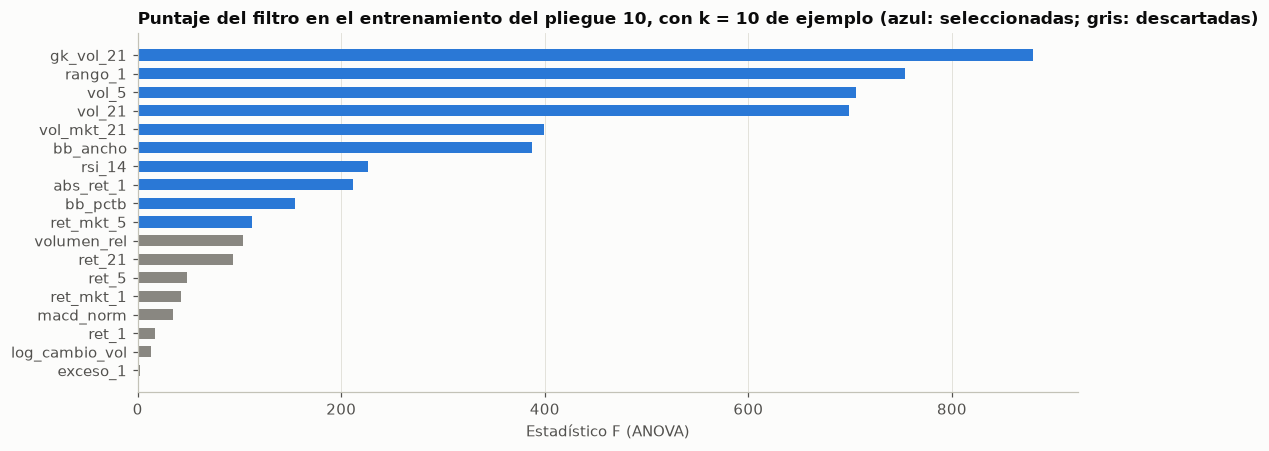

Variables con p < 0.05: 17 de 18


,F,p-valor,seleccionada
gk_vol_21,879.8996,0.0000,True
rango_1,753.4862,0.0000,True
vol_5,705.5548,0.0000,True
vol_21,698.9897,0.0000,True
vol_mkt_21,398.7388,0.0000,True
bb_ancho,386.9584,0.0000,True
rsi_14,226.1809,0.0000,True
abs_ret_1,211.2849,0.0000,True
bb_pctb,154.6996,0.0000,True
ret_mkt_5,112.7353,0.0000,True


In [22]:
# [Uso de IA] Celda generada con un asistente de IA · sección 5 · prompts: P2, P5.
# Instrucción (diagrama de arquitectura): «Feature Selection tipo Filter (ANOVA/MutualInfo) SOLO sobre ramas
#   tabulares crudas»
i_ent, _ = PLIEGUES[-1]
pre_demo = crear_preprocesador(k_filtro=10)
sub_tabular = pre_demo.transformers[0][1]                    # sub-pipeline 'tabular' aún sin ajustar
sub_tabular.fit(X_des.iloc[i_ent][COLS_TAB], y_des[i_ent])   # ajuste SOLO con entrenamiento del pliegue 10

filtro = sub_tabular.named_steps["filtro"]
puntajes = pd.DataFrame({"F": filtro.scores_, "p-valor": filtro.pvalues_,
                         "seleccionada": filtro.get_support()}, index=COLS_TAB).sort_values("F", ascending=False)

fig, eje = plt.subplots(figsize=(10, 4.2))
orden = puntajes.sort_values("F")
eje.barh(orden.index, orden["F"], height=0.6,
         color=[C_ENT if s else C_REF for s in orden["seleccionada"]])
eje.set_xlabel("Estadístico F (ANOVA)")
eje.set_title("Puntaje del filtro en el entrenamiento del pliegue 10, con k = 10 de ejemplo (azul: seleccionadas; gris: descartadas)")
eje.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
print(f"Variables con p < 0.05: {int((puntajes['p-valor'] < 0.05).sum())} de {len(puntajes)}")
puntajes.head(10)

## 6. Optimización de hiperparámetros

### 6.1 Las dos técnicas y su regularización

Ambos modelos reciben **exactamente el mismo preprocesador**. Así la comparación de la sección 7 aísla el efecto del algoritmo de aprendizaje.

**M0 — Regresión logística con red elástica** [18]. Modelo lineal: $\hat p = \sigma(\mathbf{w}^\top\mathbf{z} + b)$. Minimiza

$$J(\mathbf{w}) = -\frac{1}{m}\sum_{j=1}^{m}\left[y_j \ln \hat p_j + (1 - y_j)\ln(1 - \hat p_j)\right] + \lambda\left[\alpha\,\lVert\mathbf{w}\rVert_1 + \frac{1-\alpha}{2}\lVert\mathbf{w}\rVert_2^2\right]$$

- El término $L_1$ ($\lVert\mathbf{w}\rVert_1$) tiene una esquina en cero: su subgradiente empuja con fuerza constante y lleva coeficientes exactamente a 0. Elimina variables ruidosas.
- El término $L_2$ ($\lVert\mathbf{w}\rVert_2^2$) encoge los coeficientes en proporción a su tamaño sin anularlos. Estabiliza la solución cuando hay variables correlacionadas, como `ret_1`, `ret_mkt_1` y `exceso_1`.
- En scikit-learn, `C` $= 1/\lambda$ y `l1_ratio` $= \alpha$.

**M1 — *Gradient boosting* por histogramas** [19]. Modelo no lineal aditivo: $F_M(\mathbf{z}) = F_0 + \nu\sum_{k=1}^{M} f_k(\mathbf{z})$, donde cada árbol $f_k$ se ajusta al gradiente de la entropía cruzada del modelo anterior. Su capacidad se controla con la tasa de aprendizaje $\nu$, el número de árboles $M$, la profundidad máxima, el mínimo de muestras por hoja y una penalización $L_2$ sobre los valores de las hojas.

**Parada temprana desactivada.** `HistGradientBoostingClassifier` activa `early_stopping` de forma automática por encima de 10 000 filas y toma su validación interna con una partición **aleatoria**. En una serie de tiempo eso mezcla pasado y futuro, así que se fija `early_stopping=False` y el número de árboles se optimiza como un hiperparámetro más sobre los pliegues cronológicos.

**Dos referencias.** Para saber si un modelo aprende algo hacen falta puntos de comparación que no aprendan nada:

- *Sin habilidad:* predecir siempre la tasa base global del entrenamiento. Es el equivalente al $\ln 2 \approx 0.693$ de un clasificador que no aprendió nada.
- *Tasa base por acción:* predecir para cada acción su propia frecuencia histórica de días agitados. Es más exigente, porque ya sabe que unas acciones son más volátiles que otras. Un modelo que solo igualara esta referencia no estaría anticipando nada; estaría recordando qué acción es cuál.

In [23]:
# [Uso de IA] Celda generada con un asistente de IA · sección 6.1 · prompts: P2, P3.
# Instrucción (fases 1 y 6): «Modelos en competencia: M_0 (Baseline): Regresión Logística ElasticNet
#   regularizada (+ referencia pasiva Buy & Hold). M_1 (Avanzado): HistGradientBoostingClassifier / Random
#   Forest optimizado multimodal.»
#   «Función de pérdida optimizada: Weighted Binary Cross-Entropy / Log-Loss con penalización elástica L_1 +
#   L_2.»
# Difiere: no se usa Random Forest; el documento llama «Baseline» a M0, pero aquí M0 es una de las dos
#   técnicas optimizadas y el baseline simple es otro modelo (celda siguiente).
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import cross_validate

VERSION_SK = tuple(int(x) for x in sklearn.__version__.split(".")[:2])


def crear_modelo(nombre, k_filtro=10, n_componentes=8, con_texto=True, **hp):
    """Pipeline completo: preprocesador (idéntico para ambos) + clasificador."""
    pre = crear_preprocesador(k_filtro, n_componentes, con_texto)
    if nombre == "M0":
        args = dict(solver="saga", max_iter=5000, class_weight=PESO_CLASES, random_state=SEMILLA, **hp)
        if VERSION_SK < (1, 8):
            args["penalty"] = "elasticnet"        # desde scikit-learn 1.8 basta con indicar l1_ratio
        clf = LogisticRegression(**args)
    elif nombre == "M1":
        clf = HistGradientBoostingClassifier(early_stopping=False, class_weight=PESO_CLASES,
                                             random_state=SEMILLA, **hp)
    else:
        raise ValueError(f"Modelo desconocido: {nombre}")
    return Pipeline([("pre", pre), ("clf", clf)])


def perdida_por_pliegue(modelo):
    """Log-loss de validación en cada uno de los K pliegues cronológicos."""
    r = cross_validate(modelo, X_des, y_des, cv=PLIEGUES, scoring="neg_log_loss", n_jobs=-1)
    return -r["test_score"]


# Referencia sin habilidad: predecir siempre la tasa base del bloque de entrenamiento de cada pliegue.
SIN_HABILIDAD = np.array([log_loss(y_des[v], np.full(len(v), y_des[e].mean()), labels=[0, 1])
                          for e, v in PLIEGUES])
# Segunda referencia, más exigente: predecir para cada acción su propia tasa base de entrenamiento.
TICKER_DES = desarrollo["ticker"].to_numpy()


def prob_por_accion(tickers_ent, y_ent, tickers_eval):
    tasas = pd.Series(y_ent).groupby(tickers_ent).mean()
    return tasas.reindex(tickers_eval).to_numpy()


REF_ACCION = np.array([log_loss(y_des[v], prob_por_accion(TICKER_DES[e], y_des[e], TICKER_DES[v]), labels=[0, 1])
                       for e, v in PLIEGUES])
# Exactitud de predecir siempre la clase mayoritaria del bloque de entrenamiento.
EXACTITUD_BASE = np.array([np.mean(y_des[v] == int(y_des[e].mean() > 0.5)) for e, v in PLIEGUES])
print(f"Referencia sin habilidad (media de {K_PLIEGUES} pliegues): log-loss = {SIN_HABILIDAD.mean():.4f} | "
      f"exactitud = {EXACTITUD_BASE.mean():.4f}")
print(f"Referencia de tasa base por acción: log-loss = {REF_ACCION.mean():.4f}")
crear_modelo("M0", C=1.0, l1_ratio=0.5)

Referencia sin habilidad (media de 10 pliegues): log-loss = 0.6978 | exactitud = 0.4937
Referencia de tasa base por acción: log-loss = 0.6770


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('pre', ...), ('clf', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('tabular', ...), ('categoricas', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the 

#### Baseline: lo más simple posible

Antes de optimizar nada conviene probar lo primero que funcionaría y ver qué tan lejos llega. El *baseline* es deliberadamente simple: estandarizar las variables de precio y volumen y ajustar una regresión logística con **todos sus parámetros por defecto**. No usa noticias, ni filtro, ni winsorización, ni búsqueda de hiperparámetros.

Sirve para dos cosas. Da una primera idea de si hay señal en los datos, y fija el punto contra el que se medirá después cuánto aportan la optimización y el resto del *pipeline*. Se evalúa en los mismos 10 pliegues cronológicos.

In [24]:
# [Uso de IA] Celda generada con un asistente de IA · sección 6.1 · prompt: P6.
# Sin instrucción en el documento: baseline con parámetros por defecto, añadido con P6.
def crear_baseline():
    """Estandarizar las variables de precio y volumen + regresión logística con parámetros por defecto."""
    return Pipeline([("pre", ColumnTransformer([("escala", StandardScaler(), COLS_TAB)])),
                     ("clf", LogisticRegression())])


r = cross_validate(crear_baseline(), X_des, y_des, cv=PLIEGUES,
                   scoring={"log_loss": "neg_log_loss", "exactitud": "accuracy", "auc": "roc_auc"}, n_jobs=-1)
BASELINE_CV = -r["test_log_loss"]
BASELINE_RESUMEN = pd.Series({"Log-loss": BASELINE_CV.mean(), "Exactitud": r["test_exactitud"].mean(), "AUC": r["test_auc"].mean()},
                             name="Baseline simple (media de 10 pliegues)")
display(BASELINE_RESUMEN.to_frame().T)
display(Markdown(
    f"**Primera lectura.** Sin optimizar nada, el baseline obtiene un log-loss de {BASELINE_CV.mean():.4f} "
    f"(referencias: {SIN_HABILIDAD.mean():.4f} y {REF_ACCION.mean():.4f}), una exactitud de {r['test_exactitud'].mean():.3f} "
    f"(clase mayoritaria: {EXACTITUD_BASE.mean():.3f}) y un AUC de {r['test_auc'].mean():.3f}. " +
    ("Queda por debajo de las dos referencias: hay señal en las variables de precio y volumen incluso con el modelo más simple. "
     "Las secciones siguientes miden cuánto se gana sobre este punto de partida."
     if BASELINE_CV.mean() < min(SIN_HABILIDAD.mean(), REF_ACCION.mean()) else
     "No supera a las referencias: con el modelo más simple no se observa señal.")))

,Log-loss,Exactitud,AUC
Baseline simple (media de 10 pliegues),0.6402,0.6390,0.6723


**Primera lectura.** Sin optimizar nada, el baseline obtiene un log-loss de 0.6402 (referencias: 0.6978 y 0.6770), una exactitud de 0.639 (clase mayoritaria: 0.494) y un AUC de 0.672. Queda por debajo de las dos referencias: hay señal en las variables de precio y volumen incluso con el modelo más simple. Las secciones siguientes miden cuánto se gana sobre este punto de partida.

### 6.2 Búsqueda con Optuna sobre los pliegues cronológicos

**Protocolo.** Cada configuración candidata se evalúa con el promedio del *log-loss* de validación en los 10 pliegues. El conjunto de prueba no participa.

**Algoritmo.** Optuna [20] usa TPE (*Tree-structured Parzen Estimator*) [21]. Tras cada evaluación divide las configuraciones probadas en "buenas" y "malas" según un cuantil de la pérdida, estima una densidad para cada grupo, $\ell(\theta)$ y $g(\theta)$, y propone la siguiente configuración donde el cociente $\ell(\theta)/g(\theta)$ es mayor. Concentra las evaluaciones en las zonas prometedoras, a diferencia de una rejilla exhaustiva.

**Espacio de búsqueda.**

| Hiperparámetro | Modelo | Rango | Efecto |
|---|---|---|---|
| `k_filtro` | ambos | 4 a 18 | Variables de precio y volumen que conserva el filtro |
| `n_componentes` | ambos | 2, 4, 8, 16, 32 | Componentes principales de los *embeddings* |
| `C` $= 1/\lambda$ | M0 | $10^{-4}$ a $10$ (log) | Fuerza de regularización |
| `l1_ratio` $= \alpha$ | M0 | 0 a 1 | Mezcla entre $L_2$ y $L_1$ |
| `learning_rate` $\nu$ | M1 | 0.01 a 0.2 (log) | Contribución de cada árbol |
| `max_iter` $M$ | M1 | 50 a 400 | Número de árboles |
| `max_depth` | M1 | 2 a 6 | Orden de las interacciones |
| `min_samples_leaf` | M1 | 20 a 200 | Tamaño mínimo de hoja |
| `l2_regularization` | M1 | $10^{-3}$ a $10^{2}$ (log) | Penalización de las hojas |

**Por qué no validación anidada.** La rúbrica la desaconseja por su costo. La consecuencia se asume de forma explícita: como los hiperparámetros se eligen con los mismos pliegues que luego se reportan, la pérdida de validación del mejor candidato es algo optimista. La estimación limpia del error es la del conjunto de prueba (sección 7.4).

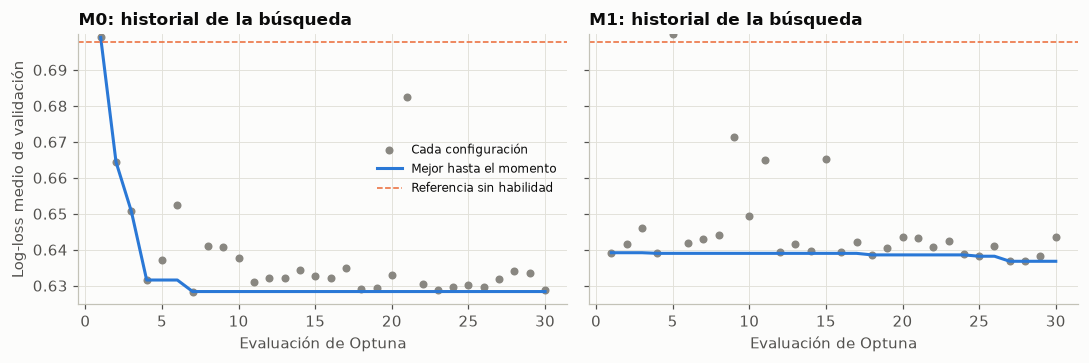

M0: mejor log-loss de validación = 0.6284 | {'k_filtro': 12, 'n_componentes': 4, 'C': 0.09761125443110447, 'l1_ratio': 0.9218742350231168}
M1: mejor log-loss de validación = 0.6368 | {'k_filtro': 15, 'n_componentes': 2, 'learning_rate': 0.04683485968738864, 'max_iter': 129, 'max_depth': 3, 'min_samples_leaf': 105, 'l2_regularization': 5.560375226188542}


In [25]:
# [Uso de IA] Celda generada con un asistente de IA · sección 6.2 · prompt: P2.
# Instrucción (fase 4): «Protocolo de búsqueda: Optimizar sobre los bloques temporales de validación interna
#   usando `RandomizedSearchCV` o `Optuna` (con métrica `neg_log_loss`).»
import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)


def espacio(nombre, trial):
    hp = dict(k_filtro=trial.suggest_int("k_filtro", 4, len(COLS_TAB)),
              n_componentes=trial.suggest_categorical("n_componentes", [2, 4, 8, 16, 32]))
    if nombre == "M0":
        hp.update(C=trial.suggest_float("C", 1e-4, 10.0, log=True),
                  l1_ratio=trial.suggest_float("l1_ratio", 0.0, 1.0))
    else:
        hp.update(learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                  max_iter=trial.suggest_int("max_iter", 50, 400),
                  max_depth=trial.suggest_int("max_depth", 2, 6),
                  min_samples_leaf=trial.suggest_int("min_samples_leaf", 20, 200),
                  l2_regularization=trial.suggest_float("l2_regularization", 1e-3, 100.0, log=True))
    return hp


def optimizar(nombre):
    estudio = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=SEMILLA))
    estudio.optimize(lambda trial: perdida_por_pliegue(crear_modelo(nombre, **espacio(nombre, trial))).mean(),
                     n_trials=N_PRUEBAS)
    return estudio


ESTUDIOS = {nombre: optimizar(nombre) for nombre in ["M0", "M1"]}
MEJORES = {nombre: e.best_params for nombre, e in ESTUDIOS.items()}

fig, ejes = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for eje, (nombre, estudio) in zip(ejes, ESTUDIOS.items()):
    valores = np.array([t.value for t in estudio.trials])
    eje.scatter(range(1, len(valores) + 1), valores, s=18, color=C_REF, label="Cada configuración", zorder=2)
    eje.plot(range(1, len(valores) + 1), np.minimum.accumulate(valores), color=C_ENT, label="Mejor hasta el momento")
    eje.axhline(SIN_HABILIDAD.mean(), color=C_VAL, linewidth=1, linestyle="--", label="Referencia sin habilidad")
    eje.set_title(f"{nombre}: historial de la búsqueda")
    eje.set_xlabel("Evaluación de Optuna")
    eje.xaxis.get_major_locator().set_params(integer=True)
    eje.set_ylim(top=min(valores.max(), SIN_HABILIDAD.mean() + 0.03))
ejes[0].set_ylabel("Log-loss medio de validación")
ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

for nombre in ESTUDIOS:
    print(f"{nombre}: mejor log-loss de validación = {ESTUDIOS[nombre].best_value:.4f} | {MEJORES[nombre]}")

### 6.3 Gráfica de optimización de un hiperparámetro

La rúbrica pide la curva de pérdida frente a un hiperparámetro, con entrenamiento y validación a la vez. Se muestra una por modelo, dejando los demás hiperparámetros en su valor óptimo.

**M0: la fuerza de regularización $\lambda = 1/C$.** Es la misma gráfica del ejemplo de la rúbrica.

- A la izquierda ($\lambda$ pequeña) el modelo es libre: la pérdida de entrenamiento es baja y la de validación sube. Es **alta varianza**.
- A la derecha ($\lambda$ grande) los coeficientes se anulan y ambas pérdidas convergen a la referencia sin habilidad. Es **alto sesgo**.
- El valor adecuado es el mínimo de la curva de validación.

*Detalle numérico.* En el extremo derecho las dos curvas deberían coincidir con la referencia. Si quedan apenas por encima, la causa es el optimizador: con una penalización tan fuerte todos los coeficientes valen cero desde la primera pasada, SAGA da el ajuste por terminado y el intercepto queda sin converger del todo. Es un efecto del criterio de parada, no una propiedad del modelo.

**M1: el número de árboles $M$.** Cada árbol reduce la pérdida de entrenamiento. La de validación deja de bajar cuando los árboles nuevos empiezan a ajustar ruido.

Las bandas muestran $\pm 1$ desviación estándar ($\pm 1\sigma$) entre los 10 pliegues. Son anchas porque la dificultad cambia mucho de un período a otro; lo que importa es la posición relativa de las dos curvas, que se evalúan sobre los mismos pliegues.

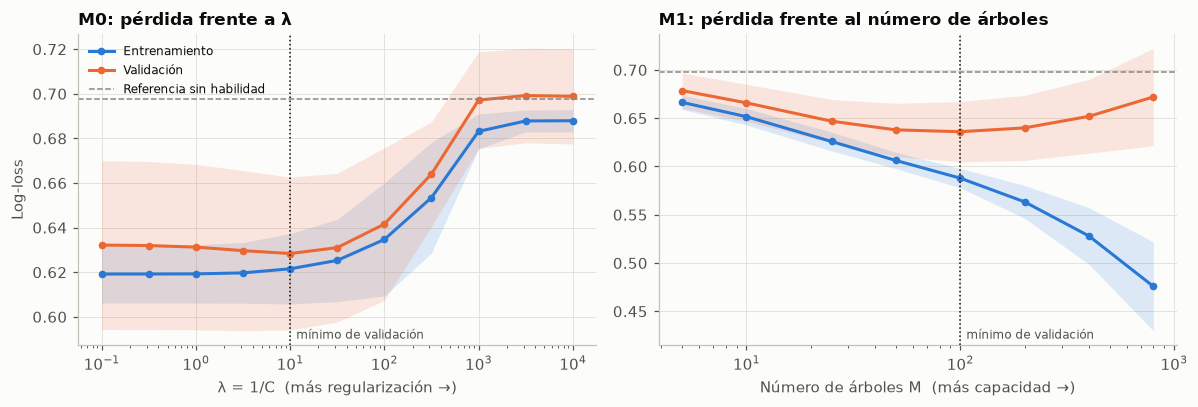

M0: mínimo de validación en λ = 10 (C = 0.1); Optuna eligió C = 0.0976
M1: mínimo de validación en M = 100; Optuna eligió M = 129


In [26]:
# [Uso de IA] Celda generada con un asistente de IA · sección 6.3 · prompts: P2, P4.
# Instrucción (fase 4): «Gráfica de optimización de hiperparámetro: Graficar obligatoriamente la curva
#   bidimensional de un hiperparámetro clave (ej. fuerza de regularización C o λ en regresión logística, o
#   profundidad/tasa de aprendizaje en árboles) mostrando simultáneamente la curva de entrenamiento y la de
#   validación para diagnosticar el compromiso sesgo-varianza.»
from sklearn.model_selection import validation_curve


def curva_hiperparametro(nombre, parametro, valores):
    ent, val = validation_curve(crear_modelo(nombre, **MEJORES[nombre]), X_des, y_des, param_name=parametro,
                                param_range=valores, cv=PLIEGUES, scoring="neg_log_loss", n_jobs=-1)
    return -ent, -val                                   # matrices (valores x pliegues) de log-loss


def dibujar_curva(eje, x, ent, val, etiqueta_x, titulo, escala_log=True):
    for matriz, color, nombre in [(ent, C_ENT, "Entrenamiento"), (val, C_VAL, "Validación")]:
        media, de = matriz.mean(axis=1), matriz.std(axis=1, ddof=1)      # banda de ±1 desviación estándar
        eje.plot(x, media, color=color, marker="o", markersize=4, label=nombre)
        eje.fill_between(x, media - de, media + de, color=color, alpha=0.15, linewidth=0)
    mejor = int(np.argmin(val.mean(axis=1)))
    eje.axvline(x[mejor], color="#0b0b0b", linewidth=1, linestyle=":")
    eje.annotate("mínimo de validación", (x[mejor], eje.get_ylim()[0]), xytext=(4, 4), textcoords="offset points",
                 fontsize=8, color="#52514e")
    eje.axhline(SIN_HABILIDAD.mean(), color=C_REF, linewidth=1, linestyle="--", label="Referencia sin habilidad")
    if escala_log:
        eje.set_xscale("log")
    eje.set_xlabel(etiqueta_x)
    eje.set_title(titulo)
    return x[mejor]


VALORES_C = np.logspace(-4, 1, 11)
VALORES_M = np.array([5, 10, 25, 50, 100, 200, 400, 800])
ent_c, val_c = curva_hiperparametro("M0", "clf__C", VALORES_C)
ent_m, val_m = curva_hiperparametro("M1", "clf__max_iter", VALORES_M)

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))
orden = np.argsort(1 / VALORES_C)                        # eje en lambda = 1/C, creciente
mejor_lambda = dibujar_curva(ejes[0], (1 / VALORES_C)[orden], ent_c[orden], val_c[orden],
                             "λ = 1/C  (más regularización →)", "M0: pérdida frente a λ")
mejor_m = dibujar_curva(ejes[1], VALORES_M, ent_m, val_m, "Número de árboles M  (más capacidad →)",
                        "M1: pérdida frente al número de árboles")
ejes[0].set_ylabel("Log-loss")
ejes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

print(f"M0: mínimo de validación en λ = {mejor_lambda:.3g} (C = {1 / mejor_lambda:.3g}); Optuna eligió C = {MEJORES['M0']['C']:.3g}")
print(f"M1: mínimo de validación en M = {mejor_m}; Optuna eligió M = {MEJORES['M1']['max_iter']}")

### 6.4 Curvas de aprendizaje

La curva de aprendizaje [22] muestra la pérdida en función del **número de muestras de entrenamiento $m$**: $J_{\text{train}}(m)$ y $J_{\text{val}}(m)$. Sirve para decidir qué mejoraría el modelo.

| Patrón | Diagnóstico | Qué ayuda |
|---|---|---|
| Ambas curvas altas, cercanas entre sí y por encima del desempeño deseado | Alto sesgo | Más capacidad o mejores variables. Más datos no ayudan. |
| $J_{\text{train}}$ muy por debajo de $J_{\text{val}}$, brecha persistente | Alta varianza | Más datos o más regularización. |
| Curvas cercanas y por debajo del desempeño deseado | Ajuste adecuado | — |

**Línea de referencia.** El ejemplo de la rúbrica dibuja una línea de «desempeño deseado». Aquí se dibuja el nivel que un modelo debe superar: la pérdida de predecir siempre la tasa base. El desempeño deseado es, por tanto, quedar **por debajo** de esa línea.

**Por qué no se usa `sklearn.model_selection.learning_curve`.** Esa función toma las **primeras** $m$ filas del bloque de entrenamiento. Con datos ordenados en el tiempo, un $m$ pequeño significaría entrenar con 2015 para validar en 2021: se mezclarían dos efectos, tener pocos datos y tener datos viejos. La implementación de esta celda toma las **$m$ sesiones más recientes** antes de la brecha, de modo que solo cambia el tamaño.

**Diseño.** Se usan los 5 últimos pliegues, que son los que tienen historia suficiente, y los mismos 6 tamaños en todos ellos. Cada punto promedia las mismas 5 ventanas de validación, así que las diferencias entre puntos se deben únicamente a $m$. Los dos paneles usan escalas verticales distintas, porque la brecha de M1 es mucho mayor que la de M0; las bandas son $\pm 1$ desviación estándar ($\pm 1\sigma$) entre los 5 pliegues.

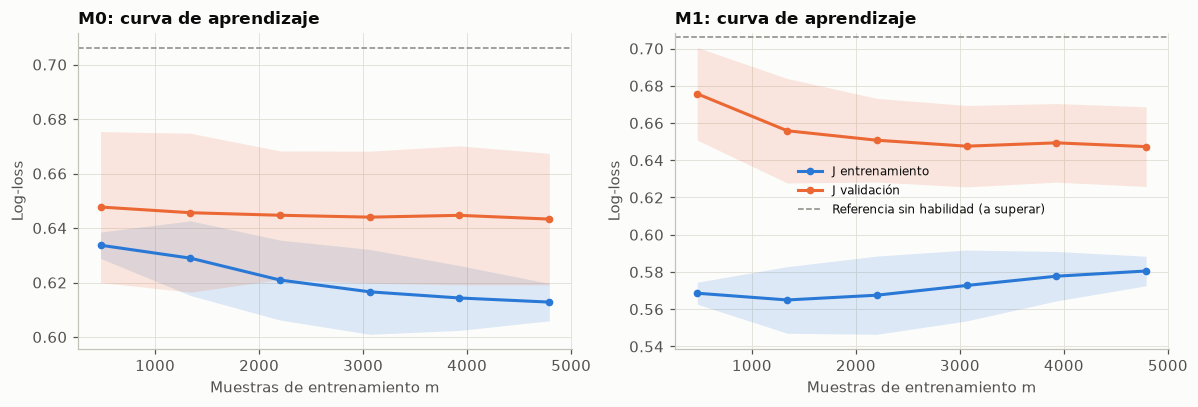

In [27]:
# [Uso de IA] Celda generada con un asistente de IA · sección 6.4 · prompts: P2, P3, P4, P5.
# Instrucción (fase 5): «Metodología de Curva de Aprendizaje: Graficar m (fracciones temporales crecientes
#   del conjunto de entrenamiento: 20%, 40%, 60%, 80%, 100%) en el eje X versus la pérdida (J_train y J_val
#   en Log-Loss y 1 - F_1-macro) en el eje Y, con bandas de ± 1σ.»
# Difiere: se usan seis tamaños (del 10 % al 100 % del entrenamiento más corto entre los últimos cinco
#   pliegues), tomando siempre las m sesiones más recientes, y solo pérdida logarítmica, sin 1 − F1 macro.
from joblib import Parallel, delayed

_, CODIGO_DIA = np.unique(FECHAS_DES, return_inverse=True)            # nº de sesión de cada fila
PLIEGUES_CURVA = list(enumerate(PLIEGUES, start=1))[-5:]
dias_minimos = min(len(np.unique(CODIGO_DIA[e])) for _, (e, _) in PLIEGUES_CURVA)
TAMANOS_DIAS = (np.linspace(0.1, 1.0, 6) * dias_minimos).astype(int)      # sesiones de entrenamiento


def punto_curva(nombre, k, i_ent, i_val, m_dias):
    dias_ent = np.unique(CODIGO_DIA[i_ent])
    sub = i_ent[CODIGO_DIA[i_ent] >= dias_ent[-m_dias]]               # las m sesiones MÁS RECIENTES
    modelo = crear_modelo(nombre, **MEJORES[nombre]).fit(X_des.iloc[sub], y_des[sub])
    return {"modelo": nombre, "pliegue": k, "m": len(sub),
            "J_ent": log_loss(y_des[sub], modelo.predict_proba(X_des.iloc[sub])[:, 1], labels=[0, 1]),
            "J_val": log_loss(y_des[i_val], modelo.predict_proba(X_des.iloc[i_val])[:, 1], labels=[0, 1])}


curvas = pd.DataFrame(Parallel(n_jobs=-1)(
    delayed(punto_curva)(nombre, k, e, v, m)
    for nombre in ["M0", "M1"] for k, (e, v) in PLIEGUES_CURVA for m in TAMANOS_DIAS))
REF_CURVA = SIN_HABILIDAD[[k - 1 for k, _ in PLIEGUES_CURVA]].mean()

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.8))      # ejes Y independientes: las escalas de M0 y M1 difieren
for eje, nombre in zip(ejes, ["M0", "M1"]):
    g = curvas[curvas["modelo"] == nombre].groupby("m")[["J_ent", "J_val"]].agg(["mean", "std"])
    for columna, color, etiqueta in [("J_ent", C_ENT, "J entrenamiento"), ("J_val", C_VAL, "J validación")]:
        eje.plot(g.index, g[(columna, "mean")], color=color, marker="o", markersize=4, label=etiqueta)
        eje.fill_between(g.index, g[(columna, "mean")] - g[(columna, "std")],
                         g[(columna, "mean")] + g[(columna, "std")], color=color, alpha=0.15, linewidth=0)
    eje.axhline(REF_CURVA, color=C_REF, linewidth=1, linestyle="--", label="Referencia sin habilidad (a superar)")
    eje.set_title(f"{nombre}: curva de aprendizaje")
    eje.set_xlabel("Muestras de entrenamiento m")
    eje.set_ylabel("Log-loss")
ejes[1].legend(fontsize=8, loc="center")
plt.tight_layout()
plt.show()

### 6.5 Diagnóstico de sesgo y varianza

El diagnóstico se calcula con los valores de la curva en el mayor tamaño de entrenamiento, usando dos criterios declarados de antemano:

- **Brecha** $\Delta J = J_{\text{val}} - J_{\text{train}}$. Se considera relevante si supera $0.01$ nats.
- **Ventaja** sobre la referencia, $J_{\text{ref}} - J_{\text{val}}$. Se considera que el modelo supera la referencia si es mayor que $0.002$ nats.

La celda aplica esos criterios y redacta el resultado con los números obtenidos.

In [28]:
# [Uso de IA] Celda generada con un asistente de IA · sección 6.5 · prompts: P2, P3, P5.
# Instrucción (fase 5): «Diagnóstico analítico: Alto Sesgo (Underfitting): J_train y J_val convergen rápido
#   a un valor alto cerca del azar (ln(2) ≈ 0.6931) con brecha mínima. […] Alta Varianza (Overfitting):
#   Brecha persistente»
# Difiere: la referencia no es ln(2) sino la pérdida de predecir la tasa base del entrenamiento de cada
#   pliegue.
UMBRAL_BRECHA, UMBRAL_VENTAJA = 0.01, 0.002

lineas, DIAGNOSTICO = [], {}
for nombre in ["M0", "M1"]:
    g = curvas[curvas["modelo"] == nombre].groupby("m")[["J_ent", "J_val"]].mean()
    j_ent, j_val = g["J_ent"].iloc[-1], g["J_val"].iloc[-1]
    brecha, ventaja = j_val - j_ent, REF_CURVA - j_val
    tendencia = g["J_val"].iloc[-1] - g["J_val"].iloc[0]
    supera, hay_brecha = ventaja > UMBRAL_VENTAJA, brecha > UMBRAL_BRECHA
    if supera and not hay_brecha:
        regimen = "ajuste adecuado: supera la referencia con una brecha pequeña"
    elif supera and hay_brecha:
        regimen = ("supera la referencia, pero con varianza: la pérdida de entrenamiento queda claramente por "
                   "debajo de la de validación. Más datos o más regularización reducirían la brecha")
    elif hay_brecha:
        regimen = ("alta varianza: la pérdida de entrenamiento queda claramente por debajo de la de validación y no "
                   "se supera la referencia. Ayudarían más datos o más regularización")
    else:
        regimen = ("alto sesgo: ambas pérdidas quedan juntas y no superan la referencia. "
                   "Más datos no ayudarían; haría falta más capacidad o variables más informativas")
    DIAGNOSTICO[nombre] = dict(J_ent=j_ent, J_val=j_val, brecha=brecha, ventaja=ventaja, regimen=regimen)
    lineas.append(f"- **{nombre}** con m = {g.index[-1]:,}: J_train = {j_ent:.4f}, J_val = {j_val:.4f}, "
                  f"brecha = {brecha:+.4f}, ventaja sobre la referencia ({REF_CURVA:.4f}) = {ventaja:+.4f}. "
                  f"Al pasar de m = {g.index[0]:,} a m = {g.index[-1]:,}, J_val cambia {tendencia:+.4f}. "
                  f"Diagnóstico: {regimen}.")
display(Markdown("\n".join(lineas)))

- **M0** con m = 4,790: J_train = 0.6128, J_val = 0.6433, brecha = +0.0305, ventaja sobre la referencia (0.7063) = +0.0630. Al pasar de m = 475 a m = 4,790, J_val cambia -0.0044. Diagnóstico: supera la referencia, pero con varianza: la pérdida de entrenamiento queda claramente por debajo de la de validación. Más datos o más regularización reducirían la brecha.
- **M1** con m = 4,790: J_train = 0.5805, J_val = 0.6473, brecha = +0.0668, ventaja sobre la referencia (0.7063) = +0.0590. Al pasar de m = 475 a m = 4,790, J_val cambia -0.0284. Diagnóstico: supera la referencia, pero con varianza: la pérdida de entrenamiento queda claramente por debajo de la de validación. Más datos o más regularización reducirían la brecha.

**Qué deja abierto la curva.** La curva de aprendizaje dice si cada modelo, por separado, está limitado por sesgo o por varianza. No dice cuál de los dos es mejor: eso exige evaluarlos sobre los mismos datos y contrastar la diferencia con una prueba de hipótesis. Es la sección 7.

## 7. Comparación estadística de las dos técnicas

### 7.1 Diseño pareado

Ambos modelos, **con sus hiperparámetros optimizados**, se evalúan en los mismos 10 pliegues. Para cada pliegue $k$ se obtiene la diferencia de pérdidas

$$d_k = J^{(M0)}_k - J^{(M1)}_k, \qquad k = 1, \dots, 10$$

Un valor $d_k > 0$ significa que M1 fue mejor en ese pliegue. El diseño es **pareado** porque los dos modelos ven exactamente los mismos datos de entrenamiento y validación: la dificultad propia de cada período afecta a ambos por igual y se cancela en la resta.

**Hipótesis.** $H_0$: las dos técnicas rinden igual (la diferencia tiene centro en 0). $H_1$: rinden distinto. Prueba bilateral con $\alpha = 0.05$.

**Por qué 10 valores.** La prueba exacta de Wilcoxon con $n$ pares tiene $2^n$ asignaciones de signo posibles, así que su p-valor bilateral mínimo es $2/2^n$. Con $n = 5$ es $0.0625$ y nunca podría bajar de $0.05$; con $n = 10$ es $2/1024 \approx 0.002$.

**Límite que se asume.** En validación cronológica expansiva los bloques de entrenamiento se solapan, por lo que los 10 valores no son del todo independientes y el p-valor es aproximado. Es la misma limitación que tiene la validación cruzada repetida que sugiere la rúbrica.

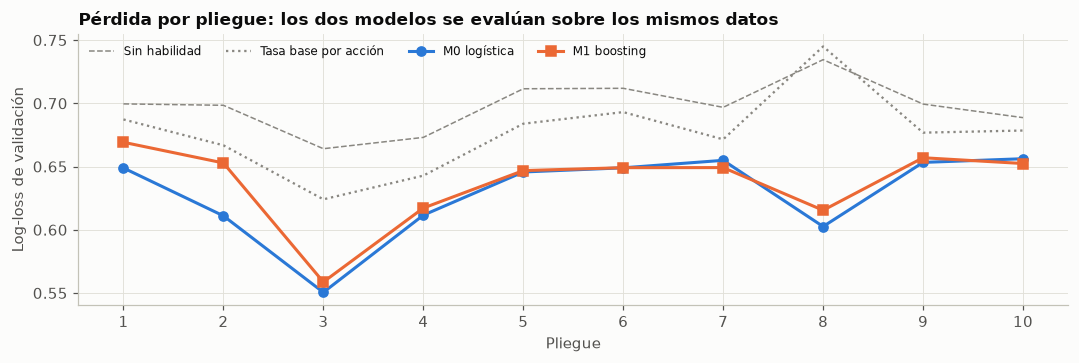

Promedio de las demás métricas en validación:


,log_loss,f1_macro,auc,exactitud
M0,0.6284,0.6229,0.6800,0.6534
M1,0.6368,0.6204,0.6683,0.6432


Exactitud de predecir siempre la clase mayoritaria: 0.4937


,M0,M1,Sin habilidad,Tasa base por acción,Baseline simple,d = M0 - M1
Pliegue,,,,,,
1,0.6489,0.6692,0.6996,0.6873,0.6651,-0.0203
2,0.6110,0.6528,0.6985,0.6668,0.6168,-0.0418
3,0.5505,0.5587,0.6641,0.6241,0.5662,-0.0082
4,0.6116,0.6172,0.6731,0.6428,0.6201,-0.0056
5,0.6457,0.6468,0.7115,0.6839,0.6433,-0.0011
6,0.6490,0.6491,0.7119,0.6931,0.6652,-0.0001
7,0.6549,0.6492,0.6968,0.6715,0.6660,0.0057
8,0.6026,0.6154,0.7345,0.7450,0.6386,-0.0128
9,0.6533,0.6570,0.6994,0.6768,0.6650,-0.0037


In [29]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.1 · prompts: P2, P3, P6.
# Instrucción (fase 6): «Protocolo pareado: Evaluar ambos modelos exactamente en los mismos K = 10 pliegues
#   temporales con semillas idénticas para obtener el vector de diferencias pareadas»
METRICAS_CV = {"log_loss": "neg_log_loss", "f1_macro": "f1_macro", "auc": "roc_auc", "exactitud": "accuracy"}
RESULTADOS_CV = {}
for nombre in ["M0", "M1"]:
    r = cross_validate(crear_modelo(nombre, **MEJORES[nombre]), X_des, y_des, cv=PLIEGUES,
                       scoring=METRICAS_CV, n_jobs=-1)
    RESULTADOS_CV[nombre] = pd.DataFrame({m: (-1 if m == "log_loss" else 1) * r[f"test_{m}"] for m in METRICAS_CV})

PERDIDA = pd.DataFrame({"M0": RESULTADOS_CV["M0"]["log_loss"], "M1": RESULTADOS_CV["M1"]["log_loss"],
                        "Sin habilidad": SIN_HABILIDAD, "Tasa base por acción": REF_ACCION,
                        "Baseline simple": BASELINE_CV})
PERDIDA.index = pd.RangeIndex(1, K_PLIEGUES + 1, name="Pliegue")
PERDIDA["d = M0 - M1"] = PERDIDA["M0"] - PERDIDA["M1"]

fig, eje = plt.subplots(figsize=(10, 3.4))
eje.plot(PERDIDA.index, PERDIDA["Sin habilidad"], color=C_REF, linestyle="--", linewidth=1, label="Sin habilidad")
eje.plot(PERDIDA.index, PERDIDA["Tasa base por acción"], color=C_REF, linestyle=":", linewidth=1.5, label="Tasa base por acción")
eje.plot(PERDIDA.index, PERDIDA["M0"], color=C_ENT, marker="o", label="M0 logística")
eje.plot(PERDIDA.index, PERDIDA["M1"], color=C_VAL, marker="s", label="M1 boosting")
eje.set_xticks(PERDIDA.index)
eje.set_xlabel("Pliegue")
eje.set_ylabel("Log-loss de validación")
eje.set_title("Pérdida por pliegue: los dos modelos se evalúan sobre los mismos datos")
eje.legend(ncol=4, fontsize=8)
plt.tight_layout()
plt.show()

print("Promedio de las demás métricas en validación:")
display(pd.DataFrame({n: RESULTADOS_CV[n].mean() for n in RESULTADOS_CV}).T)
print(f"Exactitud de predecir siempre la clase mayoritaria: {EXACTITUD_BASE.mean():.4f}")
PERDIDA

#### ¿La ventaja sobre las referencias es ruido? Contraste pareado

Antes de comparar los dos modelos entre sí hay que responder una pregunta previa: si su ventaja sobre las referencias podría deberse al azar de la muestra. Se usa el mismo diseño pareado. Para cada modelo y cada referencia se calcula, pliegue a pliegue,

$$g_k = J^{\text{referencia}}_k - J^{\text{modelo}}_k$$

con $H_0$: la ganancia tiene centro en 0. Un valor $g_k > 0$ significa que el modelo fue mejor que la referencia en ese pliegue. Se reportan la $t$ pareada y Wilcoxon, con la misma regla que en la sección 7.2: solo se afirma una ventaja si las dos pruebas rechazan $H_0$. Hay tres puntos de comparación: las dos referencias que no aprenden nada y el *baseline* simple de la sección 6.1, que indica si la optimización y el resto del *pipeline* aportan algo sobre lo más simple. Como son seis contrastes, se indica además si el resultado resiste la corrección de Bonferroni ($\alpha/6 \approx 0.0083$).

In [30]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.1 · prompts: P5, P6.
# Sin instrucción en el documento: contraste pareado de cada modelo contra las referencias (P5) y contra el
#   baseline simple (P6).
from scipy.stats import ttest_rel, wilcoxon

filas = []
for modelo in ["M0", "M1"]:
    for referencia in ["Sin habilidad", "Tasa base por acción", "Baseline simple"]:
        g = (PERDIDA[referencia] - PERDIDA[modelo]).to_numpy()
        p_t_g = ttest_rel(PERDIDA[referencia], PERDIDA[modelo])[1]
        p_w_g = wilcoxon(g, alternative="two-sided", method="exact")[1]
        filas.append({"Modelo": modelo, "Referencia": referencia, "Ganancia media": g.mean(),
                      "Pliegues ganados": int((g > 0).sum()), "t pareada p": p_t_g, "Wilcoxon p": p_w_g,
                      "Ambas rechazan H0": bool(p_t_g < ALFA and p_w_g < ALFA)})
CONTRASTE_REF = pd.DataFrame(filas).set_index(["Modelo", "Referencia"])
CONTRASTE_REF["Resiste Bonferroni"] = CONTRASTE_REF[["t pareada p", "Wilcoxon p"]].max(axis=1) < ALFA / len(CONTRASTE_REF)
display(CONTRASTE_REF)

lineas = []
for (modelo, referencia), f in CONTRASTE_REF.iterrows():
    if f["Ambas rechazan H0"] and f["Ganancia media"] > 0:
        lectura = "La ventaja es estadísticamente significativa" + (" y resiste la corrección de Bonferroni."
                                                                   if f["Resiste Bonferroni"] else ", aunque no resiste la corrección de Bonferroni.")
    elif f["Ambas rechazan H0"]:
        lectura = "El modelo es significativamente peor que este punto de comparación."
    else:
        lectura = "No hay una diferencia demostrable frente a este punto de comparación."
    lineas.append(f"- **{modelo} frente a «{referencia}»:** gana en {f['Pliegues ganados']} de {K_PLIEGUES} pliegues, con una ganancia "
                  f"media de {f['Ganancia media']:+.4f} nats (t pareada: {p_txt(f['t pareada p'])}; Wilcoxon: {p_txt(f['Wilcoxon p'])}). {lectura}")
display(Markdown("\n".join(lineas)))

Ganancia media  Pliegues ganados  t pareada p  \
Modelo Referencia                                                            
M0     Sin habilidad                 0.0694                10       0.0001   
       Tasa base por acción          0.0486                10       0.0025   
       Baseline simple               0.0118                 8       0.0070   
M1     Sin habilidad                 0.0610                10       0.0001   
       Tasa base por acción          0.0402                10       0.0054   
       Baseline simple               0.0034                 7       0.5304   

                             Wilcoxon p  Ambas rechazan H0  Resiste Bonferroni  
Modelo Referencia                                                               
M0     Sin habilidad             0.0020               True                True  
       Tasa base por acción      0.0020               True                True  
       Baseline simple           0.0098               True               False  
M1     Sin habilidad             0.0020               True                True  
       Tasa base por acción      0.0020               True                True  
       Baseline simple           0.3223              False               False

- **M0 frente a «Sin habilidad»:** gana en 10 de 10 pliegues, con una ganancia media de +0.0694 nats (t pareada: p < 0.0001; Wilcoxon: p = 0.0020). La ventaja es estadísticamente significativa y resiste la corrección de Bonferroni.
- **M0 frente a «Tasa base por acción»:** gana en 10 de 10 pliegues, con una ganancia media de +0.0486 nats (t pareada: p = 0.0025; Wilcoxon: p = 0.0020). La ventaja es estadísticamente significativa y resiste la corrección de Bonferroni.
- **M0 frente a «Baseline simple»:** gana en 8 de 10 pliegues, con una ganancia media de +0.0118 nats (t pareada: p = 0.0070; Wilcoxon: p = 0.0098). La ventaja es estadísticamente significativa, aunque no resiste la corrección de Bonferroni.
- **M1 frente a «Sin habilidad»:** gana en 10 de 10 pliegues, con una ganancia media de +0.0610 nats (t pareada: p < 0.0001; Wilcoxon: p = 0.0020). La ventaja es estadísticamente significativa y resiste la corrección de Bonferroni.
- **M1 frente a «Tasa base por acción»:** gana en 10 de 10 pliegues, con una ganancia media de +0.0402 nats (t pareada: p = 0.0054; Wilcoxon: p = 0.0020). La ventaja es estadísticamente significativa y resiste la corrección de Bonferroni.
- **M1 frente a «Baseline simple»:** gana en 7 de 10 pliegues, con una ganancia media de +0.0034 nats (t pareada: p = 0.5304; Wilcoxon: p = 0.3223). No hay una diferencia demostrable frente a este punto de comparación.

### 7.2 Prueba de hipótesis

Con solo 10 diferencias, la elección de la prueba depende de si $d_k$ puede tratarse como normal:

1. **Shapiro-Wilk** [23] sobre $d_k$. $H_0$: las diferencias provienen de una distribución normal.
2. Si no se rechaza la normalidad ($p > 0.05$), la prueba más apropiada es la **$t$ de Student pareada**, $t = \dfrac{\bar d}{s_d/\sqrt{K}}$ con $K - 1$ grados de libertad, que tiene más potencia.
3. Si se rechaza, la prueba más apropiada es **Wilcoxon de rangos con signo** [24], que solo usa el orden de $|d_k|$ y su signo, y no supone normalidad.

**Las dos pruebas se leen juntas.** Con $n = 10$, Shapiro-Wilk tiene poca potencia: no rechazar la normalidad no la demuestra, y un p-valor cercano a $0.05$ no permite decidir con seguridad entre una prueba y otra. Por eso el árbol anterior solo indica cuál es la más apropiada; las dos se calculan con SciPy [25] y se reportan siempre, como análisis de robustez. La regla de decisión es conservadora y se fija antes de ver el resultado: **se afirma que hay diferencia solo si las dos pruebas rechazan $H_0$**. Si coinciden, la conclusión no depende del supuesto de normalidad; si discrepan, el resultado se declara no concluyente.

**Tamaño del efecto.** Un p-valor no dice cuánto mejor es un modelo. Se añaden la $d$ de Cohen pareada, $\bar d / s_d$, y la correlación biserial por rangos, $r_{rb} = (W^+ - W^-)/(W^+ + W^-)$, que va de $-1$ a $1$.

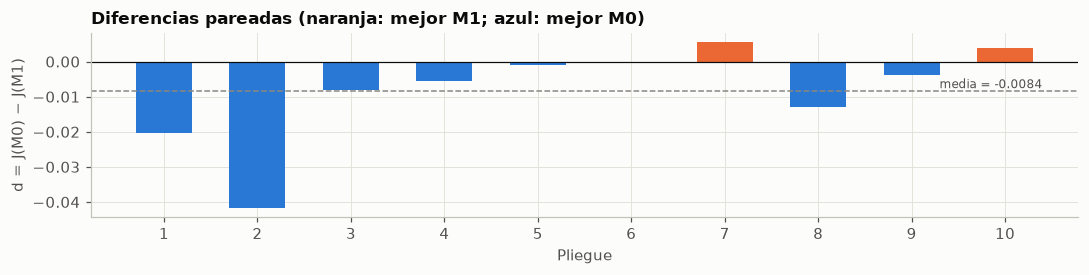

,Valor
Media de d,-0.0084
Desviación estándar de d,0.0141
Pliegues donde gana M1,2.0000
Shapiro-Wilk p,0.0586
t pareada: estadístico,-1.8930
t pareada: p,0.0909
Wilcoxon: estadístico W,10.0000
Wilcoxon: p (exacto),0.0840
d de Cohen (pareada),-0.5986
Correlación biserial por rangos,-0.6364


In [31]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.2 · prompts: P2, P4, P5.
# Instrucción (fase 6): «Árbol de decisión estadística: Test de Shapiro-Wilk sobre d_k para verificar
#   normalidad. Si no es normal: Test de Rangos con Signo de Wilcoxon (`scipy.stats.wilcoxon`). Si es
#   normal: Test t-Student pareado.»
# Difiere: se calculan siempre las dos pruebas y solo se afirma diferencia si ambas rechazan, en lugar de
#   elegir una sola según Shapiro-Wilk.
from scipy.stats import rankdata, shapiro, ttest_rel, wilcoxon

d = PERDIDA["d = M0 - M1"].to_numpy()
_, p_shapiro = shapiro(d)
t_est, p_t = ttest_rel(PERDIDA["M0"], PERDIDA["M1"])
w_est, p_w = wilcoxon(d, alternative="two-sided", method="exact")
d_cohen = d.mean() / d.std(ddof=1)
rangos = rankdata(np.abs(d))
r_rb = (rangos[d > 0].sum() - rangos[d < 0].sum()) / rangos.sum()

normal = p_shapiro > ALFA
COINCIDEN = (p_t < ALFA) == (p_w < ALFA)                 # ¿las dos pruebas llegan a la misma decisión?
SIGNIFICATIVO = bool(p_t < ALFA and p_w < ALFA)          # solo se afirma diferencia si las dos la respaldan
GANADOR = "M1" if d.mean() > 0 else "M0"

fig, eje = plt.subplots(figsize=(10, 2.6))
eje.bar(PERDIDA.index, d, color=[C_VAL if v > 0 else C_ENT for v in d], width=0.6)
eje.axhline(0, color="#0b0b0b", linewidth=0.8)
eje.axhline(d.mean(), color=C_REF, linewidth=1, linestyle="--")
eje.annotate(f"media = {d.mean():+.4f}", (K_PLIEGUES + 0.4, d.mean()), fontsize=8, color="#52514e", va="bottom", ha="right")
eje.set_xticks(PERDIDA.index)
eje.set_xlabel("Pliegue")
eje.set_ylabel("d = J(M0) − J(M1)")
eje.set_title("Diferencias pareadas (naranja: mejor M1; azul: mejor M0)")
plt.tight_layout()
plt.show()

pd.DataFrame({
    "Valor": [d.mean(), d.std(ddof=1), int((d > 0).sum()), p_shapiro, t_est, p_t, w_est, p_w, d_cohen, r_rb],
}, index=["Media de d", "Desviación estándar de d", "Pliegues donde gana M1", "Shapiro-Wilk p",
          "t pareada: estadístico", "t pareada: p", "Wilcoxon: estadístico W", "Wilcoxon: p (exacto)",
          "d de Cohen (pareada)", "Correlación biserial por rangos"])

### 7.3 Conclusión de la comparación

La celda redacta la conclusión con los valores calculados, presentando las dos pruebas juntas. No se afirma superioridad a menos que ambas rechacen $H_0$.

In [32]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.3 · prompts: P2, P3, P4, P6.
# Instrucción (fase 6): «Reportar p-valor formal y tamaño del efecto (d de Cohen o correlación biserial
#   r_rb).»
limitrofe = 0.01 < p_shapiro < 0.10
texto = [
    f"- **Normalidad de las diferencias.** Shapiro-Wilk: p = {p_shapiro:.3f}. " +
    ("No se rechaza la normalidad" if normal else "Se rechaza la normalidad") +
    (", pero el valor está cerca del umbral de 0.05 y con solo 10 diferencias la prueba tiene poca potencia: la elección entre "
     "la prueba paramétrica y la no paramétrica no es nítida, así que las dos se leen juntas."
     if limitrofe else
     ". Aun así, con solo 10 diferencias las dos pruebas se leen juntas."),
    f"- **Las dos pruebas.** t de Student pareada: p = {p_t:.4f}. Wilcoxon de rangos con signo: p = {p_w:.4f}. " +
    (f"Las dos coinciden en {'rechazar' if p_t < ALFA else 'no rechazar'} H0 con α = {ALFA}: la conclusión no depende del supuesto "
     "de normalidad." if COINCIDEN else
     f"Las dos pruebas no coinciden respecto a α = {ALFA}: el resultado depende del supuesto de normalidad y se declara no concluyente."),
]
if SIGNIFICATIVO:
    texto.append(f"- **Se rechaza H0**: la diferencia de rendimiento es estadísticamente significativa a favor de **{GANADOR}**, que "
                 f"gana en {int((d > 0).sum()) if GANADOR == 'M1' else int((d < 0).sum())} de {K_PLIEGUES} pliegues.")
else:
    texto.append(f"- **No se rechaza H0**: no hay evidencia de que una técnica rinda distinto de la otra. {GANADOR} tiene menor "
                 f"pérdida media y gana en {int((d > 0).sum()) if GANADOR == 'M1' else int((d < 0).sum())} de {K_PLIEGUES} pliegues, "
                 f"pero esa ventaja ({abs(d.mean()):.4f} nats) es compatible con el azar.")
texto.append(f"- Tamaño del efecto: d de Cohen = {d_cohen:+.2f}, correlación biserial = {r_rb:+.2f}.")
texto.append(f"- Frente a la referencia sin habilidad ({SIN_HABILIDAD.mean():.4f}) y a la tasa base por acción ({REF_ACCION.mean():.4f}): "
             f"M0 = {PERDIDA['M0'].mean():.4f}, M1 = {PERDIDA['M1'].mean():.4f}; baseline simple = {BASELINE_CV.mean():.4f}.")
MODELO_ELEGIDO = GANADOR if SIGNIFICATIVO else "M0"
texto.append(f"- **Modelo elegido: {MODELO_ELEGIDO}.** " +
             ("Se adopta el ganador de la comparación." if SIGNIFICATIVO else
              "Sin diferencia significativa se prefiere el modelo más simple e interpretable (navaja de Occam)."))
display(Markdown("\n".join(texto)))

- **Normalidad de las diferencias.** Shapiro-Wilk: p = 0.059. No se rechaza la normalidad, pero el valor está cerca del umbral de 0.05 y con solo 10 diferencias la prueba tiene poca potencia: la elección entre la prueba paramétrica y la no paramétrica no es nítida, así que las dos se leen juntas.
- **Las dos pruebas.** t de Student pareada: p = 0.0909. Wilcoxon de rangos con signo: p = 0.0840. Las dos coinciden en no rechazar H0 con α = 0.05: la conclusión no depende del supuesto de normalidad.
- **No se rechaza H0**: no hay evidencia de que una técnica rinda distinto de la otra. M0 tiene menor pérdida media y gana en 8 de 10 pliegues, pero esa ventaja (0.0084 nats) es compatible con el azar.
- Tamaño del efecto: d de Cohen = -0.60, correlación biserial = -0.64.
- Frente a la referencia sin habilidad (0.6978) y a la tasa base por acción (0.6770): M0 = 0.6284, M1 = 0.6368; baseline simple = 0.6402.
- **Modelo elegido: M0.** Sin diferencia significativa se prefiere el modelo más simple e interpretable (navaja de Occam).

### 7.4 Evaluación única en el conjunto de prueba

Hasta aquí, 2022–2023 no se ha usado para nada. Ahora cada modelo se reentrena una vez con todo el desarrollo (menos las últimas 5 sesiones, por la brecha) y predice el período de prueba. **Ningún hiperparámetro ni decisión de modelado se ajusta después de ver este resultado.** El historial completo de ejecuciones está declarado en las limitaciones de la sección 9.

Se presentan las métricas que pide la rúbrica para clasificación, con umbral de decisión $0.5$:

| Métrica | Fórmula | Qué mide |
|---|---|---|
| Exactitud | $(VP + VN)/m$ | Aciertos totales. Se compara con la de predecir siempre la clase mayoritaria (fila «Sin habilidad»). |
| Precisión | $VP/(VP + FP)$ | De las alertas emitidas, cuántas correspondieron a un día de movimiento grande. |
| Sensibilidad (*recall*) | $VP/(VP + FN)$ | De los días de movimiento grande, cuántos se anticiparon. Es la que protege frente a sorpresas. |
| F1 macro / ponderado | Media de $F_1$ por clase, simple o ponderada por frecuencia | Equilibrio entre precisión y sensibilidad. |
| AUC-ROC | Área bajo la curva ROC | Probabilidad de ordenar un positivo por encima de un negativo; $0.5$ equivale al azar. |
| AUC macro | Media del AUC de cada clase frente a la otra | En un problema binario coincide con el AUC: los dos valores son iguales. |
| AUC micro | AUC de las dos columnas *one-hot* agrupadas: $(y, \hat p)$ y $(1-y, 1-\hat p)$ | No coincide con el AUC: al mezclar las dos columnas depende también de la calibración. |
| MCC | Correlación entre predicción y realidad | Usa las cuatro celdas de la matriz de confusión. |
| Brier y *log-loss* | Error cuadrático y entropía cruzada de $\hat p$ | Calidad de la probabilidad. |

La rúbrica pide los promedios macro y micro del AUC. En un problema binario el macro coincide con el AUC; el micro no, y por eso la tabla reporta los tres.

**Las filas de referencia.** Además de los dos modelos, la tabla incluye el *baseline* simple y tres predictores que no aprenden nada, para que cada métrica tenga con qué compararse:

| Fila | Qué predice | Con qué información |
|---|---|---|
| Baseline simple | Regresión logística por defecto sobre las variables de precio y volumen estandarizadas (sección 6.1). | Solo el pasado |
| Sin habilidad | La misma probabilidad para todas las observaciones: la tasa base global del desarrollo. | Solo el pasado |
| Tasa base por acción | Para cada acción, su propia frecuencia de días agitados en el desarrollo. Con umbral $0.5$ solo emite alerta para las acciones cuya tasa histórica supera $0.5$. | Solo el pasado |
| Tasa base de la prueba (a posteriori) | La proporción real de días agitados del período de prueba, igual para todas las observaciones. | El futuro |

Las tres primeras son alternativas reales: se podían calcular antes de la prueba, igual que el modelo. La última no, porque usa la etiqueta del período que se evalúa; se incluye como cota exigente, y su exactitud es la de predecir siempre la clase mayoritaria de la propia prueba.

Si la proporción de días agitados cambia entre el desarrollo y la prueba, las referencias del pasado quedan descalibradas y su exactitud puede caer por debajo del 50 %; la del futuro no. Por eso la comparación justa del modelo es contra las tres primeras. La última responde otra pregunta: cuánto de la exactitud del modelo se explicaría solo por conocer la tasa base correcta. Las métricas que no dependen del umbral ni de la tasa base, como el AUC, son las que mejor resumen la capacidad de ordenar.

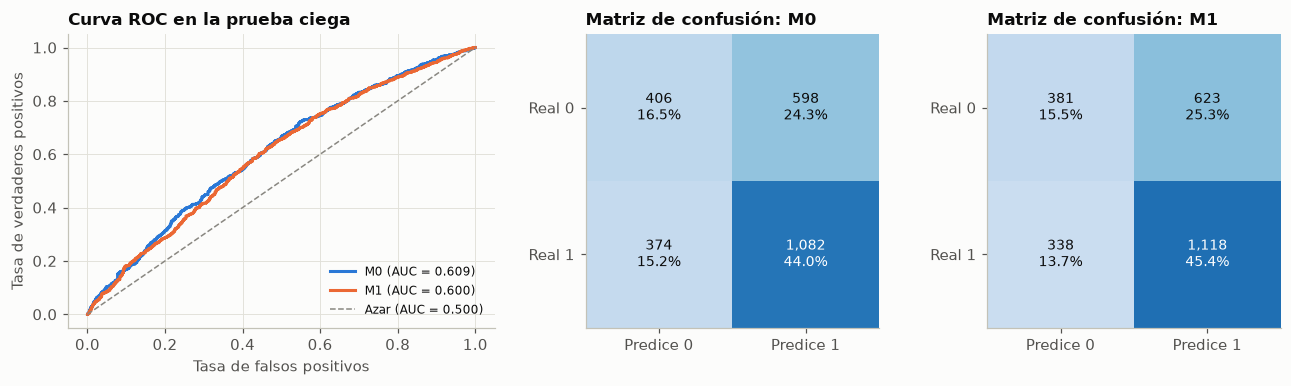

Prueba ciega: 2022-01-03 a 2023-12-15 | m = 2,460 | P(y = 1) = 0.5919
Tasa base global del desarrollo: 0.478 -> «Sin habilidad» predice siempre la clase 0
Tasa de cada acción en desarrollo: ADBE 0.45, CRM 0.47, MU 0.67, ORCL 0.34, TXN 0.46 -> «Tasa base por acción» solo emite alerta donde supera 0.50
Clase mayoritaria de la propia prueba (solo se conoce después): exactitud 0.5919


,Log-loss,Brier,AUC-ROC,AUC macro,AUC micro,PR-AUC,Exactitud,Precisión,Sensibilidad,F1 macro,F1 ponderado,MCC,Predice positivo
M0,0.6659,0.2362,0.6088,0.6088,0.6427,0.6772,0.6049,0.6440,0.7431,0.5726,0.5942,0.1558,0.6829
M1,0.6674,0.2370,0.5999,0.5999,0.6381,0.6670,0.6093,0.6422,0.7679,0.5708,0.5945,0.1592,0.7077
Tasa base por acción,0.7103,0.2583,0.5444,0.5444,0.5080,0.6174,0.4602,0.6301,0.2129,0.4357,0.4141,0.0389,0.2000
Baseline simple,0.6665,0.2367,0.6096,0.6096,0.6364,0.6800,0.5980,0.6504,0.6937,0.5769,0.5942,0.1557,0.6313
Sin habilidad,0.7023,0.2546,0.5000,0.5000,0.4081,0.5919,0.4081,0.0000,0.0000,0.2898,0.2366,0.0000,0.0000
Tasa base de la prueba (a posteriori),0.6762,0.2416,0.5000,0.5000,0.5919,0.5919,0.5919,0.5919,1.0000,0.3718,0.4401,0.0000,1.0000


In [33]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.4 · prompts: P2, P3, P4, P5, P6.
# Instrucción (fases 1 y 3): «Métricas técnicas de validación: Precision de la clase positiva (mitigación de
#   compras falsas que destruyen capital), Macro-F_1, MCC, PR-AUC, Brier Score. (Prohibido usar Accuracy
#   simple como criterio rector).»
#   «Aislamiento del Hold-out Test: […] aislado como conjunto ciego de prueba final.»
# Difiere: la prueba ciega es 2022–2023 (decisión de datos).
from sklearn.metrics import (accuracy_score, average_precision_score, brier_score_loss, confusion_matrix,
                             f1_score, matthews_corrcoef, precision_score, recall_score, roc_auc_score, roc_curve)

dias_des = np.unique(FECHAS_DES)
i_final = np.flatnonzero(FECHAS_DES <= dias_des[-(BRECHA + 1)])     # purga las últimas 5 sesiones
FINALES = {n: crear_modelo(n, **MEJORES[n]).fit(X_des.iloc[i_final], y_des[i_final]) for n in ["M0", "M1"]}
PROB = {n: m.predict_proba(X_pru)[:, 1] for n, m in FINALES.items()}
PROB["Tasa base por acción"] = prob_por_accion(TICKER_DES[i_final], y_des[i_final], prueba["ticker"].to_numpy())
PROB["Baseline simple"] = crear_baseline().fit(X_des.iloc[i_final], y_des[i_final]).predict_proba(X_pru)[:, 1]
PROB["Sin habilidad"] = np.full(len(y_pru), y_des[i_final].mean())
# Cota que usa el futuro: la tasa base real del período de prueba. No es una alternativa operable.
PROB["Tasa base de la prueba (a posteriori)"] = np.full(len(y_pru), y_pru.mean())


def metricas(y, p, umbral=0.5):
    h = (p >= umbral).astype(int)
    return {"Log-loss": log_loss(y, p, labels=[0, 1]), "Brier": brier_score_loss(y, p),
            "AUC-ROC": roc_auc_score(y, p),
            "AUC macro": (roc_auc_score(y, p) + roc_auc_score(1 - y, 1 - p)) / 2,      # media del AUC de cada clase
            "AUC micro": roc_auc_score(np.r_[y, 1 - y], np.r_[p, 1 - p]),             # las dos columnas one-hot agrupadas
            "PR-AUC": average_precision_score(y, p),
            "Exactitud": accuracy_score(y, h), "Precisión": precision_score(y, h, zero_division=0),
            "Sensibilidad": recall_score(y, h, zero_division=0),
            "F1 macro": f1_score(y, h, average="macro", zero_division=0),
            "F1 ponderado": f1_score(y, h, average="weighted", zero_division=0),
            "MCC": matthews_corrcoef(y, h), "Predice positivo": h.mean()}


TABLA_PRUEBA = pd.DataFrame({n: metricas(y_pru, p) for n, p in PROB.items()}).T

fig, ejes = plt.subplots(1, 3, figsize=(12, 3.6), gridspec_kw={"width_ratios": [1.3, 1, 1]})
for nombre, color in [("M0", C_ENT), ("M1", C_VAL)]:
    fpr, tpr, _ = roc_curve(y_pru, PROB[nombre])
    ejes[0].plot(fpr, tpr, color=color, label=f"{nombre} (AUC = {TABLA_PRUEBA.loc[nombre, 'AUC-ROC']:.3f})")
ejes[0].plot([0, 1], [0, 1], color=C_REF, linestyle="--", linewidth=1, label="Azar (AUC = 0.500)")
ejes[0].set_xlabel("Tasa de falsos positivos")
ejes[0].set_ylabel("Tasa de verdaderos positivos")
ejes[0].set_title("Curva ROC en la prueba ciega")
ejes[0].legend(fontsize=8, loc="lower right")
for eje, nombre in zip(ejes[1:], ["M0", "M1"]):
    mc = confusion_matrix(y_pru, (PROB[nombre] >= 0.5).astype(int), labels=[0, 1])
    eje.imshow(mc, cmap="Blues", vmin=0, vmax=mc.sum() * 0.6)
    for (i, j), valor in np.ndenumerate(mc):
        eje.text(j, i, f"{valor:,}\n{valor / mc.sum():.1%}", ha="center", va="center", fontsize=9,
                 color="#ffffff" if valor > mc.sum() * 0.35 else "#0b0b0b")
    eje.set_xticks([0, 1])
    eje.set_yticks([0, 1])
    eje.set_xticklabels(["Predice 0", "Predice 1"])
    eje.set_yticklabels(["Real 0", "Real 1"])
    eje.set_title(f"Matriz de confusión: {nombre}")
    eje.grid(False)
plt.tight_layout()
plt.show()

print(f"Prueba ciega: {prueba['fecha'].min().date()} a {prueba['fecha'].max().date()} | m = {len(y_pru):,} | "
      f"P(y = 1) = {y_pru.mean():.4f}")
EXACTITUD_MAYORIA_PRUEBA = max(y_pru.mean(), 1 - y_pru.mean())
tasas_des = pd.Series(y_des[i_final]).groupby(TICKER_DES[i_final]).mean()
print(f"Tasa base global del desarrollo: {y_des[i_final].mean():.3f} -> «Sin habilidad» predice siempre la clase "
      f"{int(y_des[i_final].mean() > 0.5)}")
print("Tasa de cada acción en desarrollo: " + ", ".join(f"{t} {v:.2f}" for t, v in tasas_des.items()) +
      " -> «Tasa base por acción» solo emite alerta donde supera 0.50")
print(f"Clase mayoritaria de la propia prueba (solo se conoce después): exactitud {EXACTITUD_MAYORIA_PRUEBA:.4f}")
TABLA_PRUEBA

#### Incertidumbre de las métricas de prueba: remuestreo por bloques

Una sola cifra de AUC o de *log-loss* no dice cuánto podría cambiar con otra muestra del mismo período. Se estima con un **bootstrap por bloques**:

- La unidad que se remuestrea es la **sesión**, no la fila: las cinco acciones de un mismo día comparten el movimiento del mercado y no son observaciones independientes.
- Las sesiones se toman en **bloques consecutivos de 21** (un mes bursátil), porque la volatilidad persiste de un día al siguiente. Remuestrear días sueltos rompería esa dependencia y daría intervalos demasiado estrechos.
- Se generan 2 000 réplicas. El intervalo de 95 % va del percentil 2.5 al 97.5.

Se calcula para el AUC de cada modelo y para la ganancia de *log-loss* frente a cada referencia, $J^{\text{referencia}} - J^{\text{modelo}}$. Si el intervalo del AUC excluye $0.5$, o el de la ganancia excluye $0$, la ventaja no se explica por el azar del muestreo. El procedimiento no reajusta ningún modelo: solo vuelve a evaluar las predicciones ya hechas.

In [34]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.4 · prompt: P5.
# Sin instrucción en el documento: intervalos por remuestreo de bloques, añadidos con P5.
LARGO_BLOQUE, REPLICAS = 21, 2000
rng = np.random.default_rng(SEMILLA)
fechas_pru, codigo_pru = np.unique(prueba["fecha"].to_numpy(), return_inverse=True)
filas_por_sesion = [np.flatnonzero(codigo_pru == i) for i in range(len(fechas_pru))]
n_sesiones = len(fechas_pru)
n_bloques = int(np.ceil(n_sesiones / LARGO_BLOQUE))

# Pérdida de cada observación con cada predictor: basta promediarla sobre las filas remuestreadas.
PERDIDA_OBS = {n: -(y_pru * np.log(np.clip(p, 1e-12, 1)) + (1 - y_pru) * np.log(np.clip(1 - p, 1e-12, 1))) for n, p in PROB.items()}
REFERENCIAS_PRUEBA = ["Sin habilidad", "Tasa base por acción", "Tasa base de la prueba (a posteriori)"]


def estadisticos(idx):
    fila = {}
    for modelo in ["M0", "M1"]:
        fila[f"AUC {modelo}"] = roc_auc_score(y_pru[idx], PROB[modelo][idx])
        for referencia in REFERENCIAS_PRUEBA:
            fila[f"Ganancia de {modelo} sobre «{referencia}»"] = PERDIDA_OBS[referencia][idx].mean() - PERDIDA_OBS[modelo][idx].mean()
    return fila


replicas = []
for _ in range(REPLICAS):
    inicios = rng.integers(0, n_sesiones, n_bloques)
    sesiones = ((inicios[:, None] + np.arange(LARGO_BLOQUE)[None, :]).ravel() % n_sesiones)[:n_sesiones]   # bloques circulares
    replicas.append(estadisticos(np.concatenate([filas_por_sesion[s] for s in sesiones])))
replicas = pd.DataFrame(replicas)

IC_PRUEBA = pd.DataFrame({"Valor observado": pd.Series(estadisticos(np.arange(len(y_pru)))),
                          "2.5 %": replicas.quantile(0.025), "97.5 %": replicas.quantile(0.975)})
nulo = pd.Series({nombre: 0.5 if nombre.startswith("AUC") else 0.0 for nombre in IC_PRUEBA.index})
IC_PRUEBA["Excluye el valor nulo"] = (IC_PRUEBA["2.5 %"] > nulo) | (IC_PRUEBA["97.5 %"] < nulo)
display(IC_PRUEBA)

ic_auc = IC_PRUEBA.loc[f"AUC {MODELO_ELEGIDO}"]
ic_sh = IC_PRUEBA.loc[f"Ganancia de {MODELO_ELEGIDO} sobre «Sin habilidad»"]
ic_ac = IC_PRUEBA.loc[f"Ganancia de {MODELO_ELEGIDO} sobre «Tasa base por acción»"]
ic_post = IC_PRUEBA.loc[f"Ganancia de {MODELO_ELEGIDO} sobre «Tasa base de la prueba (a posteriori)»"]
display(Markdown("\n".join([
    f"- **AUC de {MODELO_ELEGIDO}:** {ic_auc['Valor observado']:.3f}, intervalo de 95 % [{ic_auc['2.5 %']:.3f}, {ic_auc['97.5 %']:.3f}]. " +
    ("El intervalo excluye 0.5: la capacidad de ordenar los días no se explica por el azar del muestreo."
     if ic_auc["Excluye el valor nulo"] else "El intervalo incluye 0.5: no se puede descartar que el AUC sea fruto del azar."),
    f"- **Ganancia de log-loss frente a las referencias calculadas con el pasado:** {ic_sh['Valor observado']:.4f} "
    f"[{ic_sh['2.5 %']:.4f}, {ic_sh['97.5 %']:.4f}] sobre «Sin habilidad» y {ic_ac['Valor observado']:.4f} "
    f"[{ic_ac['2.5 %']:.4f}, {ic_ac['97.5 %']:.4f}] sobre «Tasa base por acción». " +
    ("Los dos intervalos excluyen 0." if ic_sh["Excluye el valor nulo"] and ic_ac["Excluye el valor nulo"] else
     "Al menos uno de los intervalos incluye 0, de modo que esa ventaja no queda demostrada."),
    f"- **Frente a la tasa base de la propia prueba, que usa el futuro:** {ic_post['Valor observado']:.4f} "
    f"[{ic_post['2.5 %']:.4f}, {ic_post['97.5 %']:.4f}]. " +
    ("El intervalo excluye 0: el modelo aporta algo más que conocer la tasa base correcta."
     if ic_post["Excluye el valor nulo"] else
     "El intervalo incluye 0: frente a quien conociera de antemano la tasa base del período, la ventaja del modelo no queda demostrada."),
])))

,Valor observado,2.5 %,97.5 %,Excluye el valor nulo
AUC M0,0.6088,0.5783,0.6350,True
Ganancia de M0 sobre «Sin habilidad»,0.0364,0.0141,0.0606,True
Ganancia de M0 sobre «Tasa base por acción»,0.0444,0.0229,0.0687,True
Ganancia de M0 sobre «Tasa base de la prueba (a posteriori)»,0.0103,-0.0035,0.0244,False
AUC M1,0.5999,0.5665,0.6273,True
Ganancia de M1 sobre «Sin habilidad»,0.0350,0.0131,0.0595,True
Ganancia de M1 sobre «Tasa base por acción»,0.0430,0.0207,0.0673,True
Ganancia de M1 sobre «Tasa base de la prueba (a posteriori)»,0.0088,-0.0047,0.0223,False


- **AUC de M0:** 0.609, intervalo de 95 % [0.578, 0.635]. El intervalo excluye 0.5: la capacidad de ordenar los días no se explica por el azar del muestreo.
- **Ganancia de log-loss frente a las referencias calculadas con el pasado:** 0.0364 [0.0141, 0.0606] sobre «Sin habilidad» y 0.0444 [0.0229, 0.0687] sobre «Tasa base por acción». Los dos intervalos excluyen 0.
- **Frente a la tasa base de la propia prueba, que usa el futuro:** 0.0103 [-0.0035, 0.0244]. El intervalo incluye 0: frente a quien conociera de antemano la tasa base del período, la ventaja del modelo no queda demostrada.

#### Calibración de las probabilidades

El *log-loss* premia que las probabilidades sean correctas, no solo que ordenen bien. Un modelo está **calibrado** si, entre los días a los que asigna una probabilidad cercana a $q$, la fracción que resulta agitada es cercana a $q$. Se comprueba con un diagrama de fiabilidad: se agrupan las predicciones en 10 tramos con igual número de observaciones y se compara, en cada uno, la probabilidad media predicha con la frecuencia observada. Un modelo perfecto cae sobre la diagonal.

Importa aquí por un motivo concreto: la proporción de días agitados cambió entre el desarrollo y la prueba. Un modelo puede ordenar bien los días y aun así quedarse corto o pasarse en el nivel de sus probabilidades. Se resume con el error de calibración esperado, $\mathrm{ECE} = \frac{1}{B}\sum_b \lvert \bar y_b - \bar p_b \rvert$.

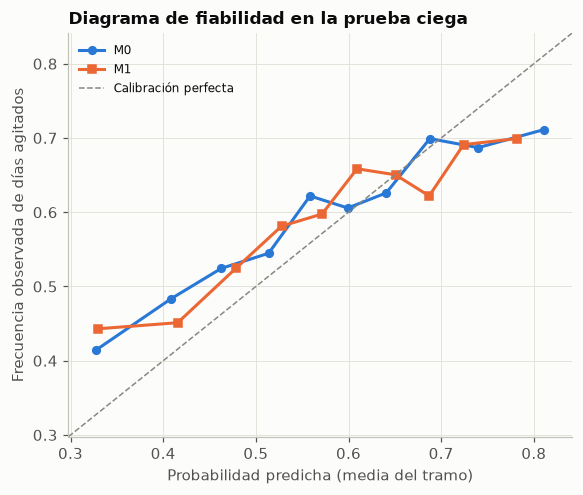

,Probabilidad media predicha,Frecuencia observada,ECE
M0,0.5750,0.5919,0.0503
M1,0.5777,0.5919,0.0505


- **Nivel medio.** M0 predice en promedio 0.575 y la frecuencia observada de días agitados fue 0.592 (diferencia -0.017). En desarrollo esa proporción era 0.477. El nivel de las predicciones siguió casi por completo el cambio de régimen, porque las variables de volatilidad reciente lo reflejan.
- **Extremos.** En el tramo más bajo el modelo predice 0.33 y se observa 0.41; en el más alto predice 0.81 y se observa 0.71. Las probabilidades son más extremas que la realidad: el modelo ordena bien los días, pero exagera su seguridad, y el log-loss penaliza esa exageración.
- **Error de calibración esperado:** 0.050. No se recalibra, porque hacerlo con los datos de prueba sería ajustar con el futuro.

In [35]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.4 · prompt: P6.
# Sin instrucción en el documento: diagrama de calibración, añadido con P6.
from sklearn.calibration import calibration_curve

fig, eje = plt.subplots(figsize=(5.4, 4.6))
filas, tramos, extremos = {}, {}, []
for nombre, color, marcador in [("M0", C_ENT, "o"), ("M1", C_VAL, "s")]:
    observada, predicha = calibration_curve(y_pru, PROB[nombre], n_bins=10, strategy="quantile")
    tramos[nombre] = (predicha, observada)
    eje.plot(predicha, observada, color=color, marker=marcador, markersize=5, label=nombre)
    extremos += [predicha.min(), predicha.max(), observada.min(), observada.max()]
    filas[nombre] = {"Probabilidad media predicha": PROB[nombre].mean(), "Frecuencia observada": y_pru.mean(),
                     "ECE": np.abs(observada - predicha).mean()}
lim = [min(extremos) - 0.03, max(extremos) + 0.03]
eje.plot(lim, lim, color=C_REF, linestyle="--", linewidth=1, label="Calibración perfecta")
eje.set_xlim(lim)
eje.set_ylim(lim)
eje.set_xlabel("Probabilidad predicha (media del tramo)")
eje.set_ylabel("Frecuencia observada de días agitados")
eje.set_title("Diagrama de fiabilidad en la prueba ciega")
eje.legend(fontsize=8)
plt.tight_layout()
plt.show()

CALIBRACION = pd.DataFrame(filas).T
display(CALIBRACION)
c = CALIBRACION.loc[MODELO_ELEGIDO]
predicha, observada = tramos[MODELO_ELEGIDO]
sesgo = c["Probabilidad media predicha"] - c["Frecuencia observada"]
exagera = (observada[-1] - observada[0]) < 0.8 * (predicha[-1] - predicha[0])
display(Markdown("\n".join([
    f"- **Nivel medio.** {MODELO_ELEGIDO} predice en promedio {c['Probabilidad media predicha']:.3f} y la frecuencia observada de días "
    f"agitados fue {c['Frecuencia observada']:.3f} (diferencia {sesgo:+.3f}). En desarrollo esa proporción era {y_des.mean():.3f}. " +
    ("El nivel de las predicciones siguió casi por completo el cambio de régimen, porque las variables de volatilidad reciente lo reflejan."
     if abs(sesgo) <= 0.03 else
     "El nivel de las predicciones no siguió del todo el cambio de régimen entre el desarrollo y la prueba."),
    f"- **Extremos.** En el tramo más bajo el modelo predice {predicha[0]:.2f} y se observa {observada[0]:.2f}; en el más alto predice "
    f"{predicha[-1]:.2f} y se observa {observada[-1]:.2f}. " +
    ("Las probabilidades son más extremas que la realidad: el modelo ordena bien los días, pero exagera su seguridad, y el log-loss "
     "penaliza esa exageración." if exagera else "Los extremos están razonablemente calibrados."),
    f"- **Error de calibración esperado:** {c['ECE']:.3f}. No se recalibra, porque hacerlo con los datos de prueba sería ajustar con el futuro.",
])))

### 7.5 Evaluación económica: gestión de riesgo

Una probabilidad solo tiene valor si mejora una decisión. Como el modelo anticipa la magnitud del movimiento y no su dirección, la decisión natural es de **exposición**: estar menos invertido cuando se espera un día agitado.

- La cartera base mantiene $1/5$ en cada acción.
- Al cierre de $t-1$, si $\hat p_{i,t} > 0.5$ (alerta), la posición en esa acción se cierra durante la sesión $t$ y queda en efectivo. Sin alerta, conserva su peso: $w_{i,t} = \tfrac15\,\mathbb{I}(\hat p_{i,t} \le 0.5)$.
- El retorno diario usa retornos **simples**, porque son los que se suman entre activos (los logarítmicos se suman en el tiempo): $R_t = \sum_i w_{i,t}\,(e^{r_{i,t}} - 1)$.
- Cada cambio de posición paga un costo proporcional: $R^{\text{neto}}_t = R_t - c\sum_i |w_{i,t} - w_{i,t-1}|$, con $c = 5$ puntos básicos.

Se compara con **comprar y mantener** las cinco acciones a partes iguales y con SPY. Métricas: retorno anualizado, volatilidad anualizada, razón de Sharpe $= \dfrac{\bar R}{\sigma_R}\sqrt{252}$ (tasa libre de riesgo cero), razón de Sortino, que es igual pero dividiendo solo por la desviación de los retornos negativos, y máxima caída desde un pico.

**Cómo leer la tabla.**

- La volatilidad y la máxima caída bajan casi por construcción, porque la cartera pasa parte del tiempo en efectivo. Por sí solas no demuestran habilidad.
- El Sharpe no cambia al reducir la exposición de forma constante. Un Sharpe **mayor** que el de comprar y mantener sí indicaría que los días evitados tenían peor relación entre retorno y riesgo. Uno **menor** indica que esos días, aunque más riesgosos, eran rentables en promedio o que los costos de entrar y salir pesan más que el beneficio.
- La segunda tabla comprueba directamente lo que el modelo promete: que los días con alerta se mueven más que los días sin alerta.

**Supuestos que favorecen a la estrategia** y que hay que declarar: se opera al precio de cierre que se usó para calcular las variables, sin deslizamiento ni impacto de mercado.

**Un supuesto que la perjudica:** el efectivo no rinde nada. En 2022–2023 las tasas de corto plazo en Estados Unidos subieron desde cerca de cero hasta más del 5 %, y esta estrategia pasa la mayor parte del tiempo en efectivo. Con un rendimiento del efectivo, su Sharpe sería mayor; no se incorpora para no añadir otra fuente de datos. La tabla de sensibilidad repite el cálculo con costos de 10 y 20 puntos básicos.

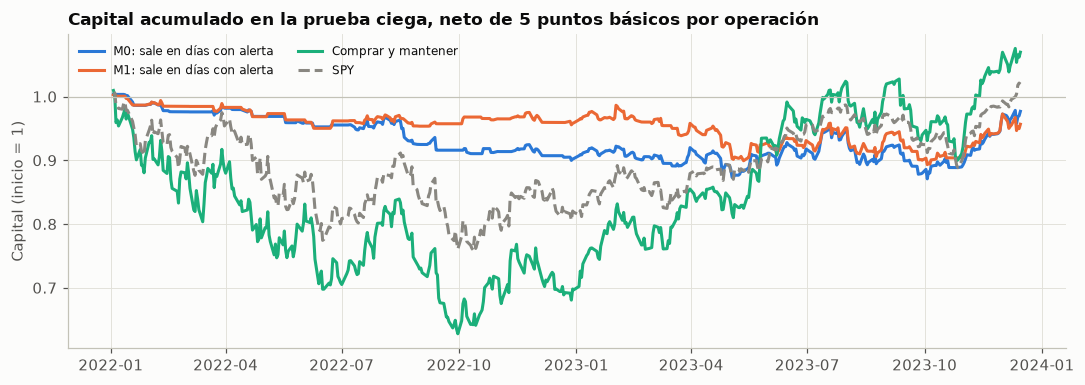

,Retorno anualizado,Volatilidad anualizada,Sharpe,Sortino,Máxima caída,Exposición media,Rotación diaria media
M0,-0.0120,0.0839,-0.1015,-0.1126,-0.1322,0.3171,0.1240
M1,-0.0225,0.0770,-0.2570,-0.2871,-0.1111,0.2923,0.1305
Comprar y mantener,0.0351,0.2871,0.2633,0.4144,-0.3780,1.0000,0.0000
SPY,0.0099,0.1964,0.1483,0.2225,-0.2450,1.0000,0.0000


Comportamiento de los días con y sin alerta:


,Observaciones,Movimiento absoluto medio (%),Desviación estándar del retorno (%),Retorno medio diario (pb)
M0 · con alerta,"1,680.0000",1.9104,2.5388,3.9788
M0 · sin alerta,780.0000,1.2059,1.6548,0.8895
M1 · con alerta,"1,741.0000",1.8959,2.5191,4.4254
M1 · sin alerta,719.0000,1.1813,1.6324,-0.4541


Sensibilidad al costo de transacción:


,Retorno anualizado,Volatilidad anualizada,Sharpe,Sortino,Máxima caída
M0 · 5 pb,-0.0120,0.0839,-0.1015,-0.1126,-0.1322
M0 · 10 pb,-0.0273,0.0840,-0.2874,-0.3195,-0.1547
M0 · 20 pb,-0.0572,0.0842,-0.6575,-0.7335,-0.1979
M1 · 5 pb,-0.0225,0.0770,-0.2570,-0.2871,-0.1111
M1 · 10 pb,-0.0384,0.0771,-0.4701,-0.5275,-0.1342
M1 · 20 pb,-0.0696,0.0773,-0.8943,-1.0106,-0.1787


In [36]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.5 · prompts: P2, P3, P6.
# Instrucción (fase 1): «Métricas de negocio (Titulación): Sharpe Ratio anualizado neto de costos (τ),
#   Sortino Ratio y Maximum Drawdown en el backtest sobre el conjunto ciego.»
# Difiere: con la tarea reformulada la estrategia es de gestión de riesgo (salir de cada acción en sus días
#   con alerta), no de compra direccional.
ret_simple = np.expm1(prueba.pivot(index="fecha", columns="ticker", values="ret"))      # sesiones x acciones


def simular(prob, costo_pb, umbral=0.5):
    """Cartera 1/5 por acción que sale de cada acción los días con alerta. Devuelve (retornos netos, exposición media, rotación media)."""
    alerta = prueba.assign(p=prob).pivot(index="fecha", columns="ticker", values="p") > umbral
    pesos = (~alerta).astype(float) / len(TICKERS)
    rotacion = pesos.diff().abs().sum(axis=1)
    rotacion.iloc[0] = pesos.iloc[0].sum()                              # costo de abrir la cartera
    neto = (pesos * ret_simple).sum(axis=1) - rotacion * costo_pb / 1e4
    return neto, pesos.sum(axis=1).mean(), rotacion.mean()


def resumen_financiero(r):
    capital = (1 + r).cumprod()
    return {"Retorno anualizado": capital.iloc[-1] ** (252 / len(r)) - 1,
            "Volatilidad anualizada": r.std() * np.sqrt(252),
            "Sharpe": r.mean() / r.std() * np.sqrt(252) if r.std() > 0 else np.nan,
            "Sortino": r.mean() / r[r < 0].std() * np.sqrt(252) if (r < 0).sum() > 1 else np.nan,
            "Máxima caída": (capital / capital.cummax() - 1).min()}


SIM = {n: simular(PROB[n], COSTO_PB) for n in ["M0", "M1"]}
SERIES = {"M0": SIM["M0"][0], "M1": SIM["M1"][0],
          "Comprar y mantener": ret_simple.mean(axis=1),
          "SPY": np.expm1(mercado["ret"].reindex(ret_simple.index))}
TABLA_FIN = pd.DataFrame({n: resumen_financiero(r) for n, r in SERIES.items()}).T
TABLA_FIN["Exposición media"] = [SIM["M0"][1], SIM["M1"][1], 1.0, 1.0]
TABLA_FIN["Rotación diaria media"] = [SIM["M0"][2], SIM["M1"][2], 0.0, 0.0]

fig, eje = plt.subplots(figsize=(10, 3.6))
for (nombre, r), color, estilo in zip(SERIES.items(), [C_ENT, C_VAL, "#1baf7a", C_REF], ["-", "-", "-", "--"]):
    etiqueta = f"{nombre}: sale en días con alerta" if nombre in ("M0", "M1") else nombre
    eje.plot(r.index, (1 + r).cumprod(), color=color, linestyle=estilo, label=etiqueta)
eje.axhline(1, color="#c3c2b7", linewidth=0.8)
eje.set_ylabel("Capital (inicio = 1)")
eje.set_title(f"Capital acumulado en la prueba ciega, neto de {COSTO_PB} puntos básicos por operación")
eje.legend(ncol=2, fontsize=8)
plt.tight_layout()
plt.show()

# ¿Los días con alerta se mueven más? Una fila por (modelo, alerta), sobre todas las observaciones de prueba.
r_obs = np.expm1(prueba["ret"].to_numpy())
ALERTAS = pd.DataFrame({
    f"{n} · {'con alerta' if hay else 'sin alerta'}": {
        "Observaciones": int(((PROB[n] > 0.5) == hay).sum()),
        "Movimiento absoluto medio (%)": 100 * np.abs(r_obs[(PROB[n] > 0.5) == hay]).mean(),
        "Desviación estándar del retorno (%)": 100 * r_obs[(PROB[n] > 0.5) == hay].std(),
        "Retorno medio diario (pb)": 1e4 * r_obs[(PROB[n] > 0.5) == hay].mean()}
    for n in ["M0", "M1"] for hay in [True, False]}).T
SENSIBILIDAD = pd.DataFrame({f"{n} · {c} pb": resumen_financiero(simular(PROB[n], c)[0])
                             for n in ["M0", "M1"] for c in [5, 10, 20]}).T
display(TABLA_FIN)
print("Comportamiento de los días con y sin alerta:")
display(ALERTAS)
print("Sensibilidad al costo de transacción:")
SENSIBILIDAD

### 7.6 ¿Aportan las noticias? Ablación en validación

La pregunta de fondo del proyecto es si el texto añade información a la que ya contienen los precios. Se responde con una **ablación**: el modelo elegido se evalúa dos veces sobre los mismos 10 pliegues de validación, con y sin todo lo derivado de noticias (sentimiento, conteo, indicador `sin_noticias` y *embeddings*). La diferencia de pérdidas por pliegue se contrasta con las mismas pruebas pareadas de la sección 7.2:

$$a_k = J^{\text{sin texto}}_k - J^{\text{con texto}}_k$$

Un valor $a_k > 0$ significa que las noticias ayudaron en ese pliegue.

Este contraste se suma al de la sección 7.2. Al leer dos pruebas principales con $\alpha = 0.05$ lo prudente es exigir $\alpha/2 = 0.025$ a cada una (Bonferroni); si ninguna rechaza $H_0$, la corrección no cambia la conclusión.

Dos precisiones: se usan los hiperparámetros del modelo completo, lo que da una pequeña ventaja a la versión con texto; y la comparación se hace en validación, no en la prueba ciega, que se reserva para el modelo elegido.

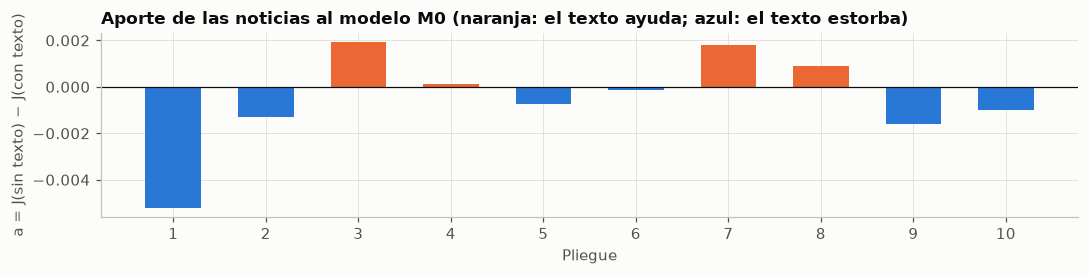

,Valor
Log-loss con texto,0.6284
Log-loss sin texto,0.6279
Diferencia media a,-0.0005
Pliegues donde el texto ayuda,4.0000
Shapiro-Wilk p,0.2205
t pareada: p,0.4444
Wilcoxon: p (exacto),0.6953


**Lectura.** La versión con noticias tiene un log-loss medio de 0.6284 y la versión solo con precios, 0.6279 (diferencia -0.0005; el texto ayuda en 4 de 10 pliegues; t pareada p = 0.4444, Wilcoxon p = 0.6953). No hay evidencia de que las noticias aporten información adicional a los precios: la capacidad predictiva proviene de las variables de precio y volumen.

In [37]:
# [Uso de IA] Celda generada con un asistente de IA · sección 7.6 · prompts: P3, P4.
# Sin instrucción en el documento: ablación de noticias añadida con P3; P4 le aplicó la regla de las dos
#   pruebas.
hp_elegido = MEJORES[MODELO_ELEGIDO]
J_CON = PERDIDA[MODELO_ELEGIDO].to_numpy()
J_SIN = perdida_por_pliegue(crear_modelo(MODELO_ELEGIDO, con_texto=False, **hp_elegido))
a = J_SIN - J_CON
_, p_shapiro_a = shapiro(a)
_, p_t_a = ttest_rel(J_SIN, J_CON)
_, p_w_a = wilcoxon(a, alternative="two-sided", method="exact")
TEXTO_AYUDA = bool(p_t_a < ALFA and p_w_a < ALFA and a.mean() > 0)     # misma regla: las dos pruebas deben respaldarlo

fig, eje = plt.subplots(figsize=(10, 2.6))
eje.bar(range(1, K_PLIEGUES + 1), a, color=[C_VAL if v > 0 else C_ENT for v in a], width=0.6)
eje.axhline(0, color="#0b0b0b", linewidth=0.8)
eje.set_xticks(range(1, K_PLIEGUES + 1))
eje.set_xlabel("Pliegue")
eje.set_ylabel("a = J(sin texto) − J(con texto)")
eje.set_title(f"Aporte de las noticias al modelo {MODELO_ELEGIDO} (naranja: el texto ayuda; azul: el texto estorba)")
plt.tight_layout()
plt.show()

display(pd.DataFrame({"Valor": [J_CON.mean(), J_SIN.mean(), a.mean(), int((a > 0).sum()), p_shapiro_a, p_t_a, p_w_a]},
                     index=["Log-loss con texto", "Log-loss sin texto", "Diferencia media a", "Pliegues donde el texto ayuda",
                            "Shapiro-Wilk p", "t pareada: p", "Wilcoxon: p (exacto)"]))
display(Markdown(
    f"**Lectura.** La versión con noticias tiene un log-loss medio de {J_CON.mean():.4f} y la versión solo con precios, "
    f"{J_SIN.mean():.4f} (diferencia {a.mean():+.4f}; el texto ayuda en {int((a > 0).sum())} de {K_PLIEGUES} pliegues; "
    f"t pareada p = {p_t_a:.4f}, Wilcoxon p = {p_w_a:.4f}). " +
    ("La mejora es estadísticamente significativa: las noticias aportan información adicional a los precios."
     if TEXTO_AYUDA else
     "No hay evidencia de que las noticias aporten información adicional a los precios: la capacidad predictiva proviene "
     "de las variables de precio y volumen.")))

## 8. Visualización con t-SNE

### 8.1 Qué se visualiza y cómo

Siguiendo el diagrama de clase, t-SNE se aplica al **espacio de características que recibe el modelo**: la salida del preprocesador ya ajustado (variables de precio y volumen filtradas, resúmenes de sentimiento, categóricas e indicador, más los componentes principales de los *embeddings*). El color de cada punto es su etiqueta.

**El método** [26]. t-SNE convierte distancias en probabilidades de vecindad. En el espacio original, la similitud entre los puntos $i$ y $j$ es una gaussiana, $p_{j|i} \propto \exp(-\lVert \mathbf{z}_i - \mathbf{z}_j\rVert^2 / 2\sigma_i^2)$; en el plano, una $t$ de Student de colas pesadas, $q_{ij} \propto (1 + \lVert \mathbf{u}_i - \mathbf{u}_j\rVert^2)^{-1}$. Las coordenadas $\mathbf{u}$ se obtienen minimizando la divergencia de Kullback-Leibler

$$\mathrm{KL}(P \,\Vert\, Q) = \sum_{i \ne j} p_{ij}\ln\frac{p_{ij}}{q_{ij}}$$

La **perplejidad** fija $\sigma_i$ y equivale al número efectivo de vecinos de cada punto; se usa 30.

**Tres advertencias de lectura.**

- t-SNE **no tiene `.transform()`**: no aprende una función, optimiza directamente las coordenadas de los puntos que recibe. Por eso se aplica solo a los datos de desarrollo. Proyectar el conjunto de prueba exigiría ajustarlo junto con él.
- Conserva vecindades locales. Ni la distancia entre grupos ni su tamaño en el plano son interpretables.
- Es una herramienta de exploración: sus coordenadas no entran en ningún modelo.

Se muestran tres coloraciones del mismo mapa: la **etiqueta** (lo que pide la rúbrica), el **régimen de volatilidad** (terciles de `vol_21`) y la **acción**. Las dos últimas permiten ver qué estructura sí existe en el espacio aunque no sea la de la etiqueta.

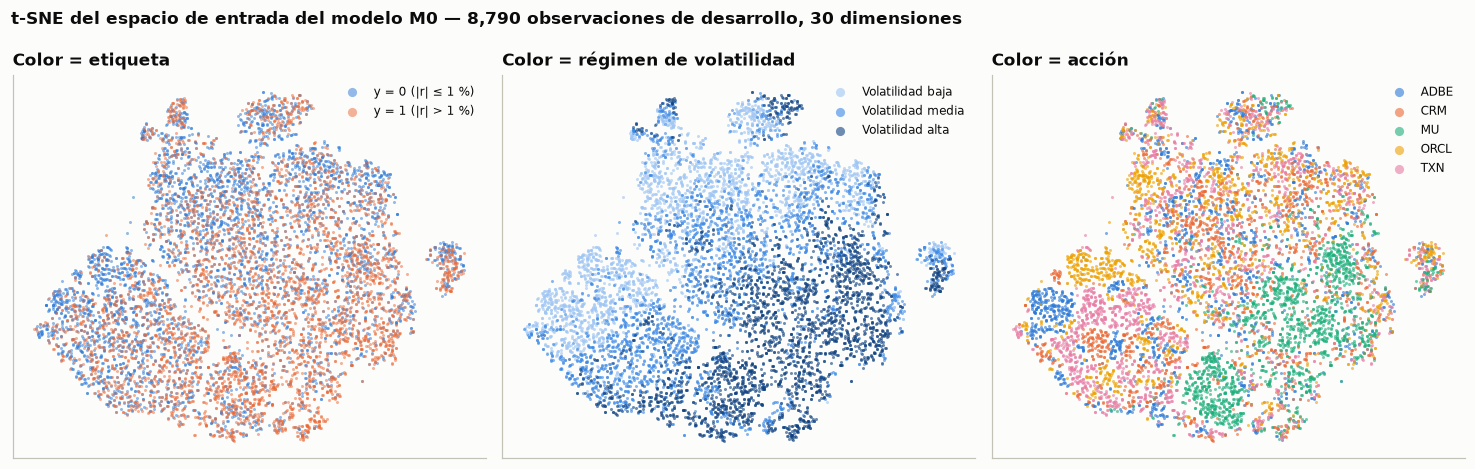

Divergencia KL final: 2.327


,Pureza de vecindad,Esperada por azar,Diferencia
Etiqueta,0.5550,0.5010,0.0540
Régimen de volatilidad,0.6760,0.3333,0.3427
Acción,0.4983,0.2000,0.2983


In [38]:
# [Uso de IA] Celda generada con un asistente de IA · sección 8.1 · prompts: P2, P3.
# Instrucción (fase 7): «Ubicación en el Pipeline: Inyectar la proyección 2D justo antes del clasificador
#   […].»
#   «Aislamiento estricto: Ajustar los proyectores exclusivamente en X_train y transformar pasivamente
#   validación y test. Aclarar que en t-SNE estándar la proyección se ilustra en el conjunto de
#   entrenamiento por carecer de `.transform()` fuera de muestra.»
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors


def pureza_vecindad(puntos, etiquetas, k=30):
    """Fracción media de los k vecinos más cercanos que comparten la etiqueta del punto, y su valor esperado por azar."""
    etiquetas = np.asarray(etiquetas)
    vecinos = NearestNeighbors(n_neighbors=k + 1).fit(puntos).kneighbors(puntos, return_distance=False)[:, 1:]
    pureza = (etiquetas[vecinos] == etiquetas[:, None]).mean()
    azar = sum((etiquetas == c).mean() ** 2 for c in np.unique(etiquetas))
    return pureza, azar


preprocesador = FINALES[MODELO_ELEGIDO].named_steps["pre"]          # ya ajustado solo con desarrollo
Z_des = preprocesador.transform(X_des.iloc[i_final])
y_tsne = y_des[i_final]
info_tsne = desarrollo.iloc[i_final]
regimen = pd.qcut(info_tsne["vol_21"], 3, labels=["Baja", "Media", "Alta"]).astype(str).to_numpy()
accion = info_tsne["ticker"].to_numpy()

tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEMILLA)
U = tsne.fit_transform(Z_des)

fig, ejes = plt.subplots(1, 3, figsize=(13.5, 4.3))
for clase, color, nombre in [(0, C_ENT, "y = 0 (|r| ≤ 1 %)"), (1, C_VAL, "y = 1 (|r| > 1 %)")]:
    m = y_tsne == clase
    ejes[0].scatter(U[m, 0], U[m, 1], s=4, alpha=0.5, color=color, label=nombre, linewidths=0)
ejes[0].set_title("Color = etiqueta")
for nivel, color in zip(["Baja", "Media", "Alta"], SECUENCIAL):
    m = regimen == nivel
    ejes[1].scatter(U[m, 0], U[m, 1], s=4, alpha=0.6, color=color, label=f"Volatilidad {nivel.lower()}", linewidths=0)
ejes[1].set_title("Color = régimen de volatilidad")
for t in TICKERS:
    m = accion == t
    ejes[2].scatter(U[m, 0], U[m, 1], s=4, alpha=0.6, color=COLOR_TICKER[t], label=t, linewidths=0)
ejes[2].set_title("Color = acción")
for eje in ejes:
    eje.set_xticks([])
    eje.set_yticks([])
    eje.grid(False)
    eje.legend(fontsize=8, markerscale=3, loc="best")
fig.suptitle(f"t-SNE del espacio de entrada del modelo {MODELO_ELEGIDO} — {len(U):,} observaciones de desarrollo, "
             f"{Z_des.shape[1]} dimensiones", x=0.01, ha="left", fontsize=11, fontweight="bold")
plt.tight_layout()
plt.show()

PUREZA = pd.DataFrame({nombre: dict(zip(["Pureza de vecindad", "Esperada por azar"], pureza_vecindad(U, etq)))
                       for nombre, etq in [("Etiqueta", y_tsne), ("Régimen de volatilidad", regimen), ("Acción", accion)]}).T
PUREZA["Diferencia"] = PUREZA["Pureza de vecindad"] - PUREZA["Esperada por azar"]
TASA_REGIMEN = pd.Series(y_tsne).groupby(regimen).mean()            # P(y = 1) en cada régimen de volatilidad
print(f"Divergencia KL final: {tsne.kl_divergence_:.3f}")
PUREZA

### 8.2 Contraste lineal con PCA

PCA sí aprende una función: $\mathbf{u} = \mathbf{W}_2^\top(\mathbf{z} - \boldsymbol{\mu})$, donde $\mathbf{W}_2$ contiene las dos direcciones de mayor varianza. Eso permite **ajustarlo en desarrollo y proyectar la prueba** sin fuga. Sirve para dos comprobaciones:

- Si la estructura que muestra t-SNE es no lineal, PCA no la verá.
- Si la nube de prueba cae en la misma región que la de desarrollo, la distribución de las entradas no cambió de forma drástica entre períodos.

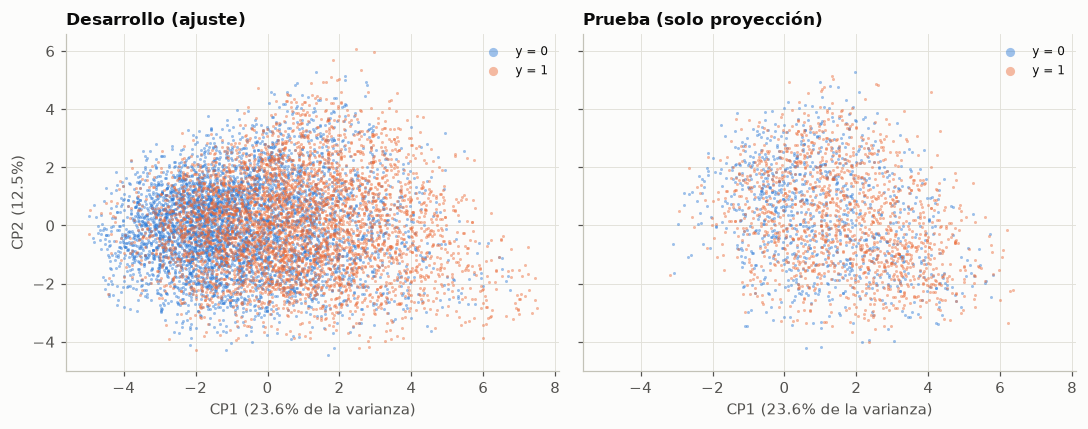

Varianza explicada por las 2 componentes: 36.1%
Pureza de vecindad de la etiqueta en el plano PCA (desarrollo): 0.553 | esperada por azar: 0.501
Pureza de vecindad de la etiqueta en el plano PCA (prueba): 0.530 | esperada por azar: 0.517


In [39]:
# [Uso de IA] Celda generada con un asistente de IA · sección 8.2 · prompts: P2, P3.
# Instrucción (fase 7): «Proyecciones comparativas: PCA (Lineal): Varianza explicada acumulada y cargas
#   factoriales. t-SNE / UMAP (No Lineal): Mapeo de variedades.»
# Difiere: no se usa UMAP ni se muestran las cargas factoriales.
pca_2d = PCA(n_components=2, random_state=SEMILLA).fit(Z_des)       # ajuste SOLO con desarrollo
P_des, P_pru = pca_2d.transform(Z_des), pca_2d.transform(preprocesador.transform(X_pru))

fig, ejes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)
for eje, puntos, etiquetas, titulo in [(ejes[0], P_des, y_tsne, "Desarrollo (ajuste)"),
                                       (ejes[1], P_pru, y_pru, "Prueba (solo proyección)")]:
    for clase, color, nombre in [(0, C_ENT, "y = 0"), (1, C_VAL, "y = 1")]:
        m = etiquetas == clase
        eje.scatter(puntos[m, 0], puntos[m, 1], s=4, alpha=0.45, color=color, label=nombre, linewidths=0)
    eje.set_title(titulo)
    eje.set_xlabel(f"CP1 ({pca_2d.explained_variance_ratio_[0]:.1%} de la varianza)")
    eje.legend(fontsize=8, markerscale=3)
ejes[0].set_ylabel(f"CP2 ({pca_2d.explained_variance_ratio_[1]:.1%})")
plt.tight_layout()
plt.show()
PUREZA_PCA = {nombre: pureza_vecindad(puntos, etq) for nombre, puntos, etq in
              [("desarrollo", P_des, y_tsne), ("prueba", P_pru, y_pru)]}
print(f"Varianza explicada por las 2 componentes: {pca_2d.explained_variance_ratio_.sum():.1%}")
for nombre, (pureza, azar) in PUREZA_PCA.items():
    print(f"Pureza de vecindad de la etiqueta en el plano PCA ({nombre}): {pureza:.3f} | esperada por azar: {azar:.3f}")

### 8.3 Interpretación

t-SNE preserva vecindades, así que la separación se mide con la **pureza de vecindad**: para cada punto, la fracción de sus 30 vecinos más cercanos en el plano que tiene su misma etiqueta. Se compara con el valor esperado si las etiquetas estuvieran repartidas al azar, $\sum_c \pi_c^2$, donde $\pi_c$ es la proporción de la clase $c$. Una diferencia cercana a 0 indica mezcla total; cuanto mayor, más concentrada está cada clase en zonas propias del mapa.

La celda redacta la lectura con los valores obtenidos.

In [40]:
# [Uso de IA] Celda generada con un asistente de IA · sección 8.3 · prompts: P2, P3.
# Instrucción (fase 7): «Interpretación de regímenes: Visualizar clusters correspondientes a regímenes de
#   mercado (Bullish, Bearish, Alta Volatilidad / Pánico).»
# Difiere: los regímenes son terciles de volatilidad (baja, media, alta), no alcista, bajista y pánico.
def describir(diferencia):
    return "estructura clara" if diferencia > 0.10 else "estructura parcial" if diferencia > 0.03 else "sin estructura"


def linea(nombre):
    f = PUREZA.loc[nombre]
    return (f"pureza = {f['Pureza de vecindad']:.3f} frente a {f['Esperada por azar']:.3f} por azar "
            f"(diferencia {f['Diferencia']:+.3f}: {describir(f['Diferencia'])})")


d_etq = PUREZA.loc["Etiqueta", "Diferencia"]
lectura = [
    f"- **Etiqueta:** {linea('Etiqueta')}. " +
    ("Los días de movimiento grande se concentran en ciertas zonas del mapa: hay regiones del espacio de entrada donde "
     "una clase es mayoritaria, que es lo que el modelo aprovecha. Las clases siguen solapándose, lo que explica que la "
     "exactitud quede lejos del 100 %." if d_etq > 0.03 else
     "Las dos clases aparecen mezcladas en todo el mapa: ninguna vecindad del espacio de entrada es mayoritariamente de "
     "una clase."),
    f"- **Régimen de volatilidad:** {linea('Régimen de volatilidad')}.",
    f"- **Acción:** {linea('Acción')}.",
    f"- **Relación entre régimen y etiqueta:** la proporción de días de movimiento grande es {TASA_REGIMEN['Baja']:.2f} en "
    f"el régimen de volatilidad baja, {TASA_REGIMEN['Media']:.2f} en el medio y {TASA_REGIMEN['Alta']:.2f} en el alto. " +
    ("El mapa se organiza sobre todo por el régimen de volatilidad y la etiqueta hereda esa estructura."
     if PUREZA.loc["Régimen de volatilidad", "Diferencia"] > d_etq else
     "La etiqueta está al menos tan estructurada en el mapa como el régimen de volatilidad."),
    f"- **Contraste lineal:** en el plano de PCA la pureza de la etiqueta es {PUREZA_PCA['desarrollo'][0]:.3f} en desarrollo "
    f"y {PUREZA_PCA['prueba'][0]:.3f} en la prueba (azar: {PUREZA_PCA['desarrollo'][1]:.3f} y {PUREZA_PCA['prueba'][1]:.3f}).",
]
display(Markdown("\n".join(lectura)))

- **Etiqueta:** pureza = 0.555 frente a 0.501 por azar (diferencia +0.054: estructura parcial). Los días de movimiento grande se concentran en ciertas zonas del mapa: hay regiones del espacio de entrada donde una clase es mayoritaria, que es lo que el modelo aprovecha. Las clases siguen solapándose, lo que explica que la exactitud quede lejos del 100 %.
- **Régimen de volatilidad:** pureza = 0.676 frente a 0.333 por azar (diferencia +0.343: estructura clara).
- **Acción:** pureza = 0.498 frente a 0.200 por azar (diferencia +0.298: estructura clara).
- **Relación entre régimen y etiqueta:** la proporción de días de movimiento grande es 0.33 en el régimen de volatilidad baja, 0.47 en el medio y 0.63 en el alto. El mapa se organiza sobre todo por el régimen de volatilidad y la etiqueta hereda esa estructura.
- **Contraste lineal:** en el plano de PCA la pureza de la etiqueta es 0.553 en desarrollo y 0.530 en la prueba (azar: 0.501 y 0.517).

## 9. Conclusiones

Las conclusiones se redactan con los resultados de esta ejecución. Cada afirmación remite a la celda que la sustenta.

In [41]:
# [Uso de IA] Celda generada con un asistente de IA · sección 9 · prompts: P2, P3, P4, P5, P6.
# Instrucción (fase 8): «Conclusiones: Conclusiones empíricas basadas en los resultados observados, no citas
#   teóricas.»
# El texto se arma con los valores calculados, para que coincida siempre con las salidas.
m0, m1, ref = TABLA_PRUEBA.loc["M0"], TABLA_PRUEBA.loc["M1"], TABLA_PRUEBA.loc["Sin habilidad"]
elegido = TABLA_PRUEBA.loc[MODELO_ELEGIDO]
cv = {n: RESULTADOS_CV[n].mean() for n in RESULTADOS_CV}
supera_cv = PERDIDA[MODELO_ELEGIDO].mean() < min(SIN_HABILIDAD.mean(), REF_ACCION.mean()) - UMBRAL_VENTAJA
ref_accion = TABLA_PRUEBA.loc["Tasa base por acción"]
supera_prueba = elegido["Log-loss"] < min(ref["Log-loss"], ref_accion["Log-loss"]) - UMBRAL_VENTAJA
fin = TABLA_FIN
mejora_sharpe = fin.loc[MODELO_ELEGIDO, "Sharpe"] > fin.loc["Comprar y mantener", "Sharpe"]
alerta_fila = ALERTAS.loc[f"{MODELO_ELEGIDO} · con alerta"]
calma_fila = ALERTAS.loc[f"{MODELO_ELEGIDO} · sin alerta"]
c_sh = CONTRASTE_REF.loc[(MODELO_ELEGIDO, "Sin habilidad")]
c_ac = CONTRASTE_REF.loc[(MODELO_ELEGIDO, "Tasa base por acción")]
ic_auc = IC_PRUEBA.loc[f"AUC {MODELO_ELEGIDO}"]
c_bs = CONTRASTE_REF.loc[(MODELO_ELEGIDO, "Baseline simple")]
bs_pru = TABLA_PRUEBA.loc["Baseline simple"]

conclusiones = [
    f"1. **Datos (2.3, 2.5).** El {p_global:.1%} de las sesiones de desarrollo tuvo un movimiento absoluto superior al "
    f"{UMBRAL:.0%}, con clases casi balanceadas en conjunto pero muy distintas entre años (de {p_anio.min():.2f} a "
    f"{p_anio.max():.2f}). El retorno casi no se autocorrelaciona (rezago 1: {acf_ret[0]:+.2f}), mientras que su valor "
    f"absoluto sí (rezago 1: {acf_abs[0]:+.2f}; rezago 5: {acf_abs[4]:+.2f}): la magnitud es predecible, la dirección no.",

    f"2. **Capacidad predictiva en validación (6.2, 7.1).** M0 obtuvo un log-loss medio de {PERDIDA['M0'].mean():.4f} y M1 "
    f"de {PERDIDA['M1'].mean():.4f}, frente a {SIN_HABILIDAD.mean():.4f} de la referencia sin habilidad y "
    f"{REF_ACCION.mean():.4f} de la tasa base por acción; el baseline simple, sin optimizar, obtuvo {BASELINE_CV.mean():.4f}. "
    f"En exactitud, "
    f"M0 = {cv['M0']['exactitud']:.3f} y M1 = {cv['M1']['exactitud']:.3f}, frente a {EXACTITUD_BASE.mean():.3f} de predecir "
    f"siempre la clase mayoritaria; el AUC es {cv['M0']['auc']:.3f} y {cv['M1']['auc']:.3f}. " +
    (f"El modelo elegido aprende un patrón real: supera a las dos referencias en {c_sh['Pliegues ganados']} y "
     f"{c_ac['Pliegues ganados']} de {K_PLIEGUES} pliegues (Wilcoxon: {p_txt(c_sh['Wilcoxon p'])} y {p_txt(c_ac['Wilcoxon p'])}). "
     f"Sobre el baseline simple su ganancia es de {c_bs['Ganancia media']:+.4f} nats, en {c_bs['Pliegues ganados']} de {K_PLIEGUES} "
     f"pliegues (t pareada: {p_txt(c_bs['t pareada p'])}; Wilcoxon: {p_txt(c_bs['Wilcoxon p'])})."
     if supera_cv else
     f"El modelo elegido no mejora la referencia por más del margen fijado ({UMBRAL_VENTAJA} nats)."),

    f"3. **Sesgo y varianza (6.4, 6.5).** M0: {DIAGNOSTICO['M0']['regimen']}. M1: {DIAGNOSTICO['M1']['regimen']}.",

    f"4. **Comparación estadística (7.2, 7.3).** Con {K_PLIEGUES} pliegues pareados, la t de Student pareada dio "
    f"p = {p_t:.4f} y Wilcoxon p = {p_w:.4f} (Shapiro-Wilk sobre las diferencias: p = {p_shapiro:.3f}). " +
    (f"Las dos pruebas rechazan H0: la diferencia es significativa a favor de {GANADOR} (d de Cohen = {d_cohen:+.2f}), que "
     "se adopta como modelo final." if SIGNIFICATIVO else
     "Las dos pruebas coinciden en no rechazar H0: no hay diferencia significativa entre la regresión logística y el "
     "boosting, la no linealidad no aportó una mejora demostrable y se conserva el modelo más simple." if COINCIDEN else
     "Las dos pruebas no coinciden, así que el resultado no es concluyente: no se afirma una diferencia y se conserva el "
     "modelo más simple."),

    f"5. **Prueba ciega (7.4).** En {prueba['fecha'].min().year}–{prueba['fecha'].max().year}, {MODELO_ELEGIDO} obtuvo "
    f"log-loss = {elegido['Log-loss']:.4f} (sin habilidad: {ref['Log-loss']:.4f}; tasa base por acción: "
    f"{ref_accion['Log-loss']:.4f}; tasa base de la propia prueba, que solo se conoce después: "
    f"{TABLA_PRUEBA.loc['Tasa base de la prueba (a posteriori)', 'Log-loss']:.4f}) y AUC = {elegido['AUC-ROC']:.3f}. "
    f"Su exactitud fue {elegido['Exactitud']:.3f}; predecir la "
    f"clase mayoritaria del entrenamiento habría dado {ref['Exactitud']:.3f}, y la de la propia prueba, que solo se conoce "
    f"después, {EXACTITUD_MAYORIA_PRUEBA:.3f}. El intervalo de 95 % de su AUC, por remuestreo de bloques, es "
    f"[{ic_auc['2.5 %']:.3f}, {ic_auc['97.5 %']:.3f}]. El baseline simple obtuvo en la misma prueba un log-loss de "
    f"{bs_pru['Log-loss']:.4f} y un AUC de {bs_pru['AUC-ROC']:.3f}" +
    (": prácticamente lo mismo que el modelo elegido, de modo que fuera de muestra la optimización, el filtro y las noticias no "
     "aportaron sobre lo más simple. " if abs(bs_pru["Log-loss"] - elegido["Log-loss"]) < UMBRAL_VENTAJA else ". ") +
    f"Sensibilidad "
    f"{elegido['Sensibilidad']:.3f} y precisión {elegido['Precisión']:.3f}. " +
    ("El resultado fuera de muestra confirma el de validación." if supera_prueba and supera_cv else
     "El resultado fuera de muestra no confirma el de validación: la ventaja observada no es estable en el tiempo."
     if supera_cv else "El resultado fuera de muestra coincide con el de validación: no hay ventaja sobre la referencia."),

    f"6. **Valor para la gestión de riesgo (7.5).** En la prueba, los días con alerta de {MODELO_ELEGIDO} tuvieron un "
    f"movimiento absoluto medio de {alerta_fila['Movimiento absoluto medio (%)']:.2f} %, frente a "
    f"{calma_fila['Movimiento absoluto medio (%)']:.2f} % de los días sin alerta. Salir de cada acción en sus días con alerta "
    f"dejó una volatilidad anualizada de {fin.loc[MODELO_ELEGIDO, 'Volatilidad anualizada']:.1%} y una máxima caída de "
    f"{fin.loc[MODELO_ELEGIDO, 'Máxima caída']:.1%}, frente a {fin.loc['Comprar y mantener', 'Volatilidad anualizada']:.1%} y "
    f"{fin.loc['Comprar y mantener', 'Máxima caída']:.1%} de comprar y mantener, con un Sharpe neto de "
    f"{fin.loc[MODELO_ELEGIDO, 'Sharpe']:.2f} frente a {fin.loc['Comprar y mantener', 'Sharpe']:.2f}. " +
    ("La estrategia mejora también el Sharpe: los días evitados tenían peor relación entre retorno y riesgo."
     if mejora_sharpe else
     "La estrategia reduce el riesgo pero no mejora el Sharpe: el modelo sirve para acotar la exposición a días agitados, "
     "no para aumentar el retorno ajustado por riesgo."),

    f"7. **Aporte de las noticias (7.6).** Con texto el log-loss de validación es {J_CON.mean():.4f}; sin texto, "
    f"{J_SIN.mean():.4f} (t pareada p = {p_t_a:.4f}; Wilcoxon p = {p_w_a:.4f}). " +
    ("Las noticias aportan información adicional a los precios." if TEXTO_AYUDA else
     "No hay evidencia de que las noticias aporten información adicional: la señal proviene de las variables de precio y volumen."),

    f"8. **Representación (8).** En el mapa t-SNE la pureza de vecindad de la etiqueta es "
    f"{PUREZA.loc['Etiqueta', 'Pureza de vecindad']:.3f} frente a {PUREZA.loc['Etiqueta', 'Esperada por azar']:.3f} esperada "
    f"por azar; la del régimen de volatilidad, {PUREZA.loc['Régimen de volatilidad', 'Pureza de vecindad']:.3f} frente a "
    f"{PUREZA.loc['Régimen de volatilidad', 'Esperada por azar']:.3f}.",

    "9. **Limitaciones.** (i) FNSPID solo registra la fecha de cada noticia, lo que obligó a retrasar su uso una sesión "
    "completa y pudo diluir su señal. (ii) La cobertura de noticias crece con los años, así que la rama de texto no es "
    "homogénea en el tiempo. (iii) Los pliegues cronológicos se solapan y los hiperparámetros se eligieron con los mismos "
    "pliegues de la comparación, por lo que los p-valores son aproximados. (iv) El universo son cinco acciones de un solo "
    "sector. (v) Una primera formulación del proyecto usaba como etiqueta la dirección del retorno (r > 5 puntos básicos). "
    "Se ejecutó completa, incluida la prueba ciega, y no superó la referencia (exactitud de 0.49). La tarea se reformuló a "
    "partir de la persistencia de la volatilidad que muestra el EDA y se verificó solo con datos de desarrollo; el período "
    "2022–2023 no intervino en la elección de la nueva tarea, de sus variables ni de sus hiperparámetros, aunque ya había "
    "sido evaluado una vez con la etiqueta anterior. (vi) Tras la primera evaluación con la tarea actual, la libreta se "
    "reejecutó varias veces por ajustes de auditoría que no dependían del resultado de la prueba: sacar del filtro las "
    "variables derivadas de FinBERT, quitar un ajuste ilustrativo del EDA y cambios de redacción y presentación. En ese "
    "proceso el log-loss de prueba del modelo elegido pasó de 0.6666 a 0.6659. No se cambió ningún hiperparámetro ni "
    "variable a la vista de ese resultado. (vii) El umbral del 1 % es el mismo para todas las acciones, de modo que la "
    "etiqueta refleja en parte qué acción es más volátil; por eso se compara contra la tasa base por acción. (viii) La "
    "evaluación económica supone que el efectivo no rinde nada, lo que perjudica a una estrategia que pasa la mayor parte "
    "del tiempo fuera del mercado en un período de tasas altas.",
]
display(Markdown("\n\n".join(conclusiones)))

1. **Datos (2.3, 2.5).** El 47.7% de las sesiones de desarrollo tuvo un movimiento absoluto superior al 1%, con clases casi balanceadas en conjunto pero muy distintas entre años (de 0.30 a 0.62). El retorno casi no se autocorrelaciona (rezago 1: -0.14), mientras que su valor absoluto sí (rezago 1: +0.25; rezago 5: +0.19): la magnitud es predecible, la dirección no.

2. **Capacidad predictiva en validación (6.2, 7.1).** M0 obtuvo un log-loss medio de 0.6284 y M1 de 0.6368, frente a 0.6978 de la referencia sin habilidad y 0.6770 de la tasa base por acción; el baseline simple, sin optimizar, obtuvo 0.6402. En exactitud, M0 = 0.653 y M1 = 0.643, frente a 0.494 de predecir siempre la clase mayoritaria; el AUC es 0.680 y 0.668. El modelo elegido aprende un patrón real: supera a las dos referencias en 10 y 10 de 10 pliegues (Wilcoxon: p = 0.0020 y p = 0.0020). Sobre el baseline simple su ganancia es de +0.0118 nats, en 8 de 10 pliegues (t pareada: p = 0.0070; Wilcoxon: p = 0.0098).

3. **Sesgo y varianza (6.4, 6.5).** M0: supera la referencia, pero con varianza: la pérdida de entrenamiento queda claramente por debajo de la de validación. Más datos o más regularización reducirían la brecha. M1: supera la referencia, pero con varianza: la pérdida de entrenamiento queda claramente por debajo de la de validación. Más datos o más regularización reducirían la brecha.

4. **Comparación estadística (7.2, 7.3).** Con 10 pliegues pareados, la t de Student pareada dio p = 0.0909 y Wilcoxon p = 0.0840 (Shapiro-Wilk sobre las diferencias: p = 0.059). Las dos pruebas coinciden en no rechazar H0: no hay diferencia significativa entre la regresión logística y el boosting, la no linealidad no aportó una mejora demostrable y se conserva el modelo más simple.

5. **Prueba ciega (7.4).** En 2022–2023, M0 obtuvo log-loss = 0.6659 (sin habilidad: 0.7023; tasa base por acción: 0.7103; tasa base de la propia prueba, que solo se conoce después: 0.6762) y AUC = 0.609. Su exactitud fue 0.605; predecir la clase mayoritaria del entrenamiento habría dado 0.408, y la de la propia prueba, que solo se conoce después, 0.592. El intervalo de 95 % de su AUC, por remuestreo de bloques, es [0.578, 0.635]. El baseline simple obtuvo en la misma prueba un log-loss de 0.6665 y un AUC de 0.610: prácticamente lo mismo que el modelo elegido, de modo que fuera de muestra la optimización, el filtro y las noticias no aportaron sobre lo más simple. Sensibilidad 0.743 y precisión 0.644. El resultado fuera de muestra confirma el de validación.

6. **Valor para la gestión de riesgo (7.5).** En la prueba, los días con alerta de M0 tuvieron un movimiento absoluto medio de 1.91 %, frente a 1.21 % de los días sin alerta. Salir de cada acción en sus días con alerta dejó una volatilidad anualizada de 8.4% y una máxima caída de -13.2%, frente a 28.7% y -37.8% de comprar y mantener, con un Sharpe neto de -0.10 frente a 0.26. La estrategia reduce el riesgo pero no mejora el Sharpe: el modelo sirve para acotar la exposición a días agitados, no para aumentar el retorno ajustado por riesgo.

7. **Aporte de las noticias (7.6).** Con texto el log-loss de validación es 0.6284; sin texto, 0.6279 (t pareada p = 0.4444; Wilcoxon p = 0.6953). No hay evidencia de que las noticias aporten información adicional: la señal proviene de las variables de precio y volumen.

8. **Representación (8).** En el mapa t-SNE la pureza de vecindad de la etiqueta es 0.555 frente a 0.501 esperada por azar; la del régimen de volatilidad, 0.676 frente a 0.333.

9. **Limitaciones.** (i) FNSPID solo registra la fecha de cada noticia, lo que obligó a retrasar su uso una sesión completa y pudo diluir su señal. (ii) La cobertura de noticias crece con los años, así que la rama de texto no es homogénea en el tiempo. (iii) Los pliegues cronológicos se solapan y los hiperparámetros se eligieron con los mismos pliegues de la comparación, por lo que los p-valores son aproximados. (iv) El universo son cinco acciones de un solo sector. (v) Una primera formulación del proyecto usaba como etiqueta la dirección del retorno (r > 5 puntos básicos). Se ejecutó completa, incluida la prueba ciega, y no superó la referencia (exactitud de 0.49). La tarea se reformuló a partir de la persistencia de la volatilidad que muestra el EDA y se verificó solo con datos de desarrollo; el período 2022–2023 no intervino en la elección de la nueva tarea, de sus variables ni de sus hiperparámetros, aunque ya había sido evaluado una vez con la etiqueta anterior. (vi) Tras la primera evaluación con la tarea actual, la libreta se reejecutó varias veces por ajustes de auditoría que no dependían del resultado de la prueba: sacar del filtro las variables derivadas de FinBERT, quitar un ajuste ilustrativo del EDA y cambios de redacción y presentación. En ese proceso el log-loss de prueba del modelo elegido pasó de 0.6666 a 0.6659. No se cambió ningún hiperparámetro ni variable a la vista de ese resultado. (vii) El umbral del 1 % es el mismo para todas las acciones, de modo que la etiqueta refleja en parte qué acción es más volátil; por eso se compara contra la tasa base por acción. (viii) La evaluación económica supone que el efectivo no rinde nada, lo que perjudica a una estrategia que pasa la mayor parte del tiempo fuera del mercado en un período de tasas altas.

## 10. Referencias

Formato IEEE, numeradas por orden de primera cita.

[1] R. F. Engle, "Autoregressive conditional heteroscedasticity with estimates of the variance of United Kingdom inflation," *Econometrica*, vol. 50, no. 4, pp. 987–1007, 1982.

[2] R. Cont, "Empirical properties of asset returns: Stylized facts and statistical issues," *Quantitative Finance*, vol. 1, no. 2, pp. 223–236, 2001.

[3] T. M. Mitchell, *Machine Learning*. New York, NY, USA: McGraw-Hill, 1997.

[4] Z. Dong, X. Fan, and Z. Peng, "FNSPID: A comprehensive financial news dataset in time series," *arXiv preprint* arXiv:2402.06698, 2024.

[5] D. Araci, "FinBERT: Financial sentiment analysis with pre-trained language models," *arXiv preprint* arXiv:1908.10063, 2019.

[6] R. Aroussi, "yfinance: Download market data from Yahoo! Finance's API," GitHub. [En línea]. Disponible: https://github.com/ranaroussi/yfinance

[7] S. Seabold and J. Perktold, "Statsmodels: Econometric and statistical modeling with Python," in *Proc. 9th Python in Science Conf.*, 2010, pp. 92–96.

[8] D. A. Dickey and W. A. Fuller, "Distribution of the estimators for autoregressive time series with a unit root," *J. Amer. Statist. Assoc.*, vol. 74, no. 366, pp. 427–431, 1979.

[9] D. Kwiatkowski, P. C. B. Phillips, P. Schmidt, and Y. Shin, "Testing the null hypothesis of stationarity against the alternative of a unit root," *J. Econometrics*, vol. 54, no. 1–3, pp. 159–178, 1992.

[10] I.-K. Yeo and R. A. Johnson, "A new family of power transformations to improve normality or symmetry," *Biometrika*, vol. 87, no. 4, pp. 954–959, 2000.

[11] M. B. Garman and M. J. Klass, "On the estimation of security price volatilities from historical data," *J. Business*, vol. 53, no. 1, pp. 67–78, 1980.

[12] J. Devlin, M.-W. Chang, K. Lee, and K. Toutanova, "BERT: Pre-training of deep bidirectional transformers for language understanding," in *Proc. NAACL-HLT*, 2019, pp. 4171–4186.

[13] T. Wolf *et al.*, "Transformers: State-of-the-art natural language processing," in *Proc. EMNLP: System Demonstrations*, 2020, pp. 38–45.

[14] scikit-learn developers, "sklearn.model_selection.TimeSeriesSplit," *scikit-learn API Reference*. [En línea]. Disponible: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.TimeSeriesSplit.html

[15] M. López de Prado, *Advances in Financial Machine Learning*. Hoboken, NJ, USA: Wiley, 2018.

[16] F. Pedregosa *et al.*, "Scikit-learn: Machine learning in Python," *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[17] scikit-learn developers, "Feature selection," *scikit-learn User Guide*. [En línea]. Disponible: https://scikit-learn.org/stable/modules/feature_selection.html

[18] H. Zou and T. Hastie, "Regularization and variable selection via the elastic net," *J. Roy. Statist. Soc. B*, vol. 67, no. 2, pp. 301–320, 2005.

[19] G. Ke *et al.*, "LightGBM: A highly efficient gradient boosting decision tree," in *Advances in Neural Information Processing Systems 30*, 2017, pp. 3146–3154.

[20] T. Akiba, S. Sano, T. Yanase, T. Ohta, and M. Koyama, "Optuna: A next-generation hyperparameter optimization framework," in *Proc. 25th ACM SIGKDD Int. Conf. Knowl. Discovery Data Mining*, 2019, pp. 2623–2631.

[21] J. Bergstra, R. Bardenet, Y. Bengio, and B. Kégl, "Algorithms for hyper-parameter optimization," in *Advances in Neural Information Processing Systems 24*, 2011, pp. 2546–2554.

[22] A. Ng, *Machine Learning Yearning*. deeplearning.ai, 2018.

[23] S. S. Shapiro and M. B. Wilk, "An analysis of variance test for normality (complete samples)," *Biometrika*, vol. 52, no. 3/4, pp. 591–611, 1965.

[24] F. Wilcoxon, "Individual comparisons by ranking methods," *Biometrics Bull.*, vol. 1, no. 6, pp. 80–83, 1945.

[25] P. Virtanen *et al.*, "SciPy 1.0: Fundamental algorithms for scientific computing in Python," *Nature Methods*, vol. 17, pp. 261–272, 2020.

[26] L. van der Maaten and G. Hinton, "Visualizing data using t-SNE," *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.

### Declaración de uso de IA

**Herramienta.** Un asistente de IA, en una sesión de trabajo con acceso a los archivos del proyecto.

**Qué generó la IA.** El código de todas las celdas, a partir del documento de implementación del proyecto y de la rúbrica. También ejecutó la libreta y propuso las correcciones cuando el autor le pidió auditarla.

**Qué hizo el autor.**

- Redactó el documento de implementación (`prompt-maestro-implementacion-proyecto.md`), que especifica por fases la tarea, los datos, el particionado, los modelos, las pruebas y la visualización.
- Aprobó el índice de secciones antes de que se escribiera código.
- Decidió cambiar las cinco acciones cuando se comprobó que FNSPID no cubre 2015–2021 para las previstas.
- Decidió reformular la tarea, de la dirección del retorno a la magnitud del movimiento, cuando la primera formulación no superó la referencia sin habilidad.
- Planteó varias rondas de preguntas de auditoría contra la rúbrica y el diagrama de clase, y decidió qué correcciones aplicar.
- Verificó la solución integral de punta a punta, ajustó cálculos, valores y decisiones, y ejecutó cada sección retroalimentando al modelo según su necesidad.

**Dónde están los prompts.** Van como comentarios de Python. La primera celda de código transcribe los seis prompts que generaron o modificaron código. Cada celda de código empieza con un comentario que indica qué prompts la crearon o modificaron, cita el fragmento del documento de implementación que cumple y señala en qué se apartó de él. Los intercambios que no produjeron código no se transcriben: la lectura previa de la rúbrica y de las directrices del proyecto, y las preguntas de auditoría.

**Dónde lo construido se apartó del documento de implementación.**

| Aspecto | Documento de implementación | Esta libreta | Motivo |
|---|---|---|---|
| Acciones | AAPL, MSFT, NVDA, GOOGL, AMZN | ADBE, CRM, MU, ORCL, TXN | FNSPID no cubre 2015–2021 para las previstas |
| Ventana y prueba ciega | 2015–2024; prueba 2023–2024 | 2015–2023; prueba 2022–2023 | FNSPID termina en diciembre de 2023 |
| Etiqueta | Retorno superior a 5 puntos básicos (dirección) | Retorno absoluto superior al 1 % (magnitud) | La dirección no superó la referencia sin habilidad |
| Regla de noticias | Corte horario a las 16:00 EST | Regla por día: una noticia se usa desde el cierre de la primera sesión posterior a su fecha | FNSPID no trae la hora de publicación |
| *Baseline* | M0 (regresión logística con red elástica) | Modelo aparte, con parámetros por defecto; M0 es una de las dos técnicas optimizadas | Un *baseline* debe ser lo más simple posible |
| Prueba de hipótesis | Una sola, elegida según Shapiro-Wilk | Las dos, leídas juntas; solo se afirma diferencia si ambas rechazan | La normalidad no es concluyente con 10 pliegues |
| Curva de aprendizaje | Fracciones 20–100 %, pérdida logarítmica y 1 − F1 macro | Seis tamaños de las sesiones más recientes, solo pérdida logarítmica | Con datos ordenados en el tiempo, así solo cambia la cantidad de datos y no su antigüedad; la pérdida logarítmica es la métrica que se optimiza |
| Evaluación económica | Compras según la señal | Gestión de riesgo: salir de cada acción en sus días con alerta | Consecuencia del cambio de tarea |
| Proyección no lineal | t-SNE o UMAP | Solo t-SNE | La rúbrica pide t-SNE |

**Código adaptado.** La clase `CausalWinsorizer` se adaptó del Anexo A de la propuesta metodológica del proyecto.